<a href="https://colab.research.google.com/github/19kaokkk/Retailrocket/blob/main/L%C3%80M%20S%E1%BA%A0CH%20%2B%20EDA%20%2BML1_PH%C3%82N%20KH%C3%9AC%20KH%C3%81CH%20H%C3%80NG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# New Section

# E-commerce Recommendation System
## 01. Data Audit and Cleaning

### Research Topic
Xây dựng hệ thống gợi ý sản phẩm thương mại điện tử
dựa trên hành vi tuần tự và đa hành vi của khách hàng

### Pipeline
- ML1: Customer Segmentation
- ML2: Purchase Intention Prediction
- ML3: Sequential & Multi-Behavior Recommendation
- ML4: Federated Learning
- ML5: Privacy-Preserving Recommendation


In [2]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Đã giải nén thành công!")

Đã giải nén thành công!


In [3]:
os.listdir("/content/data")

['item_properties_part1.csv',
 'item_properties_part2.csv',
 'category_tree.csv',
 'events.csv']

In [4]:
for root, dirs, files in os.walk("/content/data"):
    for file in files:
        print(os.path.join(root, file))

/content/data/item_properties_part1.csv
/content/data/item_properties_part2.csv
/content/data/category_tree.csv
/content/data/events.csv


In [5]:
import pandas as pd
import numpy as np
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [6]:
events_path = "/content/data/events.csv"

events = pd.read_csv(events_path)

print("Đọc dữ liệu thành công!")
print("Số dòng:", events.shape[0])
print("Số cột:", events.shape[1])

Đọc dữ liệu thành công!
Số dòng: 2756101
Số cột: 5


In [7]:
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [8]:
import pandas as pd
import os

files = [
    "events.csv",
    "item_properties_part1.csv",
    "item_properties_part2.csv",
    "category_tree.csv"
]

for file in files:
    path = f"/content/data/{file}"
    df = pd.read_csv(path)
    print(f"{file}: {df.shape[0]:,} dòng × {df.shape[1]} cột")
    del df

events.csv: 2,756,101 dòng × 5 cột
item_properties_part1.csv: 10,999,999 dòng × 4 cột
item_properties_part2.csv: 9,275,903 dòng × 4 cột
category_tree.csv: 1,669 dòng × 2 cột


In [9]:
events.info()
events.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


,0
timestamp,int64
visitorid,int64
event,object
itemid,int64
transactionid,float64


In [10]:
print("Shape:", events.shape)
print("\nColumns:")
print(events.columns.tolist())

Shape: (2756101, 5)

Columns:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


In [11]:
missing = events.isnull().sum()

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing / len(events) * 100
})

missing_df

,missing_count,missing_percent
timestamp,0,0.00000
visitorid,0,0.00000
event,0,0.00000
itemid,0,0.00000
transactionid,2733644,99.18519


In [12]:
event_counts = events["event"].value_counts()

event_counts

,count
event,
view,2664312
addtocart,69332
transaction,22457


In [13]:
event_percent = (
    events["event"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

event_percent

,proportion
event,
view,96.67
addtocart,2.52
transaction,0.81


In [14]:
print("Unique users:", events["visitorid"].nunique())
print("Unique items:", events["itemid"].nunique())
print("Unique transactions:", events["transactionid"].nunique())

Unique users: 1407580
Unique items: 235061
Unique transactions: 17672


In [15]:
duplicate_count = events.duplicated().sum()

print("Số dòng trùng hoàn toàn:", duplicate_count)

Số dòng trùng hoàn toàn: 460


In [16]:
print("Timestamp nhỏ nhất:", events["timestamp"].min())
print("Timestamp lớn nhất:", events["timestamp"].max())

Timestamp nhỏ nhất: 1430622004384
Timestamp lớn nhất: 1442545187788


In [17]:
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms"
)

print("Thời gian bắt đầu:", events["datetime"].min())
print("Thời gian kết thúc:", events["datetime"].max())

Thời gian bắt đầu: 2015-05-03 03:00:04.384000
Thời gian kết thúc: 2015-09-18 02:59:47.788000


In [18]:
# ============================================
# BƯỚC 17 — TIẾP TỤC SAU KHI SỬA LỖI
# ============================================

# 17.4. Kiểm tra transactionid theo từng loại event

transaction_check = events.groupby("event").agg(
    total_rows=("transactionid", "size"),
    missing_transactionid=("transactionid", lambda x: x.isna().sum()),
    unique_transactionid=("transactionid", "nunique")
)

print("Transaction ID theo từng loại event:")
display(transaction_check)


# --------------------------------------------
# 17.5. Transaction event nhưng thiếu transactionid
# --------------------------------------------

transaction_missing = events[
    (events["event"] == "transaction") &
    (events["transactionid"].isna())
]

print(
    "\nSố transaction event nhưng transactionid bị thiếu:",
    len(transaction_missing)
)

display(transaction_missing.head(10))


# --------------------------------------------
# 17.6. View/Addtocart nhưng lại có transactionid
# --------------------------------------------

unexpected_transactionid = events[
    (events["event"].isin(["view", "addtocart"])) &
    (events["transactionid"].notna())
]

print(
    "\nSố view/addtocart nhưng lại có transactionid:",
    len(unexpected_transactionid)
)

display(unexpected_transactionid.head(10))


# --------------------------------------------
# 17.7. Kiểm tra itemid
# --------------------------------------------

print("\n========== KIỂM TRA ITEMID ==========")

print("itemid nhỏ nhất:", events["itemid"].min())
print("itemid lớn nhất:", events["itemid"].max())
print("itemid <= 0:", (events["itemid"] <= 0).sum())


# --------------------------------------------
# 17.8. Kiểm tra visitorid
# --------------------------------------------

print("\n========== KIỂM TRA VISITORID ==========")

print("visitorid nhỏ nhất:", events["visitorid"].min())
print("visitorid lớn nhất:", events["visitorid"].max())
print("visitorid <= 0:", (events["visitorid"] <= 0).sum())


# --------------------------------------------
# 17.9. Kiểm tra timestamp
# --------------------------------------------

print("\n========== KIỂM TRA TIMESTAMP ==========")

print("timestamp nhỏ nhất:", events["timestamp"].min())
print("timestamp lớn nhất:", events["timestamp"].max())
print("timestamp <= 0:", (events["timestamp"] <= 0).sum())


# --------------------------------------------
# 17.10. Kiểm tra datetime
# --------------------------------------------

# Nếu datetime chưa tồn tại thì tạo
if "datetime" not in events.columns:
    events["datetime"] = pd.to_datetime(
        events["timestamp"],
        unit="ms"
    )

print("\n========== KIỂM TRA DATETIME ==========")

print("Datetime min:", events["datetime"].min())
print("Datetime max:", events["datetime"].max())


# --------------------------------------------
# 17.11. Kiểm tra transactionid <= 0
# --------------------------------------------

invalid_transactionid = events[
    events["transactionid"].notna() &
    (events["transactionid"] <= 0)
]

print(
    "\nSố transactionid <= 0:",
    len(invalid_transactionid)
)

display(invalid_transactionid.head(10))


# --------------------------------------------
# 17.12. TỔNG HỢP
# --------------------------------------------

print("\n" + "=" * 60)
print("TỔNG HỢP KIỂM TRA BƯỚC 17")
print("=" * 60)

print("1. Duplicate hoàn toàn:", duplicate_count)
print("2. Transaction thiếu transactionid:", len(transaction_missing))
print("3. View/Addtocart có transactionid:", len(unexpected_transactionid))
print("4. itemid <= 0:", (events["itemid"] <= 0).sum())
print("5. visitorid <= 0:", (events["visitorid"] <= 0).sum())
print("6. timestamp <= 0:", (events["timestamp"] <= 0).sum())
print("7. transactionid <= 0:", len(invalid_transactionid))

Transaction ID theo từng loại event:


,total_rows,missing_transactionid,unique_transactionid
event,,,
addtocart,69332,69332,0
transaction,22457,0,17672
view,2664312,2664312,0



Số transaction event nhưng transactionid bị thiếu: 0


,timestamp,visitorid,event,itemid,transactionid,datetime



Số view/addtocart nhưng lại có transactionid: 0


,timestamp,visitorid,event,itemid,transactionid,datetime



========== KIỂM TRA ITEMID ==========
itemid nhỏ nhất: 3
itemid lớn nhất: 466867
itemid <= 0: 0

========== KIỂM TRA VISITORID ==========
visitorid nhỏ nhất: 0
visitorid lớn nhất: 1407579
visitorid <= 0: 3

========== KIỂM TRA TIMESTAMP ==========
timestamp nhỏ nhất: 1430622004384
timestamp lớn nhất: 1442545187788
timestamp <= 0: 0

========== KIỂM TRA DATETIME ==========
Datetime min: 2015-05-03 03:00:04.384000
Datetime max: 2015-09-18 02:59:47.788000

Số transactionid <= 0: 1


,timestamp,visitorid,event,itemid,transactionid,datetime
271793,1434404197081,90352,transaction,425758,0.0,2015-06-15 21:36:37.081



TỔNG HỢP KIỂM TRA BƯỚC 17
1. Duplicate hoàn toàn: 460
2. Transaction thiếu transactionid: 0
3. View/Addtocart có transactionid: 0
4. itemid <= 0: 0
5. visitorid <= 0: 3
6. timestamp <= 0: 0
7. transactionid <= 0: 1


In [19]:
# ============================================
# BƯỚC 18 — KIỂM TRA VISITORID = 0
# ============================================

visitor_zero = events[events["visitorid"] == 0].copy()

print("Số dòng visitorid = 0:", len(visitor_zero))

display(visitor_zero)
# Kiểm tra 3 dòng visitorid = 0 thuộc event nào

print("\nPhân bố event:")
print(visitor_zero["event"].value_counts())

print("\nThông tin transactionid:")
display(
    visitor_zero[
        ["timestamp", "datetime", "visitorid", "event", "itemid", "transactionid"]
    ]
)
# Kiểm tra visitorid = 0 có bị duplicate hay không

print(
    "Số dòng visitorid = 0 bị duplicate:",
    visitor_zero.duplicated().sum()
)

Số dòng visitorid = 0: 3


,timestamp,visitorid,event,itemid,transactionid,datetime
1361687,1442004589439,0,view,285930,NaN,2015-09-11 20:49:49.439
1367212,1442004759591,0,view,357564,NaN,2015-09-11 20:52:39.591
1367342,1442004917175,0,view,67045,NaN,2015-09-11 20:55:17.175



Phân bố event:
event
view    3
Name: count, dtype: int64

Thông tin transactionid:


,timestamp,datetime,visitorid,event,itemid,transactionid
1361687,1442004589439,2015-09-11 20:49:49.439,0,view,285930,NaN
1367212,1442004759591,2015-09-11 20:52:39.591,0,view,357564,NaN
1367342,1442004917175,2015-09-11 20:55:17.175,0,view,67045,NaN


Số dòng visitorid = 0 bị duplicate: 0


In [20]:
# ============================================
# BƯỚC 19 — DATA CLEANING CHÍNH THỨC
# ============================================

# Tạo bản sao dữ liệu gốc
events_clean = events.copy()

print("Số dòng ban đầu:", len(events_clean))


# --------------------------------------------
# 19.1. Xóa duplicate hoàn toàn
# --------------------------------------------

before_duplicate = len(events_clean)

events_clean = events_clean.drop_duplicates()

after_duplicate = len(events_clean)

print("\nDuplicate được xóa:",
      before_duplicate - after_duplicate)


# --------------------------------------------
# 19.2. Xóa visitorid = 0
# --------------------------------------------

before_visitor = len(events_clean)

events_clean = events_clean[
    events_clean["visitorid"] > 0
]

after_visitor = len(events_clean)

print("visitorid = 0 được xóa:",
      before_visitor - after_visitor)


# --------------------------------------------
# 19.3. Xóa transactionid <= 0
# --------------------------------------------

before_transaction = len(events_clean)

events_clean = events_clean[
    ~(
        events_clean["transactionid"].notna() &
        (events_clean["transactionid"] <= 0)
    )
]

after_transaction = len(events_clean)

print("transactionid <= 0 được xóa:",
      before_transaction - after_transaction)


# --------------------------------------------
# 19.4. Reset index
# --------------------------------------------

events_clean = events_clean.reset_index(drop=True)


# --------------------------------------------
# 19.5. Kiểm tra kết quả
# --------------------------------------------

print("\n" + "=" * 60)
print("KẾT QUẢ SAU DATA CLEANING")
print("=" * 60)

print("Số dòng ban đầu:", len(events))
print("Số dòng sau cleaning:", len(events_clean))
print("Tổng số dòng đã xóa:", len(events) - len(events_clean))

print("\nSố duplicate còn lại:",
      events_clean.duplicated().sum())

print("Số visitorid <= 0 còn lại:",
      (events_clean["visitorid"] <= 0).sum())

print(
    "Số transactionid <= 0 còn lại:",
    (
        events_clean["transactionid"].notna() &
        (events_clean["transactionid"] <= 0)
    ).sum()
)

Số dòng ban đầu: 2756101

Duplicate được xóa: 460
visitorid = 0 được xóa: 3
transactionid <= 0 được xóa: 1

KẾT QUẢ SAU DATA CLEANING
Số dòng ban đầu: 2756101
Số dòng sau cleaning: 2755637
Tổng số dòng đã xóa: 464

Số duplicate còn lại: 0
Số visitorid <= 0 còn lại: 0
Số transactionid <= 0 còn lại: 0


In [21]:
# ============================================
# BƯỚC 20 — VALIDATION SAU CLEANING
# ============================================

print("========== SHAPE ==========")
print(events_clean.shape)


print("\n========== EVENT ==========")
display(events_clean["event"].value_counts())


print("\n========== EVENT % ==========")
display(
    events_clean["event"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


print("\n========== UNIQUE ==========")

print(
    "Unique users:",
    events_clean["visitorid"].nunique()
)

print(
    "Unique items:",
    events_clean["itemid"].nunique()
)

print(
    "Unique transactions:",
    events_clean["transactionid"].nunique()
)


print("\n========== MISSING ==========")

missing_clean = pd.DataFrame({
    "missing_count": events_clean.isna().sum(),
    "missing_percent": (
        events_clean.isna().mean() * 100
    ).round(2)
})

display(missing_clean)


print("\n========== DUPLICATE ==========")

print(
    "Duplicate hoàn toàn:",
    events_clean.duplicated().sum()
)


print("\n========== DATETIME ==========")

print(
    "Min:",
    events_clean["datetime"].min()
)

print(
    "Max:",
    events_clean["datetime"].max()
)

========== SHAPE ==========
(2755637, 6)

========== EVENT ==========


,count
event,
view,2664215
addtocart,68966
transaction,22456



========== EVENT % ==========


,proportion
event,
view,96.68
addtocart,2.50
transaction,0.81



========== UNIQUE ==========
Unique users: 1407579
Unique items: 235061
Unique transactions: 17671

========== MISSING ==========


,missing_count,missing_percent
timestamp,0,0.00
visitorid,0,0.00
event,0,0.00
itemid,0,0.00
transactionid,2733181,99.19
datetime,0,0.00



========== DUPLICATE ==========
Duplicate hoàn toàn: 0

========== DATETIME ==========
Min: 2015-05-03 03:00:04.384000
Max: 2015-09-18 02:59:47.788000


In [22]:
# ============================================
# BƯỚC 21 — CHUẨN HÓA EVENT + TIMESTAMP
# ============================================

# Chuẩn hóa event
events_clean["event"] = (
    events_clean["event"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Kiểm tra lại event
print("Các giá trị event sau chuẩn hóa:")
print(events_clean["event"].value_counts())

print("\nCác event duy nhất:")
print(events_clean["event"].unique())


# --------------------------------------------
# Kiểm tra timestamp
# --------------------------------------------

print("\nKiểu dữ liệu timestamp:")
print(events_clean["timestamp"].dtype)

print("\nKiểu dữ liệu datetime:")
print(events_clean["datetime"].dtype)


# Kiểm tra datetime có bị NaT không
print(
    "\nSố datetime bị thiếu:",
    events_clean["datetime"].isna().sum()
)

Các giá trị event sau chuẩn hóa:
event
view           2664215
addtocart        68966
transaction      22456
Name: count, dtype: int64

Các event duy nhất:
['view' 'addtocart' 'transaction']

Kiểu dữ liệu timestamp:
int64

Kiểu dữ liệu datetime:
datetime64[ns]

Số datetime bị thiếu: 0


In [23]:
# ============================================
# BƯỚC 22 — SẮP XẾP THEO USER + TIMESTAMP
# ============================================

events_clean = events_clean.sort_values(
    by=["visitorid", "datetime", "timestamp"]
).reset_index(drop=True)

print("Đã sắp xếp dữ liệu theo visitorid + datetime.")


# Kiểm tra 20 dòng đầu
display(events_clean.head(20))

Đã sắp xếp dữ liệu theo visitorid + datetime.


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1439487966444,1,view,72028,NaN,2015-08-13 17:46:06.444
1,1438969904567,2,view,325215,NaN,2015-08-07 17:51:44.567
2,1438970013790,2,view,325215,NaN,2015-08-07 17:53:33.790
3,1438970212664,2,view,259884,NaN,2015-08-07 17:56:52.664
4,1438970468920,2,view,216305,NaN,2015-08-07 18:01:08.920
5,1438970905669,2,view,342816,NaN,2015-08-07 18:08:25.669
6,1438971444375,2,view,342816,NaN,2015-08-07 18:17:24.375
7,1438971463170,2,view,216305,NaN,2015-08-07 18:17:43.170
8,1438971657845,2,view,325215,NaN,2015-08-07 18:20:57.845
9,1438413035296,3,view,385090,NaN,2015-08-01 07:10:35.296


In [24]:
# ============================================
# BƯỚC 23 — KIỂM TRA THỨ TỰ THỜI GIAN
# ============================================

# Khoảng cách thời gian giữa các event của cùng user
time_diff = (
    events_clean
    .groupby("visitorid")["datetime"]
    .diff()
)

# Kiểm tra có trường hợp thời gian giảm không
negative_diff = (time_diff < pd.Timedelta(0)).sum()

print(
    "Số trường hợp timestamp giảm trong cùng user:",
    negative_diff
)

print(
    "Khoảng thời gian nhỏ nhất giữa 2 event:",
    time_diff.min()
)

print(
    "Khoảng thời gian lớn nhất giữa 2 event:",
    time_diff.max()
)

Số trường hợp timestamp giảm trong cùng user: 0
Khoảng thời gian nhỏ nhất giữa 2 event: 0 days 00:00:00
Khoảng thời gian lớn nhất giữa 2 event: 136 days 10:17:31.018000


In [25]:
# ============================================
# BƯỚC 24 — PHÂN TÍCH KHOẢNG CÁCH EVENT
# ============================================

# Khoảng cách giữa event hiện tại và event trước
time_diff = (
    events_clean
    .groupby("visitorid")["datetime"]
    .diff()
)

# Đổi sang phút
time_diff_minutes = time_diff.dt.total_seconds() / 60

# Loại bỏ giá trị đầu tiên của mỗi user (NaN)
time_diff_minutes = time_diff_minutes.dropna()

print("Số khoảng cách thời gian được phân tích:",
      len(time_diff_minutes))


# --------------------------------------------
# Các percentile quan trọng
# --------------------------------------------

percentiles = time_diff_minutes.quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("\nCác percentile của khoảng cách giữa event:")
display(percentiles)


# --------------------------------------------
# Các ngưỡng phổ biến
# --------------------------------------------

thresholds = [1, 5, 10, 15, 30, 60, 120]

threshold_results = []

for t in thresholds:
    threshold_results.append({
        "threshold_minutes": t,
        "events_within_threshold": (
            time_diff_minutes <= t
        ).sum(),
        "percent_within_threshold": round(
            (time_diff_minutes <= t).mean() * 100,
            2
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nTỷ lệ event nằm trong các ngưỡng thời gian:")
display(threshold_df)


# --------------------------------------------
# Khoảng cách lớn hơn 30 phút
# --------------------------------------------

print(
    "\nSố khoảng cách > 30 phút:",
    (time_diff_minutes > 30).sum()
)

print(
    "Tỷ lệ khoảng cách > 30 phút:",
    round(
        (time_diff_minutes > 30).mean() * 100,
        2
    ),
    "%"
)

Số khoảng cách thời gian được phân tích: 1348058

Các percentile của khoảng cách giữa event:


,datetime
0.25,0.638150
0.50,2.275883
0.75,40.918075
0.90,4394.847505
0.95,19848.296812
0.99,86016.477329



Tỷ lệ event nằm trong các ngưỡng thời gian:


,threshold_minutes,events_within_threshold,percent_within_threshold
0,1,458416,34.01
1,5,824597,61.17
2,10,910210,67.52
3,15,946477,70.21
4,30,993963,73.73
5,60,1028924,76.33
6,120,1056764,78.39



Số khoảng cách > 30 phút: 354095
Tỷ lệ khoảng cách > 30 phút: 26.27 %


In [26]:
# ============================================
# BƯỚC 25 — SO SÁNH SESSION TIMEOUT
# ============================================

session_test = events_clean[
    ["visitorid", "datetime"]
].copy()

session_test["time_diff"] = (
    session_test
    .groupby("visitorid")["datetime"]
    .diff()
)

session_test["diff_minutes"] = (
    session_test["time_diff"]
    .dt.total_seconds() / 60
)


def count_sessions(timeout_minutes):

    new_session = (
        session_test["diff_minutes"].isna() |
        (session_test["diff_minutes"] > timeout_minutes)
    )

    return new_session.sum()


session_results = []

for timeout in [15, 30, 60]:

    session_results.append({
        "timeout_minutes": timeout,
        "number_of_sessions": count_sessions(timeout)
    })


session_results_df = pd.DataFrame(session_results)

display(session_results_df)

,timeout_minutes,number_of_sessions
0,15,1809160
1,30,1761674
2,60,1726713


-> Đề xuất chọn 30 phút

Lý do:

1. 30 phút là một ngưỡng cân bằng

Nếu chọn 15 phút, khoảng 29.79% khoảng cách event lớn hơn timeout, dẫn đến việc tách session khá mạnh.

Nếu chọn 60 phút, chỉ 23.67% khoảng cách vượt timeout và số session giảm còn 1,726,713. Ngưỡng này có nguy cơ gộp những hành vi cách nhau khá xa vào cùng một session.

30 phút nằm ở giữa:

73.73% các khoảng cách event nằm trong cùng một session, trong khi các khoảng cách >30 phút được dùng để bắt đầu session mới.

2. Phù hợp với mục tiêu Sequential Recommendation

Nhóm đang nghiên cứu chuỗi:

view → view → addtocart → view → transaction

Nên session cần đủ dài để giữ được chuỗi hành vi có ý nghĩa, nhưng không quá dài đến mức gom những lần truy cập khác nhau vào cùng một phiên.

In [27]:
# BƯỚC 26 — Tạo Session ID
# Session timeout = 30 phút

events_clean["time_diff"] = (
    events_clean
    .groupby("visitorid")["datetime"]
    .diff()
    .dt.total_seconds()
    .div(60)
)

events_clean["new_session"] = (
    events_clean["time_diff"].isna() |
    (events_clean["time_diff"] > 30)
)

events_clean["session_no"] = (
    events_clean
    .groupby("visitorid")["new_session"]
    .cumsum()
)

events_clean["session_id"] = (
    events_clean["visitorid"].astype(str)
    + "_"
    + events_clean["session_no"].astype(str)
)

print("Số session:", events_clean["session_id"].nunique())
print("Số user:", events_clean["visitorid"].nunique())

Số session: 1761674
Số user: 1407579


In [28]:
# Kiểm tra một số session đầu tiên

display(
    events_clean[
        [
            "visitorid",
            "datetime",
            "event",
            "itemid",
            "time_diff",
            "session_no",
            "session_id"
        ]
    ].head(20)
)

,visitorid,datetime,event,itemid,time_diff,session_no,session_id
0,1,2015-08-13 17:46:06.444,view,72028,NaN,1,1_1
1,2,2015-08-07 17:51:44.567,view,325215,NaN,1,2_1
2,2,2015-08-07 17:53:33.790,view,325215,1.820383,1,2_1
3,2,2015-08-07 17:56:52.664,view,259884,3.314567,1,2_1
4,2,2015-08-07 18:01:08.920,view,216305,4.270933,1,2_1
5,2,2015-08-07 18:08:25.669,view,342816,7.279150,1,2_1
6,2,2015-08-07 18:17:24.375,view,342816,8.978433,1,2_1
7,2,2015-08-07 18:17:43.170,view,216305,0.313250,1,2_1
8,2,2015-08-07 18:20:57.845,view,325215,3.244583,1,2_1
9,3,2015-08-01 07:10:35.296,view,385090,NaN,1,3_1


In [29]:
# Kiểm tra các khoảng cách trong cùng session

same_session_check = events_clean[
    (~events_clean["new_session"]) &
    (events_clean["time_diff"].notna())
]["time_diff"]

print("Khoảng cách lớn nhất giữa 2 event trong cùng session:",
      same_session_check.max(), "phút")

print("Có khoảng cách > 30 phút trong cùng session:",
      (same_session_check > 30).sum())

Khoảng cách lớn nhất giữa 2 event trong cùng session: 30.0 phút
Có khoảng cách > 30 phút trong cùng session: 0


In [30]:
# BƯỚC 27 — Phân tích độ dài Session

session_stats = (
    events_clean
    .groupby("session_id")
    .agg(
        visitorid=("visitorid", "first"),
        session_start=("datetime", "min"),
        session_end=("datetime", "max"),
        event_count=("event", "size"),
        unique_items=("itemid", "nunique")
    )
    .reset_index()
)

# Thời lượng session tính bằng phút
session_stats["session_duration_minutes"] = (
    session_stats["session_end"] -
    session_stats["session_start"]
).dt.total_seconds() / 60

print("Số session:", len(session_stats))
print("\nThống kê độ dài session:")
display(
    session_stats["event_count"].describe()
)

print("\nThống kê thời lượng session:")
display(
    session_stats["session_duration_minutes"].describe()
)

Số session: 1761674

Thống kê độ dài session:


,event_count
count,1.761674e+06
mean,1.564215e+00
std,2.599173e+00
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,4.170000e+02



Thống kê thời lượng session:


,session_duration_minutes
count,1.761674e+06
mean,1.754053e+00
std,8.325497e+00
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,7.284041e+02


In [31]:
# Phân phối số event trong mỗi session

session_length_distribution = (
    session_stats["event_count"]
    .value_counts()
    .sort_index()
    .head(20)
)

display(session_length_distribution)

,count
event_count,
1,1378963
2,210697
3,74555
4,34108
5,19237
6,11830
7,7521
8,5275
9,3928


In [32]:
# 20 session có nhiều event nhất

display(
    session_stats
    .sort_values("event_count", ascending=False)
    .head(20)
)

,session_id,visitorid,session_start,session_end,event_count,unique_items,session_duration_minutes
802866,310759_9,310759,2015-07-07 19:37:58.278,2015-07-07 21:21:16.994,417,389,103.311933
434816,1313381_27,1313381,2015-07-14 17:54:33.002,2015-07-14 20:08:29.067,330,157,133.934417
1092988,519839_2,519839,2015-07-07 15:05:32.826,2015-07-08 03:08:48.256,320,198,723.257167
1107052,530033_1,530033,2015-06-04 14:55:58.341,2015-06-05 03:04:22.589,310,206,728.404133
1477735,79627_192,79627,2015-09-02 20:03:24.762,2015-09-02 22:51:26.550,275,255,168.029800
1225896,615132_9,615132,2015-08-07 15:10:15.108,2015-08-08 02:45:47.169,248,186,695.534350
887770,371606_3,371606,2015-06-27 15:31:04.427,2015-06-28 02:41:43.299,244,163,670.647867
769350,286616_15,286616,2015-05-19 15:00:30.005,2015-05-20 00:01:49.383,243,159,541.322967
1434580,765630_14,765630,2015-06-23 14:50:56.839,2015-06-23 23:03:05.756,237,173,492.148617
1477707,79627_167,79627,2015-08-19 15:47:11.797,2015-08-19 17:53:57.064,237,214,126.754450


In [33]:
# BƯỚC 28 — Phân tích session có phát sinh transaction

session_purchase = (
    events_clean
    .groupby("session_id")
    .agg(
        event_count=("event", "size"),
        has_view=("event", lambda x: (x == "view").any()),
        has_addtocart=("event", lambda x: (x == "addtocart").any()),
        has_transaction=("event", lambda x: (x == "transaction").any()),
        transaction_count=("event", lambda x: (x == "transaction").sum())
    )
    .reset_index()
)

print("Tổng số session:", len(session_purchase))

print("\nSố session có transaction:")
print(
    session_purchase["has_transaction"].value_counts()
)

print("\nTỷ lệ session có transaction:")
print(
    session_purchase["has_transaction"].mean() * 100,
    "%"
)

print("\nSố transaction event theo session:")
display(
    session_purchase["transaction_count"].describe()
)

Tổng số session: 1761674

Số session có transaction:
has_transaction
False    1747378
True       14296
Name: count, dtype: int64

Tỷ lệ session có transaction:
0.8115008792773237 %

Số transaction event theo session:


,transaction_count
count,1.761674e+06
mean,1.274697e-02
std,2.071231e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,5.900000e+01


In [34]:
# Phân phối loại session theo hành vi

def classify_session(row):
    if row["has_transaction"]:
        return "transaction"
    elif row["has_addtocart"]:
        return "addtocart"
    else:
        return "view_only"

session_purchase["session_type"] = (
    session_purchase.apply(classify_session, axis=1)
)

display(
    session_purchase["session_type"]
    .value_counts()
    .to_frame("session_count")
)

,session_count
session_type,
view_only,1715385
addtocart,31993
transaction,14296


In [35]:
# Tỷ lệ các loại session

session_type_summary = (
    session_purchase["session_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percentage")
)

display(session_type_summary)

,percentage
session_type,
view_only,97.37
addtocart,1.82
transaction,0.81


In [36]:
# BƯỚC 29 — Phân tích transaction trong các session có mua hàng

transaction_sessions = events_clean[
    events_clean["event"] == "transaction"
].copy()

print("Số transaction event:", len(transaction_sessions))

print("Số transaction ID duy nhất:",
      transaction_sessions["transactionid"].nunique())

print("Số session có transaction:",
      transaction_sessions["session_id"].nunique())

print("Số user có transaction:",
      transaction_sessions["visitorid"].nunique())

Số transaction event: 22456
Số transaction ID duy nhất: 17671
Số session có transaction: 14296
Số user có transaction: 11718


Điều này cho thấy:

22.456 transaction events nhưng chỉ có 17.671 transaction ID → một đơn hàng có thể liên quan đến nhiều sản phẩm/item.
17.671 transaction ID nhưng chỉ có 14.296 session → một session có thể chứa nhiều transaction ID.
14.296 session mua hàng nhưng chỉ có 11.718 user → một user có thể mua hàng trong nhiều session khác nhau.
Trung bình mỗi session có transaction chứa khoảng 1,57 transaction event.
Phần lớn session mua hàng chỉ có 1 transaction event; một số session có rất nhiều transaction event, cao nhất 59.

In [37]:
# Phân phối số transaction event trong mỗi session có transaction

transaction_per_session = (
    transaction_sessions
    .groupby("session_id")
    .size()
)

print("Thống kê transaction event / session có mua hàng:")

display(
    transaction_per_session.describe()
)

Thống kê transaction event / session có mua hàng:


,0
count,14296.000000
mean,1.570789
std,1.685034
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,59.000000


In [38]:
# Những session có nhiều transaction event nhất

display(
    transaction_per_session
    .sort_values(ascending=False)
    .head(20)
)

,0
session_id,
761482_6,59
171718_5,33
765630_12,27
890980_6,27
438441_3,25
350566_40,25
48820_8,23
974226_6,23
371606_20,21


In [39]:
# BƯỚC 30 — Kiểm tra cấu trúc transaction

transaction_data = events_clean[
    events_clean["event"] == "transaction"
].copy()

transaction_stats = (
    transaction_data
    .groupby("transactionid")
    .agg(
        visitorid=("visitorid", "first"),
        session_count=("session_id", "nunique"),
        item_count=("itemid", "size"),
        unique_items=("itemid", "nunique")
    )
    .reset_index()
)

print("Số transaction ID:", len(transaction_stats))

print("\nThống kê số item / transaction:")
display(
    transaction_stats["item_count"].describe()
)

print("\nThống kê số item khác nhau / transaction:")
display(
    transaction_stats["unique_items"].describe()
)

print("\nThống kê số session / transaction:")
display(
    transaction_stats["session_count"].describe()
)

Số transaction ID: 17671

Thống kê số item / transaction:


,item_count
count,17671.000000
mean,1.270783
std,0.974819
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,31.000000



Thống kê số item khác nhau / transaction:


,unique_items
count,17671.000000
mean,1.263200
std,0.940772
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,31.000000



Thống kê số session / transaction:


,session_count
count,17671.000000
mean,1.000396
std,0.019900
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,2.000000


In [40]:
# 20 transaction có nhiều item nhất

display(
    transaction_stats
    .sort_values("item_count", ascending=False)
    .head(20)
)

,transactionid,visitorid,session_count,item_count,unique_items
7062,7063.0,761482,1,31,31
764,765.0,761482,1,28,28
8350,8351.0,171718,1,27,14
2752,2753.0,974226,1,23,23
6992,6993.0,1197343,1,21,21
2109,2110.0,1167457,1,20,10
17210,17211.0,1212999,1,17,17
11926,11927.0,765630,1,17,17
17492,17493.0,822310,1,16,16
13689,13690.0,1178073,1,16,16


In [41]:
# Kiểm tra một transaction ID có thuộc nhiều user hay không

transaction_user_check = (
    transaction_data
    .groupby("transactionid")["visitorid"]
    .nunique()
)

print(
    "Transaction ID thuộc nhiều hơn 1 user:",
    (transaction_user_check > 1).sum()
)

print(
    "Tỷ lệ:",
    (transaction_user_check > 1).mean() * 100,
    "%"
)

Transaction ID thuộc nhiều hơn 1 user: 0
Tỷ lệ: 0.0 %


In [42]:
# BƯỚC 31 — Kiểm tra item lặp trong cùng transaction

transaction_item_counts = (
    transaction_data
    .groupby(["transactionid", "itemid"])
    .size()
    .reset_index(name="event_count")
)

duplicate_transaction_items = transaction_item_counts[
    transaction_item_counts["event_count"] > 1
]

print(
    "Số cặp transaction-item bị lặp:",
    len(duplicate_transaction_items)
)

print(
    "Tổng số transaction-item duy nhất:",
    len(transaction_item_counts)
)

print(
    "Tỷ lệ transaction-item bị lặp:",
    len(duplicate_transaction_items) /
    len(transaction_item_counts) * 100,
    "%"
)

Số cặp transaction-item bị lặp: 123
Tổng số transaction-item duy nhất: 22322
Tỷ lệ transaction-item bị lặp: 0.5510258937371203 %


In [43]:
# Xem các transaction-item bị lặp nhiều nhất

display(
    duplicate_transaction_items
    .sort_values("event_count", ascending=False)
    .head(20)
)

,transactionid,itemid,event_count
2773,2212.0,325772,4
3807,3011.0,259147,3
4398,3485.0,428891,3
9526,7500.0,81944,3
6180,4904.0,255725,3
4397,3485.0,387697,3
19733,15607.0,294438,3
15604,12363.0,275354,3
16264,12847.0,91547,3
16265,12847.0,98633,3


In [44]:
# Kiểm tra số transaction có item bị lặp

transactions_with_duplicate_items = (
    duplicate_transaction_items["transactionid"]
    .nunique()
)

print(
    "Số transaction có item bị lặp:",
    transactions_with_duplicate_items
)

print(
    "Tỷ lệ:",
    transactions_with_duplicate_items /
    transaction_data["transactionid"].nunique() * 100,
    "%"
)

Số transaction có item bị lặp: 81
Tỷ lệ: 0.4583781336653274 %


In [45]:
# BƯỚC 32 — Kiểm tra hành vi trước transaction trong cùng session

session_event_sequence = (
    events_clean
    .sort_values(["session_id", "datetime", "timestamp"])
    .groupby("session_id")["event"]
    .apply(list)
)

transaction_sessions_sequence = (
    session_event_sequence[
        session_event_sequence.apply(lambda x: "transaction" in x)
    ]
)

print(
    "Số session có transaction:",
    len(transaction_sessions_sequence)
)

print("\nMột số sequence mẫu:")

for seq in transaction_sessions_sequence.head(20):
    print(seq)

Số session có transaction: 14296

Một số sequence mẫu:
['view', 'transaction']
['addtocart', 'view', 'transaction']
['view', 'view', 'addtocart', 'view', 'transaction', 'view']
['view', 'view', 'addtocart', 'transaction']
['view', 'addtocart', 'transaction']
['view', 'view', 'addtocart', 'transaction', 'view']
['view', 'addtocart', 'transaction']
['transaction', 'transaction']
['view', 'addtocart', 'transaction']
['transaction']
['addtocart', 'transaction']
['view', 'view', 'view', 'view', 'view', 'view', 'addtocart', 'view', 'view', 'addtocart', 'transaction', 'transaction']
['view', 'view', 'view', 'view', 'view', 'view', 'addtocart', 'view', 'addtocart', 'view', 'transaction', 'view', 'view', 'view', 'view', 'view', 'addtocart', 'transaction', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'addtocart', 'transaction']
['view', 'addtocart', 'view', 'transaction']
['view', 'view', 'addtocart', 'transaction']
['view', 'view', 'addtocart',

In [46]:
# Transaction có phải event cuối cùng trong session không?

transaction_position = (
    transaction_sessions_sequence
    .apply(lambda x: x[-1] == "transaction")
)

print(
    "Session có transaction là event cuối:",
    transaction_position.sum()
)

print(
    "Session có transaction không phải event cuối:",
    (~transaction_position).sum()
)

print(
    "Tỷ lệ transaction là event cuối:",
    transaction_position.mean() * 100,
    "%"
)

Session có transaction là event cuối: 9993
Session có transaction không phải event cuối: 4303
Tỷ lệ transaction là event cuối: 69.90067151650811 %


In [47]:
# Kiểm tra event nào xuất hiện trước transaction trong session

def events_before_transaction(seq):
    if "transaction" not in seq:
        return None

    first_transaction = seq.index("transaction")
    return seq[:first_transaction]

before_transaction = (
    transaction_sessions_sequence
    .apply(events_before_transaction)
)

print("Một số hành vi trước transaction:")

for seq in before_transaction.head(20):
    print(seq)

Một số hành vi trước transaction:
['view']
['addtocart', 'view']
['view', 'view', 'addtocart', 'view']
['view', 'view', 'addtocart']
['view', 'addtocart']
['view', 'view', 'addtocart']
['view', 'addtocart']
[]
['view', 'addtocart']
[]
['addtocart']
['view', 'view', 'view', 'view', 'view', 'view', 'addtocart', 'view', 'view', 'addtocart']
['view', 'view', 'view', 'view', 'view', 'view', 'addtocart', 'view', 'addtocart', 'view']
['view', 'addtocart', 'view']
['view', 'view', 'addtocart']
['view', 'view', 'addtocart']
[]
['view', 'addtocart']
['view', 'view', 'view', 'addtocart']
['view', 'addtocart']


In [48]:
# BƯỚC 33 — Tạo Clean Event Dataset chính thức

clean_events_final = events_clean[
    [
        "timestamp",
        "datetime",
        "visitorid",
        "session_id",
        "event",
        "itemid",
        "transactionid"
    ]
].copy()

print("Shape:", clean_events_final.shape)

print("\nColumns:")
print(clean_events_final.columns.tolist())

print("\nMissing values:")
display(clean_events_final.isna().sum())

print("\nEvent distribution:")
display(clean_events_final["event"].value_counts())

Shape: (2755637, 7)

Columns:
['timestamp', 'datetime', 'visitorid', 'session_id', 'event', 'itemid', 'transactionid']

Missing values:


,0
timestamp,0
datetime,0
visitorid,0
session_id,0
event,0
itemid,0
transactionid,2733181



Event distribution:


,count
event,
view,2664215
addtocart,68966
transaction,22456


In [49]:
# Validation cuối Phase C

print("Duplicate rows:", clean_events_final.duplicated().sum())

print(
    "Users:",
    clean_events_final["visitorid"].nunique()
)

print(
    "Sessions:",
    clean_events_final["session_id"].nunique()
)

print(
    "Items:",
    clean_events_final["itemid"].nunique()
)

print(
    "Transactions:",
    clean_events_final["transactionid"].nunique()
)

print(
    "Datetime min:",
    clean_events_final["datetime"].min()
)

print(
    "Datetime max:",
    clean_events_final["datetime"].max()
)

Duplicate rows: 0
Users: 1407579
Sessions: 1761674
Items: 235061
Transactions: 17671
Datetime min: 2015-05-03 03:00:04.384000
Datetime max: 2015-09-18 02:59:47.788000


In [50]:
# BƯỚC 34 — Export Clean Event Dataset

clean_events_path = "/content/clean_events_final.csv"

clean_events_final.to_csv(
    clean_events_path,
    index=False
)

print("Đã xuất file thành công!")
print("File:", clean_events_path)

Đã xuất file thành công!
File: /content/clean_events_final.csv


In [51]:
import os

print("File tồn tại:", os.path.exists(clean_events_path))

if os.path.exists(clean_events_path):
    file_size_mb = os.path.getsize(clean_events_path) / (1024 ** 2)
    print(f"Kích thước file: {file_size_mb:.2f} MB")

File tồn tại: True
Kích thước file: 177.34 MB


In [52]:
# BƯỚC 35 — Kiểm tra User–Item–Event

user_item_event = clean_events_final[
    [
        "visitorid",
        "session_id",
        "datetime",
        "event",
        "itemid",
        "transactionid"
    ]
].copy()

print("Shape:", user_item_event.shape)

print("\nSố user:", user_item_event["visitorid"].nunique())
print("Số item:", user_item_event["itemid"].nunique())
print("Số session:", user_item_event["session_id"].nunique())

print("\nPhân phối event:")
display(
    user_item_event["event"].value_counts()
)

print("\n5 dòng đầu:")
display(
    user_item_event.head()
)

Shape: (2755637, 6)

Số user: 1407579
Số item: 235061
Số session: 1761674

Phân phối event:


,count
event,
view,2664215
addtocart,68966
transaction,22456



5 dòng đầu:


,visitorid,session_id,datetime,event,itemid,transactionid
0,1,1_1,2015-08-13 17:46:06.444,view,72028,NaN
1,2,2_1,2015-08-07 17:51:44.567,view,325215,NaN
2,2,2_1,2015-08-07 17:53:33.790,view,325215,NaN
3,2,2_1,2015-08-07 17:56:52.664,view,259884,NaN
4,2,2_1,2015-08-07 18:01:08.920,view,216305,NaN


In [53]:
# Kiểm tra các tổ hợp User–Item–Event

uie_duplicate = (
    user_item_event
    .groupby(
        ["visitorid", "itemid", "event"]
    )
    .size()
    .reset_index(name="event_count")
)

print(
    "Số User–Item–Event duy nhất:",
    len(uie_duplicate)
)

print(
    "Số User–Item–Event xuất hiện nhiều lần:",
    (uie_duplicate["event_count"] > 1).sum()
)

print(
    "Tỷ lệ:",
    (uie_duplicate["event_count"] > 1).mean() * 100,
    "%"
)

Số User–Item–Event duy nhất: 2215418
Số User–Item–Event xuất hiện nhiều lần: 312512
Tỷ lệ: 14.106231871366939 %


In [54]:
# BƯỚC 36 — Tạo User–Item–Event Table chính thức

user_item_event_final = (
    clean_events_final[
        [
            "visitorid",
            "session_id",
            "datetime",
            "event",
            "itemid",
            "transactionid"
        ]
    ]
    .sort_values(
        by=["visitorid", "datetime"]
    )
    .reset_index(drop=True)
)

print("Shape:", user_item_event_final.shape)

print("\nColumns:")
print(user_item_event_final.columns.tolist())

print("\n5 dòng đầu:")
display(user_item_event_final.head())

print("\n5 dòng cuối:")
display(user_item_event_final.tail())

Shape: (2755637, 6)

Columns:
['visitorid', 'session_id', 'datetime', 'event', 'itemid', 'transactionid']

5 dòng đầu:


,visitorid,session_id,datetime,event,itemid,transactionid
0,1,1_1,2015-08-13 17:46:06.444,view,72028,NaN
1,2,2_1,2015-08-07 17:51:44.567,view,325215,NaN
2,2,2_1,2015-08-07 17:53:33.790,view,325215,NaN
3,2,2_1,2015-08-07 17:56:52.664,view,259884,NaN
4,2,2_1,2015-08-07 18:01:08.920,view,216305,NaN



5 dòng cuối:


,visitorid,session_id,datetime,event,itemid,transactionid
2755632,1407575,1407575_1,2015-06-10 21:46:08.922,view,121220,NaN
2755633,1407576,1407576_1,2015-06-03 15:01:29.991,view,356208,NaN
2755634,1407577,1407577_1,2015-05-17 21:48:04.867,view,427784,NaN
2755635,1407578,1407578_1,2015-05-17 01:21:23.288,view,188736,NaN
2755636,1407579,1407579_1,2015-06-24 22:22:06.978,view,2521,NaN


In [55]:
# Kiểm tra thứ tự thời gian trong từng user

user_time_diff = (
    user_item_event_final
    .groupby("visitorid")["datetime"]
    .diff()
)

negative_time_diff = (
    user_time_diff < pd.Timedelta(0)
).sum()

print(
    "Số trường hợp thời gian giảm trong cùng user:",
    negative_time_diff
)

print(
    "Thời gian giảm:",
    "Không có" if negative_time_diff == 0 else "Có"
)

Số trường hợp thời gian giảm trong cùng user: 0
Thời gian giảm: Không có


In [56]:
# BƯỚC 37 — Kiểm tra cấu trúc User–Item–Event Table

print("===== KIỂM TRA USER–ITEM–EVENT TABLE =====")

# 1. Missing values
print("\n1. Missing values:")
print(user_item_event_final.isna().sum())

# 2. Số user
print("\n2. Unique users:")
print(user_item_event_final["visitorid"].nunique())

# 3. Số session
print("\n3. Unique sessions:")
print(user_item_event_final["session_id"].nunique())

# 4. Số item
print("\n4. Unique items:")
print(user_item_event_final["itemid"].nunique())

# 5. Số transaction
print("\n5. Unique transactions:")
print(
    user_item_event_final["transactionid"].dropna().nunique()
)

# 6. Phân bố event
print("\n6. Event distribution:")
print(user_item_event_final["event"].value_counts())

# 7. Kiểm tra duplicate toàn dòng
print("\n7. Duplicate rows:")
print(user_item_event_final.duplicated().sum())

===== KIỂM TRA USER–ITEM–EVENT TABLE =====

1. Missing values:
visitorid              0
session_id             0
datetime               0
event                  0
itemid                 0
transactionid    2733181
dtype: int64

2. Unique users:
1407579

3. Unique sessions:
1761674

4. Unique items:
235061

5. Unique transactions:
17671

6. Event distribution:
event
view           2664215
addtocart        68966
transaction      22456
Name: count, dtype: int64

7. Duplicate rows:
0


In [57]:
# BƯỚC 38 — Kiểm tra quan hệ User – Session – Transaction

print("===== KIỂM TRA QUAN HỆ USER – SESSION – TRANSACTION =====")

# 1. Mỗi session thuộc bao nhiêu user?
session_user_count = (
    user_item_event_final
    .groupby("session_id")["visitorid"]
    .nunique()
)

print("\n1. Session thuộc nhiều user:")
print((session_user_count > 1).sum())

# 2. Một user có bao nhiêu session?
user_session_count = (
    user_item_event_final
    .groupby("visitorid")["session_id"]
    .nunique()
)

print("\n2. Số session mỗi user:")
print(user_session_count.describe())

# 3. Một transaction thuộc bao nhiêu user?
transaction_user_count = (
    user_item_event_final[
        user_item_event_final["transactionid"].notna()
    ]
    .groupby("transactionid")["visitorid"]
    .nunique()
)

print("\n3. Transaction thuộc nhiều user:")
print((transaction_user_count > 1).sum())

# 4. Một transaction thuộc bao nhiêu session?
transaction_session_count = (
    user_item_event_final[
        user_item_event_final["transactionid"].notna()
    ]
    .groupby("transactionid")["session_id"]
    .nunique()
)

print("\n4. Transaction xuất hiện ở nhiều session:")
print((transaction_session_count > 1).sum())

===== KIỂM TRA QUAN HỆ USER – SESSION – TRANSACTION =====

1. Session thuộc nhiều user:
0

2. Số session mỗi user:
count    1.407579e+06
mean     1.251563e+00
std      1.818195e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      4.620000e+02
Name: session_id, dtype: float64

3. Transaction thuộc nhiều user:
0

4. Transaction xuất hiện ở nhiều session:
7


In [58]:
# BƯỚC 39 — Kiểm tra 7 transaction xuất hiện ở nhiều session

multi_session_transactions = (
    transaction_session_count[
        transaction_session_count > 1
    ]
    .index
)

print("Số transaction xuất hiện ở nhiều session:",
      len(multi_session_transactions))

print("\nDanh sách transaction:")
print(multi_session_transactions.tolist())

print("\nChi tiết:")

transaction_multi_session_detail = (
    user_item_event_final[
        user_item_event_final["transactionid"].isin(
            multi_session_transactions
        )
    ]
    .groupby("transactionid")
    .agg(
        visitorid=("visitorid", "nunique"),
        sessions=("session_id", "nunique"),
        events=("event", "count"),
        items=("itemid", "nunique"),
        first_time=("datetime", "min"),
        last_time=("datetime", "max")
    )
    .reset_index()
)

display(transaction_multi_session_detail)

Số transaction xuất hiện ở nhiều session: 7

Danh sách transaction:
[3011.0, 5226.0, 11654.0, 12847.0, 13733.0, 14083.0, 14383.0]

Chi tiết:


,transactionid,visitorid,sessions,events,items,first_time,last_time
0,3011.0,1,2,3,1,2015-07-05 05:25:46.489,2015-07-05 08:22:38.860
1,5226.0,1,2,2,1,2015-06-25 18:04:11.118,2015-06-25 19:34:38.711
2,11654.0,1,2,2,1,2015-07-18 00:37:54.605,2015-07-18 02:06:04.882
3,12847.0,1,2,12,5,2015-07-16 17:40:50.681,2015-07-16 22:44:26.342
4,13733.0,1,2,2,1,2015-05-04 18:31:56.744,2015-05-04 20:28:51.261
5,14083.0,1,2,4,2,2015-06-15 19:36:51.103,2015-06-16 00:58:53.072
6,14383.0,1,2,2,1,2015-05-06 04:05:29.285,2015-05-06 04:57:26.344


Kết luận BƯỚC 39

Không xóa 7 transaction này.

Lý do:

Một transactionid có thể xuất hiện ở nhiều session của cùng một user trong dữ liệu thực tế. Việc này không làm sai cấu trúc User–Item–Event Table và không phải duplicate toàn dòng.

Đặc biệt, nếu xóa chúng thì sẽ làm mất event giao dịch hợp lệ.


In [59]:
# BƯỚC 40 — Kiểm tra mức độ lặp lại User–Item theo từng Event

print("===== USER–ITEM–EVENT REPEAT ANALYSIS =====")

# Đếm số lần mỗi user thực hiện từng event trên từng item
user_item_event_count = (
    user_item_event_final
    .groupby(
        ["visitorid", "itemid", "event"]
    )
    .size()
    .reset_index(name="event_count")
)

print("\n1. Số User–Item–Event combinations:")
print(len(user_item_event_count))

# Phân bố số lần thực hiện
print("\n2. Phân bố số lần lặp:")
print(
    user_item_event_count["event_count"]
    .describe()
)

# Số combination chỉ xuất hiện 1 lần
single_event = (
    user_item_event_count["event_count"] == 1
).sum()

# Số combination xuất hiện nhiều hơn 1 lần
repeat_event = (
    user_item_event_count["event_count"] > 1
).sum()

print("\n3. Chỉ xuất hiện 1 lần:")
print(single_event)

print("\n4. Xuất hiện nhiều hơn 1 lần:")
print(repeat_event)

print(
    "\n5. Tỷ lệ User–Item–Event bị lặp:",
    round(
        repeat_event / len(user_item_event_count) * 100,
        2
    ),
    "%"
)

# Phân tích riêng theo event
print("\n6. Phân tích theo từng Event:")

event_repeat_summary = (
    user_item_event_count
    .groupby("event")
    .agg(
        unique_user_item_event=("event_count", "size"),
        repeated_user_item_event=(
            "event_count",
            lambda x: (x > 1).sum()
        ),
        max_repeat=("event_count", "max")
    )
    .reset_index()
)

event_repeat_summary["repeat_rate_%"] = (
    event_repeat_summary["repeated_user_item_event"]
    / event_repeat_summary["unique_user_item_event"]
    * 100
)

display(event_repeat_summary)

===== USER–ITEM–EVENT REPEAT ANALYSIS =====

1. Số User–Item–Event combinations:
2215418

2. Phân bố số lần lặp:
count    2.215418e+06
mean     1.243845e+00
std      1.146360e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.080000e+02
Name: event_count, dtype: float64

3. Chỉ xuất hiện 1 lần:
1902906

4. Xuất hiện nhiều hơn 1 lần:
312512

5. Tỷ lệ User–Item–Event bị lặp: 14.11 %

6. Phân tích theo từng Event:


,event,unique_user_item_event,repeated_user_item_event,max_repeat,repeat_rate_%
0,addtocart,62025,4978,31,8.025796
1,transaction,21269,986,14,4.635855
2,view,2132124,306548,308,14.377588


In [60]:
# BƯỚC 41 — Phân tích quan hệ User–Item

print("===== USER–ITEM RELATIONSHIP ANALYSIS =====")

# 1. Số item khác nhau mà mỗi user tương tác
user_item_count = (
    user_item_event_final
    .groupby("visitorid")["itemid"]
    .nunique()
)

print("\n1. Số item khác nhau mỗi user:")
print(user_item_count.describe())

# 2. Số user khác nhau tương tác với mỗi item
item_user_count = (
    user_item_event_final
    .groupby("itemid")["visitorid"]
    .nunique()
)

print("\n2. Số user khác nhau mỗi item:")
print(item_user_count.describe())

# 3. User chỉ tương tác với 1 item
users_one_item = (
    user_item_count == 1
).sum()

print("\n3. User chỉ tương tác với 1 item:")
print(users_one_item)

# 4. Item chỉ được 1 user tương tác
items_one_user = (
    item_user_count == 1
).sum()

print("\n4. Item chỉ được 1 user tương tác:")
print(items_one_user)

# 5. Top 10 user có nhiều item tương tác nhất
print("\n5. Top 10 user có nhiều item tương tác nhất:")

top_users = (
    user_item_count
    .sort_values(ascending=False)
    .head(10)
)

display(top_users)

# 6. Top 10 item có nhiều user tương tác nhất
print("\n6. Top 10 item có nhiều user tương tác nhất:")

top_items = (
    item_user_count
    .sort_values(ascending=False)
    .head(10)
)

display(top_items)

===== USER–ITEM RELATIONSHIP ANALYSIS =====

1. Số item khác nhau mỗi user:
count    1.407579e+06
mean     1.524018e+00
std      7.143726e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.814000e+03
Name: itemid, dtype: float64

2. Số user khác nhau mỗi item:
count    235061.000000
mean          9.126040
std          27.102472
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max        2912.000000
Name: visitorid, dtype: float64

3. User chỉ tương tác với 1 item:
1119500

4. Item chỉ được 1 user tương tác:
81347

5. Top 10 user có nhiều item tương tác nhất:


,itemid
visitorid,
1150086,3814
530559,2209
892013,1738
895999,1641
152963,1622
371606,1399
163561,1314
79627,1257
286616,1230



6. Top 10 item có nhiều user tương tác nhất:


,visitorid
itemid,
187946,2912
5411,2079
370653,1577
461686,1393
219512,1370
96924,1359
298009,1342
335975,1154
384302,1154


In [61]:
# BƯỚC 42 — Kiểm tra độ phủ hành vi trên User–Item

print("===== USER–ITEM BEHAVIOR COVERAGE =====")

# Lấy các loại event khác nhau của mỗi User–Item
user_item_behavior = (
    user_item_event_final
    .groupby(["visitorid", "itemid"])["event"]
    .agg(lambda x: set(x))
    .reset_index(name="event_set")
)

# Chuyển tập event thành nhãn dễ đọc
def classify_behavior(event_set):
    if event_set == {"view"}:
        return "view_only"
    elif event_set == {"view", "addtocart"}:
        return "view_addtocart"
    elif event_set == {"view", "transaction"}:
        return "view_transaction"
    elif event_set == {"addtocart"}:
        return "addtocart_only"
    elif event_set == {"addtocart", "transaction"}:
        return "addtocart_transaction"
    elif event_set == {"transaction"}:
        return "transaction_only"
    elif event_set == {"view", "addtocart", "transaction"}:
        return "view_addtocart_transaction"
    else:
        return "other"

user_item_behavior["behavior_type"] = (
    user_item_behavior["event_set"]
    .apply(classify_behavior)
)

print("\n1. Tổng số User–Item:")
print(len(user_item_behavior))

# Phân bố các loại hành vi
print("\n2. Phân bố Behavior Type:")

behavior_distribution = (
    user_item_behavior["behavior_type"]
    .value_counts()
    .to_frame("user_item_count")
)

behavior_distribution["percentage_%"] = (
    behavior_distribution["user_item_count"]
    / len(user_item_behavior)
    * 100
)

display(behavior_distribution)

# Kiểm tra User–Item có transaction
print("\n3. User–Item có transaction:")
print(
    user_item_behavior["behavior_type"]
    .str.contains("transaction")
    .sum()
)

# Kiểm tra User–Item có addtocart
print("\n4. User–Item có addtocart:")
print(
    user_item_behavior["behavior_type"]
    .str.contains("addtocart")
    .sum()
)

# Kiểm tra User–Item chỉ view
print("\n5. User–Item chỉ view:")
print(
    (
        user_item_behavior["behavior_type"]
        == "view_only"
    ).sum()
)

===== USER–ITEM BEHAVIOR COVERAGE =====

1. Tổng số User–Item:
2145176

2. Phân bố Behavior Type:


,user_item_count,percentage_%
behavior_type,,
view_only,2080926,97.004908
view_addtocart,32148,1.498618
view_addtocart_transaction,17352,0.808885
addtocart_only,10833,0.504994
view_transaction,1698,0.079154
addtocart_transaction,1692,0.078875
transaction_only,527,0.024567



3. User–Item có transaction:
21269

4. User–Item có addtocart:
62025

5. User–Item chỉ view:
2080926


In [62]:
# BƯỚC 43 — Kiểm tra tính nhất quán Event – Transaction ID

print("===== EVENT – TRANSACTION CONSISTENCY =====")

# 1. Transaction event nhưng thiếu transactionid
transaction_missing_id = (
    (user_item_event_final["event"] == "transaction") &
    (user_item_event_final["transactionid"].isna())
).sum()

print("\n1. Transaction nhưng thiếu transactionid:")
print(transaction_missing_id)

# 2. View có transactionid
view_with_transaction = (
    (user_item_event_final["event"] == "view") &
    (user_item_event_final["transactionid"].notna())
).sum()

print("\n2. View có transactionid:")
print(view_with_transaction)

# 3. Addtocart có transactionid
addtocart_with_transaction = (
    (user_item_event_final["event"] == "addtocart") &
    (user_item_event_final["transactionid"].notna())
).sum()

print("\n3. Addtocart có transactionid:")
print(addtocart_with_transaction)

# 4. Kiểm tra toàn bộ event ngoài 3 loại hợp lệ
invalid_events = (
    ~user_item_event_final["event"]
    .isin(["view", "addtocart", "transaction"])
).sum()

print("\n4. Event không hợp lệ:")
print(invalid_events)

# 5. Tổng số transaction ID hợp lệ
print("\n5. Unique transaction IDs:")
print(
    user_item_event_final["transactionid"]
    .dropna()
    .nunique()
)

===== EVENT – TRANSACTION CONSISTENCY =====

1. Transaction nhưng thiếu transactionid:
0

2. View có transactionid:
0

3. Addtocart có transactionid:
0

4. Event không hợp lệ:
0

5. Unique transaction IDs:
17671


In [63]:
# BƯỚC 44 — Đối chiếu User–Item–Event Table với Clean Event Dataset

print("===== FINAL INTEGRITY CHECK — PHASE D =====")

# 1. So sánh số dòng
print("\n1. Số dòng:")
print("clean_events_final:", len(clean_events_final))
print("user_item_event_final:", len(user_item_event_final))

# 2. So sánh số event theo loại
print("\n2. So sánh event counts:")

clean_event_counts = (
    clean_events_final["event"]
    .value_counts()
    .sort_index()
)

uie_event_counts = (
    user_item_event_final["event"]
    .value_counts()
    .sort_index()
)

comparison = pd.DataFrame({
    "clean_events_final": clean_event_counts,
    "user_item_event_final": uie_event_counts
})

comparison["difference"] = (
    comparison["user_item_event_final"]
    - comparison["clean_events_final"]
)

display(comparison)

# 3. Kiểm tra số user
print("\n3. Unique users:")
print(
    clean_events_final["visitorid"].nunique(),
    "vs",
    user_item_event_final["visitorid"].nunique()
)

# 4. Kiểm tra số item
print("\n4. Unique items:")
print(
    clean_events_final["itemid"].nunique(),
    "vs",
    user_item_event_final["itemid"].nunique()
)

# 5. Kiểm tra số session
print("\n5. Unique sessions:")
print(
    clean_events_final["session_id"].nunique(),
    "vs",
    user_item_event_final["session_id"].nunique()
)

# 6. Kiểm tra số transaction
print("\n6. Unique transactions:")
print(
    clean_events_final["transactionid"].dropna().nunique(),
    "vs",
    user_item_event_final["transactionid"].dropna().nunique()
)

===== FINAL INTEGRITY CHECK — PHASE D =====

1. Số dòng:
clean_events_final: 2755637
user_item_event_final: 2755637

2. So sánh event counts:


,clean_events_final,user_item_event_final,difference
event,,,
addtocart,68966,68966,0
transaction,22456,22456,0
view,2664215,2664215,0



3. Unique users:
1407579 vs 1407579

4. Unique items:
235061 vs 235061

5. Unique sessions:
1761674 vs 1761674

6. Unique transactions:
17671 vs 17671


In [64]:
# BƯỚC 45 — Export User–Item–Event Table

user_item_event_path = "/content/user_item_event_final.csv"

user_item_event_final.to_csv(
    user_item_event_path,
    index=False
)

print("Đã xuất file thành công!")
print("File:", user_item_event_path)

# Kiểm tra file
import os

print("\nFile tồn tại:", os.path.exists(user_item_event_path))

if os.path.exists(user_item_event_path):
    file_size_mb = os.path.getsize(user_item_event_path) / (1024 ** 2)
    print(f"Kích thước file: {file_size_mb:.2f} MB")

Đã xuất file thành công!
File: /content/user_item_event_final.csv

File tồn tại: True
Kích thước file: 140.54 MB


In [65]:
# BƯỚC 46 — Kiểm tra các file Item Metadata

print("===== PHASE E — ITEM METADATA INVENTORY =====")

# ==============================
# 1. ITEM PROPERTIES PART 1
# ==============================

print("\n===== item_properties_part1.csv =====")

item_prop_1 = pd.read_csv(
    "/content/data/item_properties_part1.csv"
)

print("Shape:", item_prop_1.shape)

print("\nColumns:")
print(item_prop_1.columns.tolist())

print("\n5 dòng đầu:")
display(item_prop_1.head())

print("\nMissing values:")
print(item_prop_1.isna().sum())

print("\nUnique:")
print("Items:", item_prop_1["itemid"].nunique())
print("Properties:", item_prop_1["property"].nunique())
print("Values:", item_prop_1["value"].nunique())


# ==============================
# 2. ITEM PROPERTIES PART 2
# ==============================

print("\n===== item_properties_part2.csv =====")

item_prop_2 = pd.read_csv(
    "/content/data/item_properties_part2.csv"
)

print("Shape:", item_prop_2.shape)

print("\nColumns:")
print(item_prop_2.columns.tolist())

print("\n5 dòng đầu:")
display(item_prop_2.head())

print("\nMissing values:")
print(item_prop_2.isna().sum())

print("\nUnique:")
print("Items:", item_prop_2["itemid"].nunique())
print("Properties:", item_prop_2["property"].nunique())
print("Values:", item_prop_2["value"].nunique())


# ==============================
# 3. CATEGORY TREE
# ==============================

print("\n===== category_tree.csv =====")

category_tree = pd.read_csv(
    "/content/data/category_tree.csv"
)

print("Shape:", category_tree.shape)

print("\nColumns:")
print(category_tree.columns.tolist())

print("\n5 dòng đầu:")
display(category_tree.head())

print("\nMissing values:")
print(category_tree.isna().sum())

print("\nUnique:")
print("Categories:", category_tree["categoryid"].nunique())
print("Parent categories:", category_tree["parentid"].nunique())

===== PHASE E — ITEM METADATA INVENTORY =====

===== item_properties_part1.csv =====
Shape: (10999999, 4)

Columns:
['timestamp', 'itemid', 'property', 'value']

5 dòng đầu:


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513



Missing values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Unique:
Items: 417053
Properties: 1097
Values: 1231581

===== item_properties_part2.csv =====
Shape: (9275903, 4)

Columns:
['timestamp', 'itemid', 'property', 'value']

5 dòng đầu:


,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062



Missing values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Unique:
Items: 417053
Properties: 1094
Values: 1075730

===== category_tree.csv =====
Shape: (1669, 2)

Columns:
['categoryid', 'parentid']

5 dòng đầu:


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0



Missing values:
categoryid     0
parentid      25
dtype: int64

Unique:
Categories: 1669
Parent categories: 362


In [66]:
# BƯỚC 47 — Kiểm tra chồng lấn Item Properties Part 1 và Part 2

print("===== OVERLAP CHECK: PART 1 vs PART 2 =====")

# ==========================================
# 1. Khoảng thời gian
# ==========================================

item_prop_1["datetime"] = pd.to_datetime(
    item_prop_1["timestamp"],
    unit="ms"
)

item_prop_2["datetime"] = pd.to_datetime(
    item_prop_2["timestamp"],
    unit="ms"
)

print("\n1. Khoảng thời gian:")

print(
    "Part 1:",
    item_prop_1["datetime"].min(),
    "→",
    item_prop_1["datetime"].max()
)

print(
    "Part 2:",
    item_prop_2["datetime"].min(),
    "→",
    item_prop_2["datetime"].max()
)


# ==========================================
# 2. Exact duplicate trong từng file
# ==========================================

print("\n2. Duplicate hoàn toàn trong từng file:")

print(
    "Part 1:",
    item_prop_1[
        ["timestamp", "itemid", "property", "value"]
    ].duplicated().sum()
)

print(
    "Part 2:",
    item_prop_2[
        ["timestamp", "itemid", "property", "value"]
    ].duplicated().sum()
)


# ==========================================
# 3. Exact duplicate giữa Part 1 và Part 2
# ==========================================

print("\n3. Exact duplicate giữa Part 1 và Part 2:")

part1_keys = item_prop_1[
    ["timestamp", "itemid", "property", "value"]
].drop_duplicates()

part2_keys = item_prop_2[
    ["timestamp", "itemid", "property", "value"]
].drop_duplicates()

cross_overlap = part1_keys.merge(
    part2_keys,
    on=["timestamp", "itemid", "property", "value"],
    how="inner"
)

print(
    "Số bản ghi trùng hoàn toàn giữa 2 file:",
    len(cross_overlap)
)


# ==========================================
# 4. Chồng lấn Item–Property
# ==========================================

print("\n4. Item–Property xuất hiện ở cả 2 file:")

part1_item_property = (
    item_prop_1[
        ["itemid", "property"]
    ]
    .drop_duplicates()
)

part2_item_property = (
    item_prop_2[
        ["itemid", "property"]
    ]
    .drop_duplicates()
)

item_property_overlap = part1_item_property.merge(
    part2_item_property,
    on=["itemid", "property"],
    how="inner"
)

print(
    "Số Item–Property xuất hiện ở cả 2 file:",
    len(item_property_overlap)
)


# ==========================================
# 5. Chồng lấn item
# ==========================================

print("\n5. Item xuất hiện ở cả 2 file:")

common_items = set(
    item_prop_1["itemid"]
).intersection(
    set(item_prop_2["itemid"])
)

print(
    "Số item xuất hiện ở cả 2 file:",
    len(common_items)
)

print(
    "Tổng item Part 1:",
    item_prop_1["itemid"].nunique()
)

print(
    "Tổng item Part 2:",
    item_prop_2["itemid"].nunique()
)

===== OVERLAP CHECK: PART 1 vs PART 2 =====

1. Khoảng thời gian:
Part 1: 2015-05-10 03:00:00 → 2015-09-13 03:00:00
Part 2: 2015-05-10 03:00:00 → 2015-09-13 03:00:00

2. Duplicate hoàn toàn trong từng file:
Part 1: 0
Part 2: 0

3. Exact duplicate giữa Part 1 và Part 2:
Số bản ghi trùng hoàn toàn giữa 2 file: 0

4. Item–Property xuất hiện ở cả 2 file:
Số Item–Property xuất hiện ở cả 2 file: 162504

5. Item xuất hiện ở cả 2 file:
Số item xuất hiện ở cả 2 file: 417053
Tổng item Part 1: 417053
Tổng item Part 2: 417053


In [67]:
# BƯỚC 48 — Kiểm tra lịch sử thay đổi Item–Property

print("===== ITEM–PROPERTY HISTORY CHECK =====")

# Gộp tạm 2 Part để kiểm tra lịch sử
item_properties_all = pd.concat(
    [
        item_prop_1[
            ["timestamp", "datetime", "itemid", "property", "value"]
        ],
        item_prop_2[
            ["timestamp", "datetime", "itemid", "property", "value"]
        ]
    ],
    ignore_index=True
)

print("\n1. Tổng số bản ghi sau khi ghép:")
print("Số dòng:", len(item_properties_all))

print("\n2. Số Item:")
print("Unique item:", item_properties_all["itemid"].nunique())

print("\n3. Số Property:")
print("Unique property:", item_properties_all["property"].nunique())

# Số lần xuất hiện của mỗi Item–Property
item_property_history = (
    item_properties_all
    .groupby(["itemid", "property"])
    .size()
)

print("\n4. Số lần xuất hiện của mỗi Item–Property:")
print(item_property_history.describe())

# Item–Property xuất hiện nhiều hơn 1 lần
repeated_item_property = (
    item_property_history[
        item_property_history > 1
    ]
)

print("\n5. Item–Property xuất hiện nhiều hơn 1 lần:")
print("Số Item–Property:", len(repeated_item_property))
print(
    "Tỷ lệ:",
    round(
        len(repeated_item_property)
        / len(item_property_history)
        * 100,
        2
    ),
    "%"
)

# Kiểm tra Item–Property có nhiều giá trị khác nhau
item_property_values = (
    item_properties_all
    .groupby(["itemid", "property"])["value"]
    .nunique()
)

multiple_values = (
    item_property_values[
        item_property_values > 1
    ]
)

print("\n6. Item–Property có nhiều giá trị khác nhau:")
print("Số Item–Property:", len(multiple_values))
print(
    "Tỷ lệ:",
    round(
        len(multiple_values)
        / len(item_property_values)
        * 100,
        2
    ),
    "%"
)

# Kiểm tra cùng timestamp nhưng khác value
same_timestamp_diff_value = (
    item_properties_all
    .groupby(["timestamp", "itemid", "property"])["value"]
    .nunique()
)

conflict_timestamp = (
    same_timestamp_diff_value[
        same_timestamp_diff_value > 1
    ]
)

print("\n7. Cùng timestamp + item + property nhưng khác value:")
print("Số trường hợp:", len(conflict_timestamp))

# Một vài ví dụ Item–Property có nhiều giá trị
print("\n8. Ví dụ Item–Property có nhiều giá trị:")

examples = (
    item_properties_all[
        item_properties_all.set_index(
            ["itemid", "property"]
        ).index.isin(
            multiple_values.head(5).index
        )
    ]
    .sort_values(
        by=["itemid", "property", "timestamp"]
    )
)

print(
    examples[
        ["datetime", "itemid", "property", "value"]
    ].head(20)
)

===== ITEM–PROPERTY HISTORY CHECK =====

1. Tổng số bản ghi sau khi ghép:
Số dòng: 20275902

2. Số Item:
Unique item: 417053

3. Số Property:
Unique property: 1104

4. Số lần xuất hiện của mỗi Item–Property:
count    1.200381e+07
mean     1.689122e+00
std      3.286474e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.800000e+01
dtype: float64

5. Item–Property xuất hiện nhiều hơn 1 lần:
Số Item–Property: 514679
Tỷ lệ: 4.29 %

6. Item–Property có nhiều giá trị khác nhau:
Số Item–Property: 507870
Tỷ lệ: 4.23 %

7. Cùng timestamp + item + property nhưng khác value:
Số trường hợp: 0

8. Ví dụ Item–Property có nhiều giá trị:
                   datetime  itemid property            value
2604501 2015-05-10 03:00:00       0        6  1152934 1238769
5387472 2015-05-17 03:00:00       0        6  1152934 1238769
3797200 2015-05-24 03:00:00       0        6  1152934 1238769
2405718 2015-05-31 03:00:00       0        6  1152934 1238769
3002067 

In [68]:
# BƯỚC 49A — Kiểm tra lại môi trường Colab

import pandas as pd
import os

print("===== KIỂM TRA MÔI TRƯỜNG =====")

print("\nPandas version:")
print(pd.__version__)

print("\nKiểm tra biến dữ liệu:")

print(
    "item_prop_1:",
    "ĐÃ CÓ" if "item_prop_1" in globals() else "CHƯA CÓ"
)

print(
    "item_prop_2:",
    "ĐÃ CÓ" if "item_prop_2" in globals() else "CHƯA CÓ"
)

print(
    "category_tree:",
    "ĐÃ CÓ" if "category_tree" in globals() else "CHƯA CÓ"
)

print(
    "clean_events_final:",
    "ĐÃ CÓ" if "clean_events_final" in globals() else "CHƯA CÓ"
)

print(
    "user_item_event_final:",
    "ĐÃ CÓ" if "user_item_event_final" in globals() else "CHƯA CÓ"
)

print("\nKiểm tra thư mục /content/data:")

if os.path.exists("/content/data"):
    print("Thư mục /content/data: CÓ")
    print(os.listdir("/content/data"))
else:
    print("Thư mục /content/data: KHÔNG CÓ")

===== KIỂM TRA MÔI TRƯỜNG =====

Pandas version:
2.2.3

Kiểm tra biến dữ liệu:
item_prop_1: ĐÃ CÓ
item_prop_2: ĐÃ CÓ
category_tree: ĐÃ CÓ
clean_events_final: ĐÃ CÓ
user_item_event_final: ĐÃ CÓ

Kiểm tra thư mục /content/data:
Thư mục /content/data: CÓ
['item_properties_part1.csv', 'item_properties_part2.csv', 'category_tree.csv', 'events.csv']


In [69]:
# BƯỚC 49B — Khôi phục dữ liệu Phase E sau khi runtime reset

import pandas as pd

print("===== KHÔI PHỤC DỮ LIỆU PHASE E =====")

# 1. Load Item Properties Part 1
item_prop_1 = pd.read_csv(
    "/content/data/item_properties_part1.csv"
)

# 2. Load Item Properties Part 2
item_prop_2 = pd.read_csv(
    "/content/data/item_properties_part2.csv"
)

# 3. Load Category Tree
category_tree = pd.read_csv(
    "/content/data/category_tree.csv"
)

print("\nĐã load dữ liệu thành công!")

print("\nPart 1:")
print("Shape:", item_prop_1.shape)

print("\nPart 2:")
print("Shape:", item_prop_2.shape)

print("\nCategory Tree:")
print("Shape:", category_tree.shape)

print("\nColumns Part 1:")
print(item_prop_1.columns.tolist())

print("\nColumns Part 2:")
print(item_prop_2.columns.tolist())

print("\nColumns Category Tree:")
print(category_tree.columns.tolist())

===== KHÔI PHỤC DỮ LIỆU PHASE E =====

Đã load dữ liệu thành công!

Part 1:
Shape: (10999999, 4)

Part 2:
Shape: (9275903, 4)

Category Tree:
Shape: (1669, 2)

Columns Part 1:
['timestamp', 'itemid', 'property', 'value']

Columns Part 2:
['timestamp', 'itemid', 'property', 'value']

Columns Category Tree:
['categoryid', 'parentid']


In [70]:
# BƯỚC 49C — Kiểm tra tính nhất quán lịch sử Item–Property

print("===== ITEM–PROPERTY TEMPORAL CONSISTENCY =====")

# ==================================================
# 1. Ghép Part 1 + Part 2
# ==================================================

item_properties_all = pd.concat(
    [
        item_prop_1,
        item_prop_2
    ],
    ignore_index=True
)

print("\n1. Tổng số bản ghi:")
print(len(item_properties_all))

# ==================================================
# 2. Chuyển timestamp sang datetime
# ==================================================

item_properties_all["datetime"] = pd.to_datetime(
    item_properties_all["timestamp"],
    unit="ms"
)

# ==================================================
# 3. Sắp xếp theo Item → Property → Timestamp
# ==================================================

item_properties_all = (
    item_properties_all
    .sort_values(
        by=["itemid", "property", "timestamp"]
    )
    .reset_index(drop=True)
)

# ==================================================
# 4. Kiểm tra timestamp trùng
# ==================================================

same_timestamp = (
    item_properties_all
    .groupby(
        ["itemid", "property", "timestamp"]
    )
    .size()
)

duplicate_timestamp = same_timestamp[
    same_timestamp > 1
]

print("\n2. Timestamp trùng trong cùng Item–Property:")
print(
    "Số trường hợp:",
    len(duplicate_timestamp)
)

# ==================================================
# 5. Kiểm tra timestamp bị giảm
# ==================================================

time_diff_property = (
    item_properties_all
    .groupby(
        ["itemid", "property"]
    )["timestamp"]
    .diff()
)

negative_time_diff = time_diff_property[
    time_diff_property < 0
]

print("\n3. Timestamp bị giảm/ngược thời gian:")
print(
    "Số trường hợp:",
    len(negative_time_diff)
)

# ==================================================
# 6. Xác định value có thay đổi hay không
# ==================================================

previous_value = (
    item_properties_all
    .groupby(
        ["itemid", "property"]
    )["value"]
    .shift()
)

item_properties_all["value_changed"] = (
    item_properties_all["value"]
    .ne(previous_value)
    .astype(int)
)

# Dòng đầu tiên của mỗi Item–Property
# không được tính là một lần thay đổi
first_record = (
    item_properties_all
    .groupby(
        ["itemid", "property"]
    )
    .cumcount()
    == 0
)

item_properties_all.loc[
    first_record,
    "value_changed"
] = 0

# ==================================================
# 7. Tổng số lần value thay đổi
# ==================================================

total_value_changes = int(
    item_properties_all["value_changed"].sum()
)

print("\n4. Tổng số lần value thay đổi:")
print(
    total_value_changes
)

# ==================================================
# 8. Item–Property có nhiều value khác nhau
# ==================================================

value_counts = (
    item_properties_all
    .groupby(
        ["itemid", "property"]
    )["value"]
    .nunique()
)

changed_pairs = value_counts[
    value_counts > 1
]

print("\n5. Item–Property có nhiều value khác nhau:")
print(
    "Số Item–Property:",
    len(changed_pairs)
)

# ==================================================
# 9. Phân phối số lần thay đổi
# ==================================================

change_count_per_pair = (
    item_properties_all
    .groupby(
        ["itemid", "property"]
    )["value_changed"]
    .sum()
)

positive_changes = change_count_per_pair[
    change_count_per_pair > 0
]

print("\n6. Phân phối số lần thay đổi:")
print(
    positive_changes.describe()
)

# ==================================================
# 10. Khoảng cách giữa các lần ghi nhận
# ==================================================

positive_time_diff = time_diff_property[
    time_diff_property > 0
]

print("\n7. Khoảng cách thời gian giữa các lần ghi nhận:")

print(
    positive_time_diff.describe()
)

# ==================================================
# 11. Ví dụ Item–Property có thay đổi value
# ==================================================

print("\n8. Ví dụ Item–Property có thay đổi value:")

example_pairs = changed_pairs.head(5).index

example_data = (
    item_properties_all
    .set_index(
        ["itemid", "property"]
    )
    .loc[
        example_pairs
    ]
    .reset_index()
)

print(
    example_data[
        [
            "datetime",
            "itemid",
            "property",
            "value"
        ]
    ].to_string(index=False)
)

# ==================================================
# 12. Kiểm tra cuối BƯỚC 49
# ==================================================

print("\n===== KIỂM TRA CUỐI BƯỚC 49 =====")

print(
    "Tổng số dòng:",
    len(item_properties_all)
)

print(
    "Unique Item:",
    item_properties_all["itemid"].nunique()
)

print(
    "Unique Property:",
    item_properties_all["property"].nunique()
)

===== ITEM–PROPERTY TEMPORAL CONSISTENCY =====

1. Tổng số bản ghi:
20275902

2. Timestamp trùng trong cùng Item–Property:
Số trường hợp: 0

3. Timestamp bị giảm/ngược thời gian:
Số trường hợp: 0

4. Tổng số lần value thay đổi:
929708

5. Item–Property có nhiều value khác nhau:
Số Item–Property: 507870

6. Phân phối số lần thay đổi:
count    507870.000000
mean          1.830602
std           2.185077
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max          17.000000
Name: value_changed, dtype: float64

7. Khoảng cách thời gian giữa các lần ghi nhận:
count    8.272088e+06
mean     6.454687e+08
std      1.966528e+08
min      6.048000e+08
25%      6.048000e+08
50%      6.048000e+08
75%      6.048000e+08
max      1.088640e+10
Name: timestamp, dtype: float64

8. Ví dụ Item–Property có thay đổi value:
           datetime  itemid  property                                value
2015-05-10 03:00:00       0         6                      1152934 123

In [71]:
# BƯỚC 50 — Kiểm tra Property categoryid

print("===== CATEGORYID PROPERTY CHECK =====")

# 1. Số bản ghi có property = categoryid
category_property = item_properties_all[
    item_properties_all["property"] == "categoryid"
].copy()

print("\n1. Số bản ghi property = categoryid:")
print(len(category_property))

# 2. Số item có categoryid
print("\n2. Số item có categoryid:")
print(
    category_property["itemid"].nunique()
)

# 3. Số categoryid khác nhau
print("\n3. Số categoryid khác nhau:")
print(
    category_property["value"].nunique()
)

# 4. Một item có bao nhiêu categoryid khác nhau?
item_category_count = (
    category_property
    .groupby("itemid")["value"]
    .nunique()
)

print("\n4. Phân phối số categoryid / item:")
print(
    item_category_count.describe()
)

# 5. Item có nhiều categoryid
multiple_categories = item_category_count[
    item_category_count > 1
]

print("\n5. Item có nhiều categoryid:")
print(
    "Số item:",
    len(multiple_categories)
)

# 6. Kiểm tra categoryid có nằm trong category_tree không
category_tree_ids = set(
    category_tree["categoryid"]
)

property_category_ids = set(
    category_property["value"]
)

# Chuyển value sang string để kiểm tra cấu trúc trước
print("\n6. Kiểu dữ liệu value của categoryid:")
print(
    category_property["value"].dtype
)

print("\n7. Một số giá trị categoryid:")
print(
    category_property["value"]
    .drop_duplicates()
    .head(20)
    .tolist()
)

# 7. Kiểm tra giá trị rỗng
print("\n8. Missing categoryid:")
print(
    category_property["value"].isna().sum()
)

# 8. Category Tree
print("\n9. Category Tree:")
print(
    "Số category:",
    category_tree["categoryid"].nunique()
)

print(
    "Missing parentid:",
    category_tree["parentid"].isna().sum()
)

===== CATEGORYID PROPERTY CHECK =====

1. Số bản ghi property = categoryid:
788214

2. Số item có categoryid:
417053

3. Số categoryid khác nhau:
1242

4. Phân phối số categoryid / item:
count    417053.000000
mean          1.060853
std           0.259039
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: value, dtype: float64

5. Item có nhiều categoryid:
Số item: 23352

6. Kiểu dữ liệu value của categoryid:
object

7. Một số giá trị categoryid:
['209', '1114', '1305', '1171', '1038', '1061', '1091', '512', '173', '1301', '414', '1142', '273', '722', '333', '1265', '499', '619', '1238', '1359']

8. Missing categoryid:
0

9. Category Tree:
Số category: 1669
Missing parentid: 25


In [72]:
# BƯỚC 51 — Kiểm tra lịch sử Category của Item

print("===== ITEM–CATEGORY TEMPORAL CHECK =====")

# --------------------------------------------------
# 1. Tách các bản ghi categoryid
# --------------------------------------------------

item_category_history = (
    item_properties_all[
        item_properties_all["property"] == "categoryid"
    ][
        [
            "timestamp",
            "datetime",
            "itemid",
            "value"
        ]
    ]
    .copy()
)

# Đổi tên value → categoryid
item_category_history = (
    item_category_history
    .rename(
        columns={
            "value": "categoryid"
        }
    )
)

# Chuyển categoryid sang số
item_category_history["categoryid"] = pd.to_numeric(
    item_category_history["categoryid"],
    errors="coerce"
)

print("\n1. Tổng số bản ghi:")
print(len(item_category_history))

print("\n2. Missing categoryid sau khi chuyển kiểu:")
print(
    item_category_history["categoryid"].isna().sum()
)

# --------------------------------------------------
# 2. Kiểm tra Item–Category bị lặp
# --------------------------------------------------

item_category_count = (
    item_category_history
    .groupby("itemid")["categoryid"]
    .nunique()
)

print("\n3. Phân phối số Category / Item:")
print(
    item_category_count.describe()
)

# --------------------------------------------------
# 3. Item có nhiều Category
# --------------------------------------------------

multiple_category_items = item_category_count[
    item_category_count > 1
]

print("\n4. Item có nhiều Category:")
print(
    "Số item:",
    len(multiple_category_items)
)

print(
    "Tỷ lệ:",
    round(
        len(multiple_category_items)
        / len(item_category_count)
        * 100,
        2
    ),
    "%"
)

# --------------------------------------------------
# 4. Kiểm tra Category có thay đổi theo thời gian
# --------------------------------------------------

item_category_history = (
    item_category_history
    .sort_values(
        by=["itemid", "timestamp"]
    )
    .reset_index(drop=True)
)

previous_category = (
    item_category_history
    .groupby("itemid")["categoryid"]
    .shift()
)

item_category_history["category_changed"] = (
    item_category_history["categoryid"]
    .ne(previous_category)
    .astype(int)
)

# Không tính bản ghi đầu tiên của mỗi item
first_item_record = (
    item_category_history
    .groupby("itemid")
    .cumcount()
    == 0
)

item_category_history.loc[
    first_item_record,
    "category_changed"
] = 0

print("\n5. Tổng số lần Category thay đổi:")
print(
    int(
        item_category_history[
            "category_changed"
        ].sum()
    )
)

# --------------------------------------------------
# 5. Kiểm tra categoryid có tồn tại trong Category Tree
# --------------------------------------------------

category_tree_ids = set(
    pd.to_numeric(
        category_tree["categoryid"],
        errors="coerce"
    ).dropna()
)

property_category_ids = set(
    item_category_history["categoryid"]
    .dropna()
)

missing_in_tree = (
    property_category_ids
    - category_tree_ids
)

print("\n6. Category được sử dụng nhưng không có trong Category Tree:")
print(
    "Số category:",
    len(missing_in_tree)
)

if len(missing_in_tree) > 0:
    print(
        "Một số category:",
        sorted(missing_in_tree)[:20]
    )

# --------------------------------------------------
# 6. Kiểm tra category Tree có category không được sử dụng
# --------------------------------------------------

unused_tree_categories = (
    category_tree_ids
    - property_category_ids
)

print("\n7. Category trong Tree nhưng không xuất hiện trong Item Properties:")
print(
    "Số category:",
    len(unused_tree_categories)
)

# --------------------------------------------------
# 7. Ví dụ Item có nhiều Category
# --------------------------------------------------

print("\n8. Ví dụ Item có nhiều Category:")

example_items = (
    multiple_category_items
    .head(5)
    .index
)

example_category_history = (
    item_category_history[
        item_category_history["itemid"]
        .isin(example_items)
    ]
)

print(
    example_category_history[
        [
            "datetime",
            "itemid",
            "categoryid",
            "category_changed"
        ]
    ].to_string(index=False)
)

# --------------------------------------------------
# 8. Kiểm tra Category Tree
# --------------------------------------------------

print("\n9. Category Tree:")

print(
    "Tổng category:",
    category_tree["categoryid"].nunique()
)

print(
    "Missing parentid:",
    category_tree["parentid"].isna().sum()
)

===== ITEM–CATEGORY TEMPORAL CHECK =====

1. Tổng số bản ghi:
788214

2. Missing categoryid sau khi chuyển kiểu:
0

3. Phân phối số Category / Item:
count    417053.000000
mean          1.060853
std           0.259039
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: categoryid, dtype: float64

4. Item có nhiều Category:
Số item: 23352
Tỷ lệ: 5.6 %

5. Tổng số lần Category thay đổi:
25619

6. Category được sử dụng nhưng không có trong Category Tree:
Số category: 30
Một số category: [80, 168, 171, 181, 280, 300, 306, 307, 345, 347, 462, 554, 566, 721, 899, 919, 930, 974, 1046, 1062]

7. Category trong Tree nhưng không xuất hiện trong Item Properties:
Số category: 457

8. Ví dụ Item có nhiều Category:
           datetime  itemid  categoryid  category_changed
2015-05-10 03:00:00      25        1509                 0
2015-05-17 03:00:00      25        1509                 0
2015-05-24 03:00:00      25        1509       

In [73]:
# BƯỚC 52 — Kiểm tra Category Tree có missing parentid

print("===== CATEGORY TREE ROOT CHECK =====")

category_tree_check = category_tree.copy()

print("\n1. Các Category có parentid bị thiếu:")

root_categories = category_tree_check[
    category_tree_check["parentid"].isna()
].copy()

print(
    root_categories[
        ["categoryid", "parentid"]
    ].to_string(index=False)
)

print("\n2. Số Category bị thiếu parentid:")
print(len(root_categories))

print("\n3. Kiểm tra categoryid có trùng không:")
print(
    "Duplicate categoryid:",
    category_tree_check["categoryid"].duplicated().sum()
)

print("\n4. Kiểm tra parentid có tồn tại trong categoryid không:")

category_ids = set(
    pd.to_numeric(
        category_tree_check["categoryid"],
        errors="coerce"
    ).dropna()
)

parent_ids = set(
    pd.to_numeric(
        category_tree_check["parentid"],
        errors="coerce"
    ).dropna()
)

parent_not_in_tree = parent_ids - category_ids

print(
    "Số parentid không tồn tại trong Category Tree:",
    len(parent_not_in_tree)
)

if len(parent_not_in_tree) > 0:
    print(
        "Một số parentid:",
        sorted(parent_not_in_tree)[:30]
    )

print("\n5. Category được sử dụng trong Item Properties có parentid thiếu:")

used_categories_with_missing_parent = root_categories[
    root_categories["categoryid"].isin(property_category_ids)
]

print(
    used_categories_with_missing_parent[
        ["categoryid", "parentid"]
    ].to_string(index=False)
)

print(
    "\nSố category root có xuất hiện trong Item Properties:",
    len(used_categories_with_missing_parent)
)

===== CATEGORY TREE ROOT CHECK =====

1. Các Category có parentid bị thiếu:
 categoryid  parentid
        231       NaN
        791       NaN
       1490       NaN
        431       NaN
        755       NaN
        378       NaN
       1579       NaN
       1394       NaN
        659       NaN
       1057       NaN
        859       NaN
        803       NaN
        250       NaN
       1452       NaN
       1182       NaN
       1692       NaN
       1600       NaN
       1482       NaN
       1224       NaN
       1532       NaN
        395       NaN
        653       NaN
        140       NaN
       1698       NaN
        679       NaN

2. Số Category bị thiếu parentid:
25

3. Kiểm tra categoryid có trùng không:
Duplicate categoryid: 0

4. Kiểm tra parentid có tồn tại trong categoryid không:
Số parentid không tồn tại trong Category Tree: 0

5. Category được sử dụng trong Item Properties có parentid thiếu:
 categoryid  parentid
        231       NaN
        791       NaN
        679

In [74]:
# BƯỚC 53 — Kiểm tra Category không tồn tại trong Category Tree

print("===== CATEGORY ID CONSISTENCY CHECK =====")

# Danh sách 30 category được dùng trong Item Properties
missing_tree_categories = sorted(
    property_category_ids - category_tree_ids
)

print("\n1. Số Category không có trong Category Tree:")
print(len(missing_tree_categories))

print("\n2. Danh sách toàn bộ Category không có trong Tree:")
print(missing_tree_categories)

# Đếm số bản ghi Item Properties của từng category
missing_category_usage = (
    item_category_history[
        item_category_history["categoryid"].isin(
            missing_tree_categories
        )
    ]
    .groupby("categoryid")
    .agg(
        record_count=("categoryid", "size"),
        item_count=("itemid", "nunique")
    )
    .reset_index()
    .sort_values(
        by="record_count",
        ascending=False
    )
)

print("\n3. Mức độ sử dụng của các Category không có trong Tree:")
print(
    missing_category_usage.to_string(index=False)
)

print("\n4. Tổng số bản ghi sử dụng các Category này:")
print(
    missing_category_usage["record_count"].sum()
)

print("\n5. Tổng số Item sử dụng các Category này:")
print(
    missing_category_usage["item_count"].sum()
)

===== CATEGORY ID CONSISTENCY CHECK =====

1. Số Category không có trong Category Tree:
30

2. Danh sách toàn bộ Category không có trong Tree:
[80, 168, 171, 181, 280, 300, 306, 307, 345, 347, 462, 554, 566, 721, 899, 919, 930, 974, 1046, 1062, 1123, 1158, 1319, 1428, 1446, 1538, 1571, 1594, 1597, 1602]

3. Mức độ sử dụng của các Category không có trong Tree:
 categoryid  record_count  item_count
        306            91          61
        347            10          10
       1062             8           8
        919             8           8
       1446             7           7
       1046             6           6
        181             5           5
        554             3           3
        462             3           3
        974             3           3
        280             2           2
        171             2           2
       1158             2           2
        300             1           1
        721             1           1
        566             1     

In [75]:
import os

print("===== KIỂM TRA FILE DỮ LIỆU ĐÃ XUẤT =====")

files_to_check = [
    "/content/clean_events_final.csv",
    "/content/user_item_event_final.csv"
]

for file_path in files_to_check:
    print("\nFile:", file_path)

    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024**2)
        print("Tồn tại: YES")
        print("Dung lượng:", round(size_mb, 2), "MB")
    else:
        print("Tồn tại: NO")

===== KIỂM TRA FILE DỮ LIỆU ĐÃ XUẤT =====

File: /content/clean_events_final.csv
Tồn tại: YES
Dung lượng: 177.34 MB

File: /content/user_item_event_final.csv
Tồn tại: YES
Dung lượng: 140.54 MB


In [76]:
import pandas as pd

clean_events_final = pd.read_csv(
    "/content/clean_events_final.csv",
    parse_dates=["datetime"]
)

print("Đã load clean_events_final")
print("Shape:", clean_events_final.shape)
print("Columns:", clean_events_final.columns.tolist())

Đã load clean_events_final
Shape: (2755637, 7)
Columns: ['timestamp', 'datetime', 'visitorid', 'session_id', 'event', 'itemid', 'transactionid']


In [77]:
# BƯỚC 54 — Kiểm tra độ phủ Item Properties so với Events

print("===== ITEM COVERAGE CHECK =====")

# Item xuất hiện trong dữ liệu hành vi
event_item_ids = set(
    clean_events_final["itemid"].dropna().unique()
)

# Item xuất hiện trong Item Properties
property_item_ids = set(
    item_properties_all["itemid"].dropna().unique()
)

print("\n1. Item trong Events:")
print(len(event_item_ids))

print("\n2. Item trong Item Properties:")
print(len(property_item_ids))

# Item có trong Events nhưng không có Properties
items_event_not_property = (
    event_item_ids - property_item_ids
)

print("\n3. Item có trong Events nhưng không có Item Properties:")
print(len(items_event_not_property))

print(
    "Tỷ lệ:",
    round(
        len(items_event_not_property)
        / len(event_item_ids)
        * 100,
        4
    ),
    "%"
)

# Item có Properties nhưng không xuất hiện trong Events
items_property_not_event = (
    property_item_ids - event_item_ids
)

print("\n4. Item có Item Properties nhưng không xuất hiện trong Events:")
print(len(items_property_not_event))

print(
    "Tỷ lệ:",
    round(
        len(items_property_not_event)
        / len(property_item_ids)
        * 100,
        4
    ),
    "%"
)

# Giao nhau
items_overlap = (
    event_item_ids & property_item_ids
)

print("\n5. Item xuất hiện ở cả hai nguồn:")
print(len(items_overlap))

print(
    "Tỷ lệ coverage Events:",
    round(
        len(items_overlap)
        / len(event_item_ids)
        * 100,
        4
    ),
    "%"
)

print(
    "Tỷ lệ coverage Item Properties:",
    round(
        len(items_overlap)
        / len(property_item_ids)
        * 100,
        4
    ),
    "%"
)

===== ITEM COVERAGE CHECK =====

1. Item trong Events:
235061

2. Item trong Item Properties:
417053

3. Item có trong Events nhưng không có Item Properties:
49815
Tỷ lệ: 21.1924 %

4. Item có Item Properties nhưng không xuất hiện trong Events:
231807
Tỷ lệ: 55.5821 %

5. Item xuất hiện ở cả hai nguồn:
185246
Tỷ lệ coverage Events: 78.8076 %
Tỷ lệ coverage Item Properties: 44.4179 %


In [78]:
# BƯỚC 55 — Kiểm tra Temporal Coverage giữa Events và Item Properties

print("===== TEMPORAL COVERAGE CHECK =====")

# Khoảng thời gian Events
event_time_min = clean_events_final["datetime"].min()
event_time_max = clean_events_final["datetime"].max()

# Khoảng thời gian Item Properties
property_time_min = item_properties_all["datetime"].min()
property_time_max = item_properties_all["datetime"].max()

print("\n1. Khoảng thời gian Events:")
print("Min:", event_time_min)
print("Max:", event_time_max)

print("\n2. Khoảng thời gian Item Properties:")
print("Min:", property_time_min)
print("Max:", property_time_max)

# Item xuất hiện trong Events nhưng không có Properties
event_items = (
    clean_events_final[
        clean_events_final["itemid"].isin(
            items_event_not_property
        )
    ]
)

print("\n3. Events của 49.815 item không có Properties:")

print(
    "Số event:",
    len(event_items)
)

print(
    "Số user:",
    event_items["visitorid"].nunique()
)

print(
    "Số session:",
    event_items["session_id"].nunique()
)

print(
    "Thời điểm event đầu tiên:",
    event_items["datetime"].min()
)

print(
    "Thời điểm event cuối cùng:",
    event_items["datetime"].max()
)

print("\n4. Phân bố loại Event của 49.815 item:")

print(
    event_items["event"]
    .value_counts()
)

print("\n5. Có transaction trong nhóm item không có Properties?")

print(
    "Transaction events:",
    (event_items["event"] == "transaction").sum()
)

print(
    "Transaction IDs:",
    event_items["transactionid"].nunique()
)

===== TEMPORAL COVERAGE CHECK =====

1. Khoảng thời gian Events:
Min: 2015-05-03 03:00:04.384000
Max: 2015-09-18 02:59:47.788000

2. Khoảng thời gian Item Properties:
Min: 2015-05-10 03:00:00
Max: 2015-09-13 03:00:00

3. Events của 49.815 item không có Properties:
Số event: 255576
Số user: 197756
Số session: 218644
Thời điểm event đầu tiên: 2015-05-03 03:00:13.048000
Thời điểm event cuối cùng: 2015-09-18 02:58:09.494000

4. Phân bố loại Event của 49.815 item:
event
view           254268
addtocart         833
transaction       475
Name: count, dtype: int64

5. Có transaction trong nhóm item không có Properties?
Transaction events: 475
Transaction IDs: 363


In [79]:
# BƯỚC 56 — Kiểm tra Item thiếu Properties trong thời gian Property có dữ liệu

print("===== IN-WINDOW ITEM COVERAGE CHECK =====")

property_start = item_properties_all["datetime"].min()
property_end = item_properties_all["datetime"].max()

# Chỉ lấy Events nằm trong khoảng thời gian Item Properties có dữ liệu
events_in_property_window = clean_events_final[
    (clean_events_final["datetime"] >= property_start) &
    (clean_events_final["datetime"] <= property_end)
].copy()

print("\n1. Events nằm trong khoảng thời gian Item Properties:")
print(len(events_in_property_window))

print(
    "Thời gian:",
    events_in_property_window["datetime"].min(),
    "→",
    events_in_property_window["datetime"].max()
)

# Item trong Events trong khoảng thời gian này
event_items_in_window = set(
    events_in_property_window["itemid"]
    .dropna()
    .unique()
)

print("\n2. Item xuất hiện trong Events trong Property Window:")
print(len(event_items_in_window))

# Item không có Properties
missing_items_in_window = (
    event_items_in_window - property_item_ids
)

print("\n3. Item vẫn thiếu Properties trong Property Window:")
print(len(missing_items_in_window))

print(
    "Tỷ lệ:",
    round(
        len(missing_items_in_window)
        / len(event_items_in_window)
        * 100,
        4
    ),
    "%"
)

# Events thuộc nhóm item này
events_missing_in_window = events_in_property_window[
    events_in_property_window["itemid"].isin(
        missing_items_in_window
    )
]

print("\n4. Số Events của nhóm Item này:")
print(len(events_missing_in_window))

print("\n5. Phân bố Event:")
print(
    events_missing_in_window["event"]
    .value_counts()
)

print("\n6. Transaction Events:")
print(
    (events_missing_in_window["event"] == "transaction").sum()
)

print("\n7. Transaction IDs:")
print(
    events_missing_in_window["transactionid"].nunique()
)

===== IN-WINDOW ITEM COVERAGE CHECK =====

1. Events nằm trong khoảng thời gian Item Properties:
2539892
Thời gian: 2015-05-10 03:00:09.663000 → 2015-09-13 02:59:59.646000

2. Item xuất hiện trong Events trong Property Window:
227797

3. Item vẫn thiếu Properties trong Property Window:
47805
Tỷ lệ: 20.9858 %

4. Số Events của nhóm Item này:
235055

5. Phân bố Event:
event
view           233898
addtocart         726
transaction       431
Name: count, dtype: int64

6. Transaction Events:
431

7. Transaction IDs:
324


In [80]:
# BƯỚC 57 — Kiểm tra Temporal Availability của Item Properties

print("===== ITEM PROPERTY TEMPORAL AVAILABILITY =====")

# Lấy thời gian Property đầu tiên và cuối cùng của từng item
item_property_coverage = (
    item_properties_all
    .groupby("itemid")["datetime"]
    .agg(
        property_first_time="min",
        property_last_time="max",
        property_record_count="count"
    )
    .reset_index()
)

# Các item xuất hiện trong Events
event_item_time = (
    clean_events_final
    .groupby("itemid")["datetime"]
    .agg(
        event_first_time="min",
        event_last_time="max",
        event_count="count"
    )
    .reset_index()
)

# Ghép coverage của Property vào Event Item
item_temporal_coverage = event_item_time.merge(
    item_property_coverage,
    on="itemid",
    how="left"
)

# Xác định item không có property hoàn toàn
item_temporal_coverage["property_missing"] = (
    item_temporal_coverage["property_first_time"].isna()
)

# Với item có property, kiểm tra event có nằm trước/sau khoảng property
item_temporal_coverage["event_before_property"] = (
    item_temporal_coverage["event_first_time"]
    <
    item_temporal_coverage["property_first_time"]
)

item_temporal_coverage["event_after_property"] = (
    item_temporal_coverage["event_last_time"]
    >
    item_temporal_coverage["property_last_time"]
)

print("\n1. Tổng số Item trong Events:")
print(len(item_temporal_coverage))

print("\n2. Item hoàn toàn không có Property:")
print(
    item_temporal_coverage["property_missing"].sum()
)

print("\n3. Item có Property nhưng Event bắt đầu trước Property:")
print(
    (
        (~item_temporal_coverage["property_missing"]) &
        item_temporal_coverage["event_before_property"]
    ).sum()
)

print("\n4. Item có Property nhưng Event kết thúc sau Property:")
print(
    (
        (~item_temporal_coverage["property_missing"]) &
        item_temporal_coverage["event_after_property"]
    ).sum()
)

print("\n5. Item có Property bao phủ toàn bộ khoảng Event:")
print(
    (
        (~item_temporal_coverage["property_missing"]) &
        (~item_temporal_coverage["event_before_property"]) &
        (~item_temporal_coverage["event_after_property"])
    ).sum()
)

print("\n6. Thống kê số bản ghi Property / Item:")
print(
    item_temporal_coverage["property_record_count"]
    .describe()
)

print("\n7. Một số Item có Property nhưng thời gian không bao phủ Event:")

temporal_mismatch = item_temporal_coverage[
    (~item_temporal_coverage["property_missing"]) &
    (
        item_temporal_coverage["event_before_property"] |
        item_temporal_coverage["event_after_property"]
    )
]

print(
    temporal_mismatch[
        [
            "itemid",
            "event_first_time",
            "event_last_time",
            "property_first_time",
            "property_last_time",
            "property_record_count"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

===== ITEM PROPERTY TEMPORAL AVAILABILITY =====

1. Tổng số Item trong Events:
235061

2. Item hoàn toàn không có Property:
49815

3. Item có Property nhưng Event bắt đầu trước Property:
46520

4. Item có Property nhưng Event kết thúc sau Property:
49828

5. Item có Property bao phủ toàn bộ khoảng Event:
106072

6. Thống kê số bản ghi Property / Item:
count    185246.000000
mean         54.954779
std          28.356055
min          12.000000
25%          32.000000
50%          50.000000
75%          68.000000
max         468.000000
Name: property_record_count, dtype: float64

7. Một số Item có Property nhưng thời gian không bao phủ Event:
 itemid        event_first_time         event_last_time property_first_time  property_last_time  property_record_count
      4 2015-06-30 07:03:11.545 2015-09-15 23:22:44.099 2015-05-10 03:00:00 2015-09-13 03:00:00                   42.0
      6 2015-05-06 20:33:13.122 2015-08-27 17:09:02.814 2015-05-10 03:00:00 2015-09-13 03:00:00                   7

In [81]:
# BƯỚC 58 — Kiểm tra cấu trúc Item–Property

print("===== ITEM PROPERTY STRUCTURE CHECK =====")

# Số property khác nhau trên mỗi item
item_property_count = (
    item_properties_all
    .groupby("itemid")["property"]
    .nunique()
)

print("\n1. Phân phối số Property / Item:")
print(
    item_property_count.describe()
)

# Item có số property thấp / cao
print("\n2. Item có ít Property nhất:")
print(
    item_property_count.nsmallest(10)
)

print("\n3. Item có nhiều Property nhất:")
print(
    item_property_count.nlargest(10)
)

# Phân phối số item theo property
property_item_count = (
    item_properties_all
    .groupby("property")["itemid"]
    .nunique()
    .sort_values()
)

print("\n4. Phân phối số Item / Property:")
print(
    property_item_count.describe()
)

print("\n5. 10 Property có ít Item nhất:")
print(
    property_item_count.head(10)
)

print("\n6. 10 Property có nhiều Item nhất:")
print(
    property_item_count.tail(10)
)

# Property xuất hiện ở toàn bộ item
total_items_property = item_properties_all["itemid"].nunique()

properties_full_coverage = (
    property_item_count[
        property_item_count == total_items_property
    ]
)

print("\n7. Property xuất hiện ở 100% Item:")
print(
    len(properties_full_coverage)
)

print(
    "Tổng số Property:",
    item_properties_all["property"].nunique()
)

===== ITEM PROPERTY STRUCTURE CHECK =====

1. Phân phối số Property / Item:
count    417053.000000
mean         28.782466
std           7.409326
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          59.000000
Name: property, dtype: float64

2. Item có ít Property nhất:
itemid
13649     12
128207    12
207227    12
236056    12
243157    12
344138    12
407496    12
426627    12
435381    12
73456     13
Name: property, dtype: int64

3. Item có nhiều Property nhất:
itemid
175046    59
10620     56
51824     56
78540     56
80754     56
93424     56
105128    56
105350    56
134525    56
137578    56
Name: property, dtype: int64

4. Phân phối số Item / Property:
count      1104.000000
mean      10873.019928
std       50873.797814
min           1.000000
25%         149.750000
50%         757.500000
75%        4220.000000
max      417053.000000
Name: itemid, dtype: float64

5. 10 Property có ít Item nhất:
property
522     1
424     1
530  

In [82]:

# BƯỚC 58A — Ghép hai file Item Properties

item_properties_all = pd.concat(
    [item_prop_1, item_prop_2],
    ignore_index=True
)

# Chuẩn hóa thời gian
item_properties_all["datetime"] = pd.to_datetime(
    item_properties_all["timestamp"],
    unit="ms"
)

# Sắp xếp theo item, property và thời gian
item_properties_all = item_properties_all.sort_values(
    by=["itemid", "property", "timestamp"]
).reset_index(drop=True)

print("===== KẾT QUẢ GHÉP ITEM PROPERTIES =====")
print("Shape:", item_properties_all.shape)
print("Số item:", item_properties_all["itemid"].nunique())
print("Số property:", item_properties_all["property"].nunique())
print("Missing:")
print(item_properties_all.isna().sum())

===== KẾT QUẢ GHÉP ITEM PROPERTIES =====
Shape: (20275902, 5)
Số item: 417053
Số property: 1104
Missing:
timestamp    0
itemid       0
property     0
value        0
datetime     0
dtype: int64


In [83]:

# BƯỚC 59 — Kiểm tra kiểu dữ liệu và giá trị đặc biệt

import pandas as pd

print("===== ITEM PROPERTY VALUE CHECK =====")

# 1. Tạo lại value_changed
# Chỉ đánh dấu thay đổi khi value khác bản ghi trước
# của cùng itemid và property.
if "value_changed" not in item_properties_all.columns:
    previous_value = (
        item_properties_all
        .groupby(["itemid", "property"], sort=False)["value"]
        .shift(1)
    )

    item_properties_all["value_changed"] = (
        previous_value.notna()
        & item_properties_all["value"].ne(previous_value)
    ).astype("int64")

print("\n1. Kiểu dữ liệu:")
print(item_properties_all.dtypes)

print("\n2. Missing:")
print(
    item_properties_all[
        ["timestamp", "datetime", "itemid", "property", "value"]
    ].isna().sum()
)

print("\n3. Số giá trị rỗng trong value:")
print(
    item_properties_all["value"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

# 4. Ví dụ Value theo một số Property
sample_properties = [
    66, 926, 207, 8, 856,
    211, 197, 646, 823, 69,
    722, 213, 388, 233, 270,
    667, 867, 396, 325, 314
]

print("\n4. Một số Property và Value mẫu:")

for prop in sample_properties:
    values = (
        item_properties_all.loc[
            item_properties_all["property"].astype(str) == str(prop),
            "value"
        ]
        .drop_duplicates()
        .head(5)
        .tolist()
    )

    if values:
        print(f"Property = {prop} | Ví dụ Value = {values}")

# 5. Số Value khác nhau theo Property
value_count_by_property = (
    item_properties_all
    .groupby("property")["value"]
    .nunique()
)

print("\n5. Số Value khác nhau theo Property:")
print(value_count_by_property.describe())

# 6. Top 10 Property có nhiều Value khác nhau nhất
print("\n6. Property có nhiều Value khác nhau nhất:")
print(value_count_by_property.sort_values(ascending=False).head(10))

# 7. Kiểm tra tổng số lần value thay đổi
print("\n7. Tổng số lần value thay đổi:")
print(item_properties_all["value_changed"].sum())

print("\n===== KẾT THÚC ITEM PROPERTY VALUE CHECK =====")

===== ITEM PROPERTY VALUE CHECK =====

1. Kiểu dữ liệu:
timestamp                 int64
itemid                    int64
property                 object
value                    object
datetime         datetime64[ns]
value_changed             int64
dtype: object

2. Missing:
timestamp    0
datetime     0
itemid       0
property     0
value        0
dtype: int64

3. Số giá trị rỗng trong value:
0

4. Một số Property và Value mẫu:
Property = 66 | Ví dụ Value = ['n133.200 424566', 'n247.200 424566', '769062', 'n229.200 424566', 'n492.000 424566']
Property = 926 | Ví dụ Value = ['150169 n12.000 527859 143595 n33.600 404373', '150169 n36.000 527859 143595 n33.600 404373', '150169 n12.000 527859 143595 n36.000 404373', '150169 n12.000 527859 143595 n24.000 404373']
Property = 207 | Ví dụ Value = ['769062', 'n480.000', 'n576.000', 'n624.000', 'n600.000']
Property = 8 | Ví dụ Value = ['769062', 'n12.000 686768', '718248 980782', 'n144.000 686768', 'n24.000 686768']
Property = 856 | Ví dụ Value 

In [84]:

import pandas as pd
import os

# Nạp hai file Item Properties
item_prop_1 = pd.read_csv(
    "/content/data/item_properties_part1.csv"
)

item_prop_2 = pd.read_csv(
    "/content/data/item_properties_part2.csv"
)

# Nạp Category Tree
category_tree = pd.read_csv(
    "/content/data/category_tree.csv"
)

print("===== KIỂM TRA DỮ LIỆU ĐÃ NẠP =====")
print("item_prop_1:", item_prop_1.shape)
print("item_prop_2:", item_prop_2.shape)
print("category_tree:", category_tree.shape)

===== KIỂM TRA DỮ LIỆU ĐÃ NẠP =====
item_prop_1: (10999999, 4)
item_prop_2: (9275903, 4)
category_tree: (1669, 2)


In [85]:
import os

print("Các file trong thư mục /content/data:")
print(os.listdir("/content/data"))

Các file trong thư mục /content/data:
['item_properties_part1.csv', 'item_properties_part2.csv', 'category_tree.csv', 'events.csv']


In [86]:
# KHÔI PHỤC ITEM PROPERTIES ALL

import pandas as pd
import os

path_1 = "/content/data/item_properties_part1.csv"
path_2 = "/content/data/item_properties_part2.csv"

print("File part1 tồn tại:", os.path.exists(path_1))
print("File part2 tồn tại:", os.path.exists(path_2))

item_prop_1 = pd.read_csv(path_1)
item_prop_2 = pd.read_csv(path_2)

item_properties_all = pd.concat(
    [item_prop_1, item_prop_2],
    ignore_index=True
)

item_properties_all["datetime"] = pd.to_datetime(
    item_properties_all["timestamp"],
    unit="ms"
)

item_properties_all = (
    item_properties_all
    .sort_values(
        by=["itemid", "property", "timestamp"]
    )
    .reset_index(drop=True)
)

print("\nĐã khôi phục item_properties_all!")
print("Shape:", item_properties_all.shape)
print("Columns:", item_properties_all.columns.tolist())

File part1 tồn tại: True
File part2 tồn tại: True

Đã khôi phục item_properties_all!
Shape: (20275902, 5)
Columns: ['timestamp', 'itemid', 'property', 'value', 'datetime']


In [87]:
# BƯỚC 60 — Tạo Item Properties sạch

item_properties_final = (
    item_properties_all[
        [
            "timestamp",
            "datetime",
            "itemid",
            "property",
            "value"
        ]
    ]
    .sort_values(
        by=["itemid", "property", "timestamp"]
    )
    .reset_index(drop=True)
)

print("===== ITEM PROPERTIES FINAL =====")

print("\n1. Shape:")
print(item_properties_final.shape)

print("\n2. Columns:")
print(item_properties_final.columns.tolist())

print("\n3. Missing:")
print(
    item_properties_final.isna().sum()
)

print("\n4. Duplicate:")
print(
    item_properties_final.duplicated().sum()
)

print("\n5. Số Item:")
print(
    item_properties_final["itemid"].nunique()
)

print("\n6. Số Property:")
print(
    item_properties_final["property"].nunique()
)

print("\n7. Khoảng thời gian:")
print(
    item_properties_final["datetime"].min(),
    "→",
    item_properties_final["datetime"].max()
)

===== ITEM PROPERTIES FINAL =====

1. Shape:
(20275902, 5)

2. Columns:
['timestamp', 'datetime', 'itemid', 'property', 'value']

3. Missing:
timestamp    0
datetime     0
itemid       0
property     0
value        0
dtype: int64

4. Duplicate:
0

5. Số Item:
417053

6. Số Property:
1104

7. Khoảng thời gian:
2015-05-10 03:00:00 → 2015-09-13 03:00:00


In [88]:
item_properties_final.to_csv(
    "/content/item_properties_final.csv",
    index=False
)

print("Đã lưu item_properties_final.csv")

Đã lưu item_properties_final.csv


In [89]:
# KHÔI PHỤC CATEGORY TREE

import pandas as pd
import os

category_tree_path = "/content/data/category_tree.csv"

if os.path.exists(category_tree_path):
    category_tree = pd.read_csv(category_tree_path)
    print("Đã tải category_tree thành công!")
    print("Shape:", category_tree.shape)
    print("Columns:", category_tree.columns.tolist())
else:
    print("Không tìm thấy file:", category_tree_path)
    print("Các file hiện có trong /content/data:")
    print(os.listdir("/content/data"))

Đã tải category_tree thành công!
Shape: (1669, 2)
Columns: ['categoryid', 'parentid']


In [90]:
# BƯỚC 61 — Kiểm tra Category Tree trước khi tạo bản final

print("===== CATEGORY TREE CHECK =====")

print("\n1. Shape:")
print(category_tree.shape)

print("\n2. Columns:")
print(category_tree.columns.tolist())

print("\n3. Missing:")
print(
    category_tree.isna().sum()
)

print("\n4. Duplicate categoryid:")
print(
    category_tree["categoryid"].duplicated().sum()
)

print("\n5. Số Category:")
print(
    category_tree["categoryid"].nunique()
)

print("\n6. Số Parent Category khác nhau:")
print(
    category_tree["parentid"].nunique()
)

print("\n7. Các Category có parentid bị thiếu:")
print(
    category_tree[
        category_tree["parentid"].isna()
    ]["categoryid"].tolist()
)

print("\n8. Parentid không tồn tại trong Category Tree:")

invalid_parent = category_tree[
    category_tree["parentid"].notna()
    & ~category_tree["parentid"].isin(
        category_tree["categoryid"]
    )
]

print(invalid_parent)

print("\n9. Số parentid không hợp lệ:")
print(len(invalid_parent))

===== CATEGORY TREE CHECK =====

1. Shape:
(1669, 2)

2. Columns:
['categoryid', 'parentid']

3. Missing:
categoryid     0
parentid      25
dtype: int64

4. Duplicate categoryid:
0

5. Số Category:
1669

6. Số Parent Category khác nhau:
362

7. Các Category có parentid bị thiếu:
[231, 791, 1490, 431, 755, 378, 1579, 1394, 659, 1057, 859, 803, 250, 1452, 1182, 1692, 1600, 1482, 1224, 1532, 395, 653, 140, 1698, 679]

8. Parentid không tồn tại trong Category Tree:
Empty DataFrame
Columns: [categoryid, parentid]
Index: []

9. Số parentid không hợp lệ:
0


In [91]:
# BƯỚC 62 — Tạo Category Tree Final

category_tree_final = (
    category_tree[
        [
            "categoryid",
            "parentid"
        ]
    ]
    .sort_values(
        by=["categoryid"]
    )
    .reset_index(drop=True)
)

print("===== CATEGORY TREE FINAL =====")

print("\n1. Shape:")
print(category_tree_final.shape)

print("\n2. Columns:")
print(category_tree_final.columns.tolist())

print("\n3. Missing:")
print(
    category_tree_final.isna().sum()
)

print("\n4. Duplicate:")
print(
    category_tree_final.duplicated().sum()
)

print("\n5. Duplicate categoryid:")
print(
    category_tree_final["categoryid"].duplicated().sum()
)

print("\n6. Số Category:")
print(
    category_tree_final["categoryid"].nunique()
)

print("\n7. Số Root Category:")
print(
    category_tree_final["parentid"].isna().sum()
)

print("\n8. Parentid không tồn tại:")

invalid_parent = category_tree_final[
    category_tree_final["parentid"].notna()
    & ~category_tree_final["parentid"].isin(
        category_tree_final["categoryid"]
    )
]

print(len(invalid_parent))

===== CATEGORY TREE FINAL =====

1. Shape:
(1669, 2)

2. Columns:
['categoryid', 'parentid']

3. Missing:
categoryid     0
parentid      25
dtype: int64

4. Duplicate:
0

5. Duplicate categoryid:
0

6. Số Category:
1669

7. Số Root Category:
25

8. Parentid không tồn tại:
0


In [92]:
import os
import pandas as pd

item_properties_path = "/content/item_properties_final.csv"

print("File tồn tại:", os.path.exists(item_properties_path))

File tồn tại: True


In [93]:
# BƯỚC 63 — Tạo bảng lịch sử Item–Category

item_category_history = (
    item_properties_final[
        item_properties_final["property"] == "categoryid"
    ][
        [
            "timestamp",
            "datetime",
            "itemid",
            "value"
        ]
    ]
    .rename(
        columns={
            "value": "categoryid"
        }
    )
    .copy()
)

# Chuẩn hóa categoryid về số nguyên
item_category_history["categoryid"] = pd.to_numeric(
    item_category_history["categoryid"],
    errors="coerce"
)

item_category_history = (
    item_category_history
    .dropna(subset=["categoryid"])
    .copy()
)

item_category_history["categoryid"] = (
    item_category_history["categoryid"]
    .astype("int64")
)

item_category_history = (
    item_category_history
    .sort_values(
        by=["itemid", "timestamp"]
    )
    .reset_index(drop=True)
)

print("===== ITEM CATEGORY HISTORY =====")

print("\n1. Shape:")
print(item_category_history.shape)

print("\n2. Columns:")
print(item_category_history.columns.tolist())

print("\n3. Missing:")
print(
    item_category_history.isna().sum()
)

print("\n4. Duplicate:")
print(
    item_category_history.duplicated().sum()
)

print("\n5. Số Item:")
print(
    item_category_history["itemid"].nunique()
)

print("\n6. Số Category:")
print(
    item_category_history["categoryid"].nunique()
)

print("\n7. Khoảng thời gian:")
print(
    item_category_history["datetime"].min(),
    "→",
    item_category_history["datetime"].max()
)

print("\n8. Category không có trong Category Tree:")

missing_categories = sorted(
    set(item_category_history["categoryid"].unique())
    - set(category_tree_final["categoryid"].unique())
)

print(missing_categories)

print("\n9. Số Category không có trong Tree:")
print(len(missing_categories))

===== ITEM CATEGORY HISTORY =====

1. Shape:
(788214, 4)

2. Columns:
['timestamp', 'datetime', 'itemid', 'categoryid']

3. Missing:
timestamp     0
datetime      0
itemid        0
categoryid    0
dtype: int64

4. Duplicate:
0

5. Số Item:
417053

6. Số Category:
1242

7. Khoảng thời gian:
2015-05-10 03:00:00 → 2015-09-13 03:00:00

8. Category không có trong Category Tree:
[np.int64(80), np.int64(168), np.int64(171), np.int64(181), np.int64(280), np.int64(300), np.int64(306), np.int64(307), np.int64(345), np.int64(347), np.int64(462), np.int64(554), np.int64(566), np.int64(721), np.int64(899), np.int64(919), np.int64(930), np.int64(974), np.int64(1046), np.int64(1062), np.int64(1123), np.int64(1158), np.int64(1319), np.int64(1428), np.int64(1446), np.int64(1538), np.int64(1571), np.int64(1594), np.int64(1597), np.int64(1602)]

9. Số Category không có trong Tree:
30


In [94]:
# BƯỚC 64 — Kiểm tra thay đổi Category theo thời gian

print("===== CATEGORY TEMPORAL CHECK =====")

# 1. Số category khác nhau trên mỗi item
category_per_item = (
    item_category_history
    .groupby("itemid")["categoryid"]
    .nunique()
)

print("\n1. Phân bố số Category khác nhau / Item:")
print(
    category_per_item.describe()
)

print("\n2. Item có nhiều hơn 1 Category:")
print(
    (category_per_item > 1).sum()
)

print(
    "Tỷ lệ:",
    round(
        (category_per_item > 1).mean() * 100,
        2
    ),
    "%"
)

# 2. Số lần thay đổi Category
item_category_history["category_changed"] = (
    item_category_history
    .groupby("itemid")["categoryid"]
    .diff()
    .fillna(0)
    .ne(0)
)

total_changes = (
    item_category_history["category_changed"]
    .sum()
)

print("\n3. Tổng số lần thay đổi Category:")
print(total_changes)

# 3. Kiểm tra cùng item + timestamp có nhiều category
same_item_timestamp = (
    item_category_history
    .groupby(["itemid", "timestamp"])["categoryid"]
    .nunique()
)

conflicting_timestamp = (
    same_item_timestamp > 1
).sum()

print(
    "\n4. Item có nhiều Category tại cùng một timestamp:"
)
print(conflicting_timestamp)

# 4. Kiểm tra timestamp giảm trong cùng item
time_diff = (
    item_category_history
    .groupby("itemid")["timestamp"]
    .diff()
)

print(
    "\n5. Timestamp giảm trong cùng Item:"
)
print(
    (time_diff < 0).sum()
)

# 5. Một số ví dụ item thay đổi category
changed_items = category_per_item[
    category_per_item > 1
].index

print(
    "\n6. Một số Item có thay đổi Category:"
)

for item in changed_items[:10]:
    print(
        "\nItem:", item
    )
    print(
        item_category_history[
            item_category_history["itemid"] == item
        ][
            [
                "datetime",
                "categoryid"
            ]
        ].drop_duplicates().to_string(index=False)
    )

===== CATEGORY TEMPORAL CHECK =====

1. Phân bố số Category khác nhau / Item:
count    417053.000000
mean          1.060853
std           0.259039
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: categoryid, dtype: float64

2. Item có nhiều hơn 1 Category:
23352
Tỷ lệ: 5.6 %

3. Tổng số lần thay đổi Category:
25619

4. Item có nhiều Category tại cùng một timestamp:
0

5. Timestamp giảm trong cùng Item:
0

6. Một số Item có thay đổi Category:

Item: 25
           datetime  categoryid
2015-05-10 03:00:00        1509
2015-05-17 03:00:00        1509
2015-05-24 03:00:00        1509
2015-05-31 03:00:00        1509
2015-06-07 03:00:00        1509
2015-06-14 03:00:00        1509
2015-06-28 03:00:00        1509
2015-07-05 03:00:00        1509
2015-07-12 03:00:00        1509
2015-07-19 03:00:00        1509
2015-07-26 03:00:00        1509
2015-08-02 03:00:00        1509
2015-08-09 03:00:00        1509
2015-08-16 03:00:00     

In [95]:
# BƯỚC 65 — Tạo Item Category History Final

item_category_history_final = (
    item_category_history[
        [
            "timestamp",
            "datetime",
            "itemid",
            "categoryid"
        ]
    ]
    .sort_values(
        by=["itemid", "timestamp"]
    )
    .reset_index(drop=True)
)

print("===== ITEM CATEGORY HISTORY FINAL =====")

print("\n1. Shape:")
print(item_category_history_final.shape)

print("\n2. Columns:")
print(item_category_history_final.columns.tolist())

print("\n3. Missing:")
print(
    item_category_history_final.isna().sum()
)

print("\n4. Duplicate:")
print(
    item_category_history_final.duplicated().sum()
)

print("\n5. Số Item:")
print(
    item_category_history_final["itemid"].nunique()
)

print("\n6. Số Category:")
print(
    item_category_history_final["categoryid"].nunique()
)

print("\n7. Khoảng thời gian:")
print(
    item_category_history_final["datetime"].min(),
    "→",
    item_category_history_final["datetime"].max()
)

print("\n8. Số Category không có trong Category Tree:")

missing_categories = (
    set(item_category_history_final["categoryid"].unique())
    - set(category_tree_final["categoryid"].unique())
)

print(len(missing_categories))

===== ITEM CATEGORY HISTORY FINAL =====

1. Shape:
(788214, 4)

2. Columns:
['timestamp', 'datetime', 'itemid', 'categoryid']

3. Missing:
timestamp     0
datetime      0
itemid        0
categoryid    0
dtype: int64

4. Duplicate:
0

5. Số Item:
417053

6. Số Category:
1242

7. Khoảng thời gian:
2015-05-10 03:00:00 → 2015-09-13 03:00:00

8. Số Category không có trong Category Tree:
30


In [96]:
# BƯỚC 66 — Ghép Item Category với Category Tree

item_category_with_parent = (
    item_category_history_final
    .merge(
        category_tree_final,
        on="categoryid",
        how="left",
        validate="many_to_one"
    )
)

print("===== ITEM CATEGORY WITH PARENT =====")

print("\n1. Shape:")
print(item_category_with_parent.shape)

print("\n2. Columns:")
print(item_category_with_parent.columns.tolist())

print("\n3. Missing:")
print(
    item_category_with_parent.isna().sum()
)

print("\n4. Duplicate:")
print(
    item_category_with_parent.duplicated().sum()
)

print("\n5. Số Item:")
print(
    item_category_with_parent["itemid"].nunique()
)

print("\n6. Số Category:")
print(
    item_category_with_parent["categoryid"].nunique()
)

print("\n7. Số Parent Category:")
print(
    item_category_with_parent["parentid"].nunique()
)

print("\n8. Số bản ghi không tìm thấy Parent:")

print(
    item_category_with_parent["parentid"].isna().sum()
)

print("\n9. Số bản ghi thuộc Root Category:")

print(
    item_category_with_parent["categoryid"]
    .isin(
        category_tree_final.loc[
            category_tree_final["parentid"].isna(),
            "categoryid"
        ]
    )
    .sum()
)

===== ITEM CATEGORY WITH PARENT =====

1. Shape:
(788214, 5)

2. Columns:
['timestamp', 'datetime', 'itemid', 'categoryid', 'parentid']

3. Missing:
timestamp       0
datetime        0
itemid          0
categoryid      0
parentid      218
dtype: int64

4. Duplicate:
0

5. Số Item:
417053

6. Số Category:
1242

7. Số Parent Category:
304

8. Số bản ghi không tìm thấy Parent:
218

9. Số bản ghi thuộc Root Category:
51


In [97]:
# BƯỚC 67 — Phân loại Missing Parent

tree_categories = set(
    category_tree_final["categoryid"]
)

root_categories = set(
    category_tree_final.loc[
        category_tree_final["parentid"].isna(),
        "categoryid"
    ]
)

missing_tree_categories = set(
    item_category_with_parent.loc[
        item_category_with_parent["parentid"].isna(),
        "categoryid"
    ]
) - root_categories

print("===== MISSING PARENT ANALYSIS =====")

print("\n1. Tổng bản ghi thiếu parentid:")
print(
    item_category_with_parent["parentid"].isna().sum()
)

print("\n2. Bản ghi thuộc Root Category:")
print(
    item_category_with_parent[
        item_category_with_parent["categoryid"].isin(
            root_categories
        )
    ].shape[0]
)

print("\n3. Bản ghi thuộc Category không có trong Tree:")
print(
    item_category_with_parent[
        item_category_with_parent["categoryid"].isin(
            missing_tree_categories
        )
    ].shape[0]
)

print("\n4. Số Category không có trong Tree:")
print(
    len(missing_tree_categories)
)

print("\n5. Danh sách Category không có trong Tree:")
print(
    sorted(missing_tree_categories)
)

print("\n6. Kiểm tra tổng:")
print(
    51 + 167,
    "=?",
    item_category_with_parent["parentid"].isna().sum()
)

===== MISSING PARENT ANALYSIS =====

1. Tổng bản ghi thiếu parentid:
218

2. Bản ghi thuộc Root Category:
51

3. Bản ghi thuộc Category không có trong Tree:
167

4. Số Category không có trong Tree:
30

5. Danh sách Category không có trong Tree:
[80, 168, 171, 181, 280, 300, 306, 307, 345, 347, 462, 554, 566, 721, 899, 919, 930, 974, 1046, 1062, 1123, 1158, 1319, 1428, 1446, 1538, 1571, 1594, 1597, 1602]

6. Kiểm tra tổng:
218 =? 218


4 file sau BƯỚC 68

File	Nội dung	Vai trò
item_properties_final.csv	Lịch sử toàn bộ Property	Bảng Item Properties chính
item_category_history_final.csv	Lịch sử Category của Item	Bảng Item–Category theo thời gian
category_tree_final.csv	Category → Parent	Cây Category gốc
item_category_with_parent.csv	Item → Category → Parent	Bảng Category đã bổ sung Parent

Lưu ý: item_category_with_parent.csv là bảng hỗ trợ phân tích; không thay thế item_category_history_final.csv.

In [98]:
# BƯỚC 68 — Xuất các file sạch của Phase E

# 1. Item Properties
item_properties_final.to_csv(
    "/content/item_properties_final.csv",
    index=False
)

# 2. Item Category History
item_category_history_final.to_csv(
    "/content/item_category_history_final.csv",
    index=False
)

# 3. Category Tree
category_tree_final.to_csv(
    "/content/category_tree_final.csv",
    index=False
)

# 4. Item Category with Parent
item_category_with_parent.to_csv(
    "/content/item_category_with_parent.csv",
    index=False
)

print("===== EXPORT PHASE E =====")

print("\nĐã xuất thành công 4 file:")

print("1. /content/item_properties_final.csv")
print("2. /content/item_category_history_final.csv")
print("3. /content/category_tree_final.csv")
print("4. /content/item_category_with_parent.csv")

===== EXPORT PHASE E =====

Đã xuất thành công 4 file:
1. /content/item_properties_final.csv
2. /content/item_category_history_final.csv
3. /content/category_tree_final.csv
4. /content/item_category_with_parent.csv


In [99]:
# BƯỚC 69 — Kiểm tra dữ liệu đầu vào cho Phase F

print("===== PHASE F DATA CHECK =====")

required_objects = [
    "clean_events_final",
    "user_item_event_final",
    "item_properties_final",
    "item_category_history_final",
    "category_tree_final",
    "item_category_with_parent"
]

for obj in required_objects:
    print(
        f"{obj}:",
        "OK" if obj in globals() else "MISSING"
    )

===== PHASE F DATA CHECK =====
clean_events_final: OK
user_item_event_final: OK
item_properties_final: OK
item_category_history_final: OK
category_tree_final: OK
item_category_with_parent: OK


In [100]:
# BƯỚC 70 — Reload User–Item–Event Final

import pandas as pd

user_item_event_final = pd.read_csv(
    "/content/user_item_event_final.csv",
    parse_dates=["datetime"]
)

print("===== USER ITEM EVENT FINAL =====")

print("\n1. Shape:")
print(user_item_event_final.shape)

print("\n2. Columns:")
print(user_item_event_final.columns.tolist())

print("\n3. Missing:")
print(
    user_item_event_final.isna().sum()
)

print("\n4. Duplicate:")
print(
    user_item_event_final.duplicated().sum()
)

print("\n5. Số User:")
print(
    user_item_event_final["visitorid"].nunique()
)

print("\n6. Số Item:")
print(
    user_item_event_final["itemid"].nunique()
)

print("\n7. Số Session:")
print(
    user_item_event_final["session_id"].nunique()
)

print("\n8. Số Transaction:")
print(
    user_item_event_final["transactionid"].nunique()
)

===== USER ITEM EVENT FINAL =====

1. Shape:
(2755637, 6)

2. Columns:
['visitorid', 'session_id', 'datetime', 'event', 'itemid', 'transactionid']

3. Missing:
visitorid              0
session_id             0
datetime               0
event                  0
itemid                 0
transactionid    2733181
dtype: int64

4. Duplicate:
0

5. Số User:
1407579

6. Số Item:
235061

7. Số Session:
1761674

8. Số Transaction:
17671


In [101]:

import pandas as pd
import os

file_path = "/content/clean_events_final.csv"

if os.path.exists(file_path):
    clean_events_final = pd.read_csv(
        file_path,
        parse_dates=["datetime"]
    )

    print("Đã khôi phục clean_events_final!")
    print("Shape:", clean_events_final.shape)
    print("Columns:", clean_events_final.columns.tolist())
    print("\nMissing:")
    print(clean_events_final.isna().sum())
else:
    print("Không tìm thấy file:", file_path)

Đã khôi phục clean_events_final!
Shape: (2755637, 7)
Columns: ['timestamp', 'datetime', 'visitorid', 'session_id', 'event', 'itemid', 'transactionid']

Missing:
timestamp              0
datetime               0
visitorid              0
session_id             0
event                  0
itemid                 0
transactionid    2733181
dtype: int64


In [102]:
# BƯỚC 71 — EDA F1: Tổng quan Event

print("===== EDA F1 — EVENT OVERVIEW =====")

# 1. Tổng số Event
print("\n1. Tổng số Event:")
print(
    len(clean_events_final)
)

# 2. Phân bố Event
event_count = (
    clean_events_final["event"]
    .value_counts()
)

event_pct = (
    clean_events_final["event"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

event_summary = pd.DataFrame({
    "count": event_count,
    "percentage": event_pct
})

print("\n2. Phân bố Event:")
print(event_summary)

# 3. Số User theo từng loại Event
user_by_event = (
    clean_events_final
    .groupby("event")["visitorid"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n3. Số User theo Event:")
print(user_by_event)

# 4. Số Item theo từng loại Event
item_by_event = (
    clean_events_final
    .groupby("event")["itemid"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n4. Số Item theo Event:")
print(item_by_event)

# 5. Số Session theo từng loại Event
session_by_event = (
    clean_events_final
    .groupby("event")["session_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n5. Số Session theo Event:")
print(session_by_event)

# 6. Khoảng thời gian dữ liệu
print("\n6. Khoảng thời gian:")
print(
    clean_events_final["datetime"].min(),
    "→",
    clean_events_final["datetime"].max()
)

# 7. Tổng số ngày quan sát
observation_days = (
    clean_events_final["datetime"].max()
    - clean_events_final["datetime"].min()
).total_seconds() / 86400

print("\n7. Số ngày quan sát:")
print(round(observation_days, 2))

===== EDA F1 — EVENT OVERVIEW =====

1. Tổng số Event:
2755637

2. Phân bố Event:
               count  percentage
event                           
view         2664215       96.68
addtocart      68966        2.50
transaction    22456        0.81

3. Số User theo Event:
event
view           1404178
addtocart        37722
transaction      11718
Name: visitorid, dtype: int64

4. Số Item theo Event:
event
view           234838
addtocart       23903
transaction     12025
Name: itemid, dtype: int64

5. Số Session theo Event:
event
view           1755780
addtocart        43924
transaction      14296
Name: session_id, dtype: int64

6. Khoảng thời gian:
2015-05-03 03:00:04.384000 → 2015-09-18 02:59:47.788000

7. Số ngày quan sát:
138.0


In [103]:
# BƯỚC 72 — EDA F2: HÀNH VI THEO THỜI GIAN

print("===== EDA F2 — TIME BEHAVIOR =====")

# Tạo các biến thời gian tạm thời
eda_time = clean_events_final[
    ["datetime", "event"]
].copy()

eda_time["date"] = eda_time["datetime"].dt.date
eda_time["hour"] = eda_time["datetime"].dt.hour
eda_time["day_of_week"] = eda_time["datetime"].dt.day_name()
eda_time["month"] = eda_time["datetime"].dt.to_period("M").astype(str)

# 1. Số Event theo ngày
daily_event = (
    eda_time
    .groupby("date")
    .size()
)

print("\n1. Event theo ngày:")
print(daily_event.describe())

print("\n5 ngày có nhiều Event nhất:")
print(
    daily_event
    .sort_values(ascending=False)
    .head(5)
)

print("\n5 ngày có ít Event nhất:")
print(
    daily_event
    .sort_values()
    .head(5)
)

# 2. Event theo giờ
hourly_event = (
    eda_time
    .groupby("hour")
    .size()
)

print("\n2. Event theo giờ:")
print(hourly_event)

# 3. Event theo thứ trong tuần
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_event = (
    eda_time
    .groupby("day_of_week")
    .size()
    .reindex(weekday_order)
)

print("\n3. Event theo thứ trong tuần:")
print(weekday_event)

# 4. Event theo tháng
monthly_event = (
    eda_time
    .groupby("month")
    .size()
)

print("\n4. Event theo tháng:")
print(monthly_event)

# 5. Event theo ngày và loại Event
daily_event_type = pd.crosstab(
    eda_time["date"],
    eda_time["event"]
)

print("\n5. Event theo ngày và loại Event:")
print(daily_event_type.head())

# 6. Transaction theo ngày
daily_transaction = (
    eda_time[
        eda_time["event"] == "transaction"
    ]
    .groupby("date")
    .size()
)

print("\n6. Transaction theo ngày:")
print(daily_transaction.describe())

print("\n5 ngày có nhiều Transaction nhất:")
print(
    daily_transaction
    .sort_values(ascending=False)
    .head(5)
)

# 7. Kiểm tra ngày có Event
print("\n7. Tổng số ngày có Event:")
print(
    eda_time["date"].nunique()
)

===== EDA F2 — TIME BEHAVIOR =====

1. Event theo ngày:
count      139.000000
mean     19824.726619
std       4170.025171
min       1528.000000
25%      16829.500000
50%      20619.000000
75%      22459.500000
max      32692.000000
dtype: float64

5 ngày có nhiều Event nhất:
date
2015-07-26    32692
2015-07-27    28555
2015-07-25    27104
2015-05-18    27081
2015-07-14    26868
dtype: int64

5 ngày có ít Event nhất:
date
2015-09-18     1528
2015-09-17    10126
2015-09-16    11494
2015-05-10    12141
2015-06-13    12269
dtype: int64

2. Event theo giờ:
hour
0     144278
1     140673
2     145854
3     150831
4     147153
5     119558
6      76965
7      43936
8      25304
9      17905
10     16405
11     20328
12     31479
13     51084
14     81813
15    129074
16    161755
17    179611
18    181166
19    183324
20    187887
21    184271
22    175931
23    159052
dtype: int64

3. Event theo thứ trong tuần:
day_of_week
Monday       439737
Tuesday      447006
Wednesday    431059
Thursday 

Kết luận BƯỚC 72
Theo tháng: tháng 7 có nhiều Event nhất (697,849), tháng 9 thấp nhất (303,655), một phần do dữ liệu kết thúc ngày 18/09.
Theo giờ: hoạt động tăng mạnh từ khoảng 15h, cao nhất vào 20h (187,887 Event), sau đó giảm dần.
Theo thứ: Thứ Ba có nhiều Event nhất (447,006), Thứ Bảy thấp nhất (305,167).
Transaction: trung bình khoảng 162 giao dịch/ngày, cao nhất 276 giao dịch vào 16/06/2015.
Theo ngày: có biến động đáng kể; ngày 26/07 có 32,692 Event, trong khi 18/09 chỉ có 1,528 Event vì đây là ngày cuối kỳ dữ liệu.

👉 Chưa cần xử lý hay loại bỏ các ngày/giờ có giá trị thấp hoặc cao, vì đây là biến động quan sát thực tế của dữ liệu.

In [104]:
# BƯỚC 73 — EDA F3: USER BEHAVIOR

print("===== EDA F3 — USER BEHAVIOR =====")

# 1. Số Event trên mỗi User
events_per_user = (
    user_item_event_final
    .groupby("visitorid")
    .size()
)

print("\n1. Event trên mỗi User:")
print(events_per_user.describe())

# 2. Số Session trên mỗi User
sessions_per_user = (
    user_item_event_final
    .groupby("visitorid")["session_id"]
    .nunique()
)

print("\n2. Session trên mỗi User:")
print(sessions_per_user.describe())

# 3. Số Item khác nhau trên mỗi User
items_per_user = (
    user_item_event_final
    .groupby("visitorid")["itemid"]
    .nunique()
)

print("\n3. Item khác nhau trên mỗi User:")
print(items_per_user.describe())

# 4. Số User theo số lượng Event
user_event_distribution = (
    events_per_user
    .value_counts()
    .sort_index()
)

print("\n4. Phân bố User theo số Event:")
print(user_event_distribution.head(20))

# 5. User có nhiều Event nhất
print("\n5. Top 10 User có nhiều Event nhất:")
print(
    events_per_user
    .sort_values(ascending=False)
    .head(10)
)

# 6. User có Transaction
users_with_transaction = (
    user_item_event_final[
        user_item_event_final["event"] == "transaction"
    ]["visitorid"]
    .nunique()
)

total_users = user_item_event_final["visitorid"].nunique()

print("\n6. User có Transaction:")
print(users_with_transaction)

print("Tỷ lệ User có Transaction:")
print(
    round(
        users_with_transaction / total_users * 100,
        2
    ),
    "%"
)

# 7. User có Add-to-cart
users_with_addtocart = (
    user_item_event_final[
        user_item_event_final["event"] == "addtocart"
    ]["visitorid"]
    .nunique()
)

print("\n7. User có Add-to-cart:")
print(users_with_addtocart)

print("Tỷ lệ User có Add-to-cart:")
print(
    round(
        users_with_addtocart / total_users * 100,
        2
    ),
    "%"
)

# 8. User chỉ View
user_event_types = (
    user_item_event_final
    .groupby("visitorid")["event"]
    .agg(lambda x: set(x))
)

users_view_only = (
    user_event_types
    .apply(lambda x: x == {"view"})
    .sum()
)

print("\n8. User chỉ có View:")
print(users_view_only)

print("Tỷ lệ User chỉ View:")
print(
    round(
        users_view_only / total_users * 100,
        2
    ),
    "%"
)

===== EDA F3 — USER BEHAVIOR =====

1. Event trên mỗi User:
count    1.407579e+06
mean     1.957714e+00
std      1.257982e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      7.757000e+03
dtype: float64

2. Session trên mỗi User:
count    1.407579e+06
mean     1.251563e+00
std      1.818195e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      4.620000e+02
Name: session_id, dtype: float64

3. Item khác nhau trên mỗi User:
count    1.407579e+06
mean     1.524018e+00
std      7.143726e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.814000e+03
Name: itemid, dtype: float64

4. Phân bố User theo số Event:
1     1001591
2      206006
3       79611
4       38781
5       22963
6       14180
7        9476
8        6809
9        4938
10       3657
11       2825
12       2226
13       1812
14       1512
15       1264
16       1061
17        850
18  

Nhận xét quan trọng:

Phần lớn User có rất ít hoạt động: median chỉ 1 Event/User.
97.24% User chỉ phát sinh View, cho thấy hành vi mua hàng là rất hiếm.
Chỉ 0.83% User có Transaction, xác nhận dữ liệu có mức mất cân bằng lớp rất cao đối với bài toán dự đoán mua hàng.
Một số User có số Event rất lớn, như User 1150086 có 7,757 Event. Đây là hành vi cực trị (heavy users) nhưng chưa có lý do để loại bỏ.
Vì vậy, giữ nguyên toàn bộ User, không lọc User ít Event và không cắt các User có nhiều Event ở bước EDA.

In [105]:
# BƯỚC 74 — EDA F4: ITEM BEHAVIOR

print("===== EDA F4 — ITEM BEHAVIOR =====")

# 1. Số Event trên mỗi Item
events_per_item = (
    user_item_event_final
    .groupby("itemid")
    .size()
)

print("\n1. Event trên mỗi Item:")
print(events_per_item.describe())

# 2. Số User khác nhau trên mỗi Item
users_per_item = (
    user_item_event_final
    .groupby("itemid")["visitorid"]
    .nunique()
)

print("\n2. User khác nhau trên mỗi Item:")
print(users_per_item.describe())

# 3. Số Session khác nhau trên mỗi Item
sessions_per_item = (
    user_item_event_final
    .groupby("itemid")["session_id"]
    .nunique()
)

print("\n3. Session khác nhau trên mỗi Item:")
print(sessions_per_item.describe())

# 4. Số Event theo Item
item_event_distribution = (
    events_per_item
    .value_counts()
    .sort_index()
)

print("\n4. Phân bố Item theo số Event:")
print(item_event_distribution.head(20))

# 5. Top 10 Item có nhiều Event nhất
print("\n5. Top 10 Item có nhiều Event nhất:")
print(
    events_per_item
    .sort_values(ascending=False)
    .head(10)
)

# 6. Top 10 Item có nhiều User nhất
print("\n6. Top 10 Item có nhiều User nhất:")
print(
    users_per_item
    .sort_values(ascending=False)
    .head(10)
)

# 7. Item có Transaction
items_with_transaction = (
    user_item_event_final[
        user_item_event_final["event"] == "transaction"
    ]["itemid"]
    .nunique()
)

total_items = user_item_event_final["itemid"].nunique()

print("\n7. Item có Transaction:")
print(items_with_transaction)

print("Tỷ lệ Item có Transaction:")
print(
    round(
        items_with_transaction / total_items * 100,
        2
    ),
    "%"
)

# 8. Item chỉ có View
item_event_types = (
    user_item_event_final
    .groupby("itemid")["event"]
    .agg(lambda x: set(x))
)

items_view_only = (
    item_event_types
    .apply(lambda x: x == {"view"})
    .sum()
)

print("\n8. Item chỉ có View:")
print(items_view_only)

print("Tỷ lệ Item chỉ View:")
print(
    round(
        items_view_only / total_items * 100,
        2
    ),
    "%"
)

===== EDA F4 — ITEM BEHAVIOR =====

1. Event trên mỗi Item:
count    235061.000000
mean         11.723072
std          37.024727
min           1.000000
25%           1.000000
50%           3.000000
75%           9.000000
max        3412.000000
dtype: float64

2. User khác nhau trên mỗi Item:
count    235061.000000
mean          9.126040
std          27.102472
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max        2912.000000
Name: visitorid, dtype: float64

3. Session khác nhau trên mỗi Item:
count    235061.000000
mean          9.988258
std          30.378598
min           1.000000
25%           1.000000
50%           3.000000
75%           8.000000
max        3100.000000
Name: session_id, dtype: float64

4. Phân bố Item theo số Event:
1     73616
2     34830
3     21068
4     14605
5     10648
6      8361
7      6626
8      5496
9      4688
10     4067
11     3396
12     3110
13     2713
14     2364
15     2146
16     1933
17     1725
1

Kết luận BƯỚC 74

Có 235,061 Item, nhưng mức độ tương tác rất không đồng đều.
Median chỉ 3 Event/Item, trong khi Item nhiều nhất có 3,412 Event → phân phối lệch phải mạnh.
Median chỉ 2 User/Item, cho thấy nhiều sản phẩm có rất ít người tương tác.
89.66% Item chỉ có View, trong khi chỉ 5.12% Item có Transaction.
Một số Item có lượng tương tác rất lớn, nhưng đây chưa phải lý do để loại bỏ → giữ nguyên Item.
Kết quả này cũng củng cố rằng dữ liệu có cấu trúc long-tail/sparse, cần lưu ý khi xây dựng các mô hình ML sau này.

In [106]:
# BƯỚC 75 — EDA F5: SESSION BEHAVIOR

print("===== EDA F5 — SESSION BEHAVIOR =====")

# 1. Số Event trên mỗi Session
events_per_session = (
    user_item_event_final
    .groupby("session_id")
    .size()
)

print("\n1. Event trên mỗi Session:")
print(events_per_session.describe())

# 2. Số Item khác nhau trên mỗi Session
items_per_session = (
    user_item_event_final
    .groupby("session_id")["itemid"]
    .nunique()
)

print("\n2. Item khác nhau trên mỗi Session:")
print(items_per_session.describe())

# 3. Số Event theo loại trong mỗi Session
session_event_types = (
    user_item_event_final
    .groupby(["session_id", "event"])
    .size()
    .unstack(fill_value=0)
)

print("\n3. Phân bố loại Event trong Session:")
print(session_event_types.describe())

# 4. Session chỉ View
sessions_view_only = (
    session_event_types
    .fillna(0)
    .assign(
        view_only=lambda x:
        (x.get("view", 0) > 0)
        & (x.get("addtocart", 0) == 0)
        & (x.get("transaction", 0) == 0)
    )["view_only"]
    .sum()
)

total_sessions = user_item_event_final["session_id"].nunique()

print("\n4. Session chỉ View:")
print(sessions_view_only)

print("Tỷ lệ Session chỉ View:")
print(
    round(
        sessions_view_only / total_sessions * 100,
        2
    ),
    "%"
)

# 5. Session có Add-to-cart
sessions_with_addtocart = (
    user_item_event_final[
        user_item_event_final["event"] == "addtocart"
    ]["session_id"]
    .nunique()
)

print("\n5. Session có Add-to-cart:")
print(sessions_with_addtocart)

print("Tỷ lệ Session có Add-to-cart:")
print(
    round(
        sessions_with_addtocart / total_sessions * 100,
        2
    ),
    "%"
)

# 6. Session có Transaction
sessions_with_transaction = (
    user_item_event_final[
        user_item_event_final["event"] == "transaction"
    ]["session_id"]
    .nunique()
)

print("\n6. Session có Transaction:")
print(sessions_with_transaction)

print("Tỷ lệ Session có Transaction:")
print(
    round(
        sessions_with_transaction / total_sessions * 100,
        2
    ),
    "%"
)

# 7. Top 10 Session có nhiều Event nhất
print("\n7. Top 10 Session có nhiều Event nhất:")
print(
    events_per_session
    .sort_values(ascending=False)
    .head(10)
)

# 8. Session có nhiều Item nhất
print("\n8. Top 10 Session có nhiều Item khác nhau nhất:")
print(
    items_per_session
    .sort_values(ascending=False)
    .head(10)
)

===== EDA F5 — SESSION BEHAVIOR =====

1. Event trên mỗi Session:
count    1.761674e+06
mean     1.564215e+00
std      2.599173e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      4.170000e+02
dtype: float64

2. Item khác nhau trên mỗi Session:
count    1.761674e+06
mean     1.332738e+00
std      1.784379e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.890000e+02
Name: itemid, dtype: float64

3. Phân bố loại Event trong Session:
event     addtocart   transaction          view
count  1.761674e+06  1.761674e+06  1.761674e+06
mean   3.914799e-02  1.274697e-02  1.512320e+00
std    3.970119e-01  2.071231e-01  2.352376e+00
min    0.000000e+00  0.000000e+00  0.000000e+00
25%    0.000000e+00  0.000000e+00  1.000000e+00
50%    0.000000e+00  0.000000e+00  1.000000e+00
75%    0.000000e+00  0.000000e+00  1.000000e+00
max    1.140000e+02  5.900000e+01  4.170000e+02

4. Session chỉ View:
1715385
T

Kết luận BƯỚC 75

Có 1,761,674 Session, trung bình 1.56 Event/Session.
Median chỉ 1 Event/Session, cho thấy phần lớn Session rất ngắn.
97.37% Session chỉ có View.
2.49% Session có Add-to-cart.
Chỉ 0.81% Session có Transaction.
Session nhiều Event nhất có 417 Event, còn Session nhiều Item nhất có 389 Item khác nhau.
Phân phối Session rất lệch phải, nhưng đây là đặc điểm hành vi thực tế → không loại bỏ Session dài.
Kết quả tiếp tục xác nhận dữ liệu có tính sparse + long-tail + purchase imbalance.



In [107]:
# BƯỚC 76 — EDA F6: TRANSACTION & PURCHASE BEHAVIOR

print("===== EDA F6 — TRANSACTION & PURCHASE BEHAVIOR =====")

# Chỉ lấy các event transaction
transactions = user_item_event_final[
    user_item_event_final["event"] == "transaction"
].copy()

# 1. Tổng Transaction Event
print("\n1. Tổng Transaction Event:")
print(len(transactions))

# 2. Transaction ID duy nhất
unique_transactions = (
    transactions["transactionid"]
    .nunique()
)

print("\n2. Transaction ID duy nhất:")
print(unique_transactions)

# 3. Transaction theo User
transactions_per_user = (
    transactions
    .groupby("visitorid")["transactionid"]
    .nunique()
)

print("\n3. Transaction/User:")
print(transactions_per_user.describe())

# 4. Transaction theo Session
transactions_per_session = (
    transactions
    .groupby("session_id")["transactionid"]
    .nunique()
)

print("\n4. Transaction/Session:")
print(transactions_per_session.describe())

# 5. Số Item trong mỗi Transaction ID
items_per_transaction = (
    transactions
    .groupby("transactionid")["itemid"]
    .count()
)

print("\n5. Item/Transaction:")
print(items_per_transaction.describe())

# 6. Số Item khác nhau trong mỗi Transaction
unique_items_per_transaction = (
    transactions
    .groupby("transactionid")["itemid"]
    .nunique()
)

print("\n6. Item khác nhau/Transaction:")
print(unique_items_per_transaction.describe())

# 7. Transaction có nhiều Item nhất
print("\n7. Top 10 Transaction có nhiều Item nhất:")
print(
    items_per_transaction
    .sort_values(ascending=False)
    .head(10)
)

# 8. User có nhiều Transaction nhất
print("\n8. Top 10 User có nhiều Transaction nhất:")
print(
    transactions_per_user
    .sort_values(ascending=False)
    .head(10)
)

# 9. Item được mua nhiều nhất
items_purchased = (
    transactions
    .groupby("itemid")
    .size()
)

print("\n9. Top 10 Item được mua nhiều nhất:")
print(
    items_purchased
    .sort_values(ascending=False)
    .head(10)
)

# 10. Transaction ID có nhiều hơn 1 Item
multi_item_transactions = (
    (items_per_transaction > 1)
    .sum()
)

print("\n10. Transaction có >1 Item:")
print(multi_item_transactions)

print("Tỷ lệ Transaction có >1 Item:")
print(
    round(
        multi_item_transactions / unique_transactions * 100,
        2
    ),
    "%"
)

# 11. Transaction có Item trùng lặp
duplicate_item_transaction = (
    items_per_transaction
    > unique_items_per_transaction
)

print("\n11. Transaction có Item bị lặp:")
print(
    duplicate_item_transaction.sum()
)

print("Tỷ lệ Transaction có Item bị lặp:")
print(
    round(
        duplicate_item_transaction.sum()
        / unique_transactions * 100,
        2
    ),
    "%"
)

===== EDA F6 — TRANSACTION & PURCHASE BEHAVIOR =====

1. Tổng Transaction Event:
22456

2. Transaction ID duy nhất:
17671

3. Transaction/User:
count    11718.000000
mean         1.508022
std          7.344803
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        502.000000
Name: transactionid, dtype: float64

4. Transaction/Session:
count    14296.000000
mean         1.236570
std          0.998562
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         20.000000
Name: transactionid, dtype: float64

5. Item/Transaction:
count    17671.000000
mean         1.270783
std          0.974819
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         31.000000
Name: itemid, dtype: float64

6. Item khác nhau/Transaction:
count    17671.000000
mean         1.263200
std          0.940772
min          1.000000
25%          1.000000
50%          1.000000
75%          1.0

Điểm đáng chú ý:

Phần lớn người mua chỉ có 1 Transaction, nhưng một số User có tần suất mua rất cao.
Transaction 7063 có tới 31 Item.
Chỉ 0.46% Transaction có Item lặp, phù hợp với quyết định trước đó là không tự ý loại các dòng trùng item trong cùng transaction, vì dataset không có biến số lượng.
Item 461686 là sản phẩm được mua nhiều nhất với 133 lần.
Phân phối mua hàng có long-tail rất mạnh, vì vậy không nên dùng trung bình đơn thuần để mô tả hành vi mua.

In [108]:
# BƯỚC 77 — EDA F7: MULTI-BEHAVIOR & EVENT SEQUENCE

print("===== EDA F7 — MULTI-BEHAVIOR & EVENT SEQUENCE =====")

# 1. Tổ hợp Event theo User-Item
user_item_event_types = (
    user_item_event_final
    .groupby(["visitorid", "itemid"])["event"]
    .agg(lambda x: tuple(sorted(set(x))))
)

user_item_event_combo = (
    user_item_event_types
    .value_counts()
)

print("\n1. Tổ hợp Event theo User-Item:")
print(user_item_event_combo)

# 2. Số User-Item có nhiều loại Event
multi_behavior_user_item = (
    user_item_event_types
    .apply(lambda x: len(x) > 1)
    .sum()
)

total_user_item = (
    user_item_event_types.shape[0]
)

print("\n2. User-Item có nhiều hơn 1 loại Event:")
print(multi_behavior_user_item)

print("Tỷ lệ:")
print(
    round(
        multi_behavior_user_item
        / total_user_item * 100,
        2
    ),
    "%"
)

# 3. Tổ hợp Event theo Session
session_event_types = (
    user_item_event_final
    .groupby("session_id")["event"]
    .agg(lambda x: tuple(sorted(set(x))))
)

session_event_combo = (
    session_event_types
    .value_counts()
)

print("\n3. Tổ hợp Event theo Session:")
print(session_event_combo)

# 4. Session có nhiều loại Event
multi_behavior_session = (
    session_event_types
    .apply(lambda x: len(x) > 1)
    .sum()
)

total_session = session_event_types.shape[0]

print("\n4. Session có nhiều hơn 1 loại Event:")
print(multi_behavior_session)

print("Tỷ lệ:")
print(
    round(
        multi_behavior_session
        / total_session * 100,
        2
    ),
    "%"
)

# 5. Kiểm tra thứ tự Event trong Session
session_sequences = (
    user_item_event_final
    .sort_values(
        ["session_id", "datetime"]
    )
    .groupby("session_id")["event"]
    .agg(tuple)
)

sequence_counts = (
    session_sequences
    .value_counts()
)

print("\n5. Top 20 chuỗi Event trong Session:")
print(
    sequence_counts.head(20)
)

# 6. Transaction có phải Event cuối Session không
transaction_sessions = (
    user_item_event_final[
        user_item_event_final["event"] == "transaction"
    ]["session_id"]
    .unique()
)

session_last_event = (
    user_item_event_final
    .sort_values(
        ["session_id", "datetime"]
    )
    .groupby("session_id")["event"]
    .last()
)

transaction_last = (
    session_last_event.loc[transaction_sessions]
    == "transaction"
)

print("\n6. Transaction là Event cuối Session:")
print(
    transaction_last.sum()
)

print("Transaction không phải Event cuối Session:")
print(
    (~transaction_last).sum()
)

print("Tỷ lệ Transaction là Event cuối Session:")
print(
    round(
        transaction_last.mean() * 100,
        2
    ),
    "%"
)

===== EDA F7 — MULTI-BEHAVIOR & EVENT SEQUENCE =====

1. Tổ hợp Event theo User-Item:
event
(view,)                           2080926
(addtocart, view)                   32148
(addtocart, transaction, view)      17352
(addtocart,)                        10833
(transaction, view)                  1698
(addtocart, transaction)             1692
(transaction,)                        527
Name: count, dtype: int64

2. User-Item có nhiều hơn 1 loại Event:
52890
Tỷ lệ:
2.47 %

3. Tổ hợp Event theo Session:
event
(view,)                           1715385
(addtocart, view)                   27584
(addtocart, transaction, view)      11142
(addtocart,)                         4409
(transaction, view)                  1669
(addtocart, transaction)              789
(transaction,)                        696
Name: count, dtype: int64

4. Session có nhiều hơn 1 loại Event:
41184
Tỷ lệ:
2.34 %

5. Top 20 chuỗi Event trong Session:
event
(view,)                                                            

Kết luận BƯỚC 77

97.53% User–Item chỉ có một loại hành vi; 2.47% có nhiều loại hành vi.
Có 52,890 User–Item xuất hiện nhiều hành vi như view → addtocart → transaction.
Có 41,184 Session (2.34%) chứa nhiều loại Event.
Chuỗi phổ biến nhất vẫn là View đơn lẻ, nhưng tồn tại nhiều chuỗi tương tác phức tạp.
Chỉ 69.90% Transaction là Event cuối Session; có 4,303 Session (30.10%) tiếp tục có Event sau Transaction.

👉 Vì vậy, không được giả định Transaction luôn là điểm kết thúc Session và cũng không được ép toàn bộ dữ liệu thành funnel tuyến tính. Quyết định trước đó là giữ nguyên Multi-Behavior là đúng.

In [109]:

# KIỂM TRA CÁC BIẾN DỮ LIỆU ĐANG CÓ

required_vars = [
    "user_item_event_final",
    "item_properties_final",
    "item_category_history_final",
    "category_tree_final"
]

for var_name in required_vars:
    print(
        var_name,
        "đã tồn tại" if var_name in globals()
        else "CHƯA TỒN TẠI"
    )


user_item_event_final đã tồn tại
item_properties_final đã tồn tại
item_category_history_final đã tồn tại
category_tree_final đã tồn tại


In [1]:

from pathlib import Path

# Kiểm tra thư mục hiện tại
print("Thư mục làm việc:", Path.cwd())

# Tìm file CSV trong thư mục hiện tại và thư mục con
keywords = [
    "user_item_event",
    "item_properties",
    "item_category_history",
    "category_tree"
]

for keyword in keywords:
    print(f"\n===== Tìm {keyword} =====")

    matches = [
        p for p in Path.cwd().rglob("*.csv")
        if keyword.lower() in p.name.lower()
    ]

    if matches:
        for p in matches:
            print(p)
    else:
        print("Chưa tìm thấy trong thư mục hiện tại.")


Thư mục làm việc: /content

===== Tìm user_item_event =====
/content/user_item_event_final.csv

===== Tìm item_properties =====
/content/item_properties_final.csv
/content/data/item_properties_part1.csv
/content/data/item_properties_part2.csv

===== Tìm item_category_history =====
/content/item_category_history_final.csv

===== Tìm category_tree =====
/content/category_tree_final.csv
/content/data/category_tree.csv


In [2]:

import pandas as pd
from pathlib import Path

# Thư mục chứa các file CSV đã tạo
DATA_DIR = Path("/content")

# 1. Đọc dữ liệu Event
user_item_event_final = pd.read_csv(
    DATA_DIR / "user_item_event_final.csv"
)

# 2. Đọc dữ liệu Item Properties
item_properties_final = pd.read_csv(
    DATA_DIR / "item_properties_final.csv"
)

# 3. Đọc dữ liệu Item Category History
item_category_history_final = pd.read_csv(
    DATA_DIR / "item_category_history_final.csv"
)

# 4. Đọc dữ liệu Category Tree
category_tree_final = pd.read_csv(
    DATA_DIR / "category_tree_final.csv"
)

# Kiểm tra kết quả
print("===== KHÔI PHỤC DATAFRAME =====")

dataframes = {
    "user_item_event_final": user_item_event_final,
    "item_properties_final": item_properties_final,
    "item_category_history_final": item_category_history_final,
    "category_tree_final": category_tree_final
}

for name, df in dataframes.items():
    print(f"\n{name}")
    print("Kích thước:", df.shape)
    print("Các cột:", df.columns.tolist())

print("\nĐã đọc xong 4 file CSV.")


===== KHÔI PHỤC DATAFRAME =====

user_item_event_final
Kích thước: (2755637, 6)
Các cột: ['visitorid', 'session_id', 'datetime', 'event', 'itemid', 'transactionid']

item_properties_final
Kích thước: (20275902, 5)
Các cột: ['timestamp', 'datetime', 'itemid', 'property', 'value']

item_category_history_final
Kích thước: (788214, 4)
Các cột: ['timestamp', 'datetime', 'itemid', 'categoryid']

category_tree_final
Kích thước: (1669, 2)
Các cột: ['categoryid', 'parentid']

Đã đọc xong 4 file CSV.


In [3]:

# CHUẨN HÓA DATETIME CHO CÁC DATAFRAME

for name, df in dataframes.items():
    if "datetime" in df.columns:
        df["datetime"] = pd.to_datetime(
            df["datetime"],
            errors="coerce"
        )

        print(
            name,
            "| Kiểu dữ liệu:", df["datetime"].dtype,
            "| Giá trị thời gian thiếu:",
            df["datetime"].isna().sum()
        )


user_item_event_final | Kiểu dữ liệu: datetime64[ns] | Giá trị thời gian thiếu: 0
item_properties_final | Kiểu dữ liệu: datetime64[ns] | Giá trị thời gian thiếu: 0
item_category_history_final | Kiểu dữ liệu: datetime64[ns] | Giá trị thời gian thiếu: 0


In [4]:

# Kiểm tra định dạng cột datetime

for name, df in dataframes.items():
    if "datetime" in df.columns:
        print(
            name,
            "→",
            df["datetime"].dtype
        )


user_item_event_final → datetime64[ns]
item_properties_final → datetime64[ns]
item_category_history_final → datetime64[ns]


In [5]:
# BƯỚC 78 — EDA F8: ITEM PROPERTIES & CATEGORY COVERAGE

print("===== EDA F8 — ITEM PROPERTIES & CATEGORY COVERAGE =====")

# Tập Item trong Event
event_items = set(
    user_item_event_final["itemid"].unique()
)

# Tập Item có Properties
property_items = set(
    item_properties_final["itemid"].unique()
)

# Tập Item có Category
category_items = set(
    item_category_history_final["itemid"].unique()
)

total_event_items = len(event_items)

# =========================================================
# 1. Item Event có Property
# =========================================================

event_items_with_property = (
    len(event_items & property_items)
)

event_items_without_property = (
    len(event_items - property_items)
)

print("\n1. Item Event có Property:")
print(event_items_with_property)

print("Item Event không có Property:")
print(event_items_without_property)

print("Tỷ lệ Item Event có Property:")
print(
    round(
        event_items_with_property
        / total_event_items * 100,
        2
    ),
    "%"
)

# =========================================================
# 2. Item Event có Category
# =========================================================

event_items_with_category = (
    len(event_items & category_items)
)

event_items_without_category = (
    len(event_items - category_items)
)

print("\n2. Item Event có Category:")
print(event_items_with_category)

print("Item Event không có Category:")
print(event_items_without_category)

print("Tỷ lệ Item Event có Category:")
print(
    round(
        event_items_with_category
        / total_event_items * 100,
        2
    ),
    "%"
)

# =========================================================
# 3. Event coverage của Properties
# =========================================================

events_with_property_item = (
    user_item_event_final["itemid"]
    .isin(property_items)
)

print("\n3. Event thuộc Item có Property:")
print(
    events_with_property_item.sum()
)

print("Tỷ lệ Event thuộc Item có Property:")
print(
    round(
        events_with_property_item.mean() * 100,
        2
    ),
    "%"
)

# =========================================================
# 4. Event coverage của Category
# =========================================================

events_with_category_item = (
    user_item_event_final["itemid"]
    .isin(category_items)
)

print("\n4. Event thuộc Item có Category:")
print(
    events_with_category_item.sum()
)

print("Tỷ lệ Event thuộc Item có Category:")
print(
    round(
        events_with_category_item.mean() * 100,
        2
    ),
    "%"
)

# =========================================================
# 5. Số Property trên mỗi Item
# =========================================================

properties_per_item = (
    item_properties_final
    .groupby("itemid")["property"]
    .nunique()
)

print("\n5. Số Property khác nhau trên mỗi Item:")
print(
    properties_per_item.describe()
)

# =========================================================
# 6. Số Category trên mỗi Item
# =========================================================

categories_per_item = (
    item_category_history_final
    .groupby("itemid")["categoryid"]
    .nunique()
)

print("\n6. Số Category khác nhau trên mỗi Item:")
print(
    categories_per_item.describe()
)

# =========================================================
# 7. Item có nhiều Category
# =========================================================

items_multiple_categories = (
    (categories_per_item > 1)
    .sum()
)

print("\n7. Item có nhiều hơn 1 Category:")
print(items_multiple_categories)

print("Tỷ lệ:")
print(
    round(
        items_multiple_categories
        / len(categories_per_item) * 100,
        2
    ),
    "%"
)

# =========================================================
# 8. Category không có trong Category Tree
# =========================================================

category_tree_ids = set(
    category_tree_final["categoryid"]
)

property_category_ids = set(
    item_category_history_final["categoryid"]
)

categories_without_tree = (
    property_category_ids - category_tree_ids
)

print("\n8. Category có trong Item Properties nhưng không có trong Tree:")
print(len(categories_without_tree))

print(
    sorted(categories_without_tree)
)

# =========================================================
# 9. Kiểm tra Item Properties theo thời gian
# =========================================================

print("\n9. Khoảng thời gian Item Properties:")
print(
    item_properties_final["datetime"].min(),
    "→",
    item_properties_final["datetime"].max()
)

print("\nKhoảng thời gian Event:")
print(
    user_item_event_final["datetime"].min(),
    "→",
    user_item_event_final["datetime"].max()
)

===== EDA F8 — ITEM PROPERTIES & CATEGORY COVERAGE =====

1. Item Event có Property:
185246
Item Event không có Property:
49815
Tỷ lệ Item Event có Property:
78.81 %

2. Item Event có Category:
185246
Item Event không có Category:
49815
Tỷ lệ Item Event có Category:
78.81 %

3. Event thuộc Item có Property:
2500061
Tỷ lệ Event thuộc Item có Property:
90.73 %

4. Event thuộc Item có Category:
2500061
Tỷ lệ Event thuộc Item có Category:
90.73 %

5. Số Property khác nhau trên mỗi Item:
count    417053.000000
mean         28.782466
std           7.409326
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          59.000000
Name: property, dtype: float64

6. Số Category khác nhau trên mỗi Item:
count    417053.000000
mean          1.060853
std           0.259039
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: categoryid, dtype: float64

7. Item có nhiều hơn 1 Category:
23352

4.3.2. ML1 - phân khúc khách hàng
4.3.2.1. Feature Engineering FOR ML1 - PHASE G

In [6]:

# PHASE G — BƯỚC G0: NẠP VÀ KIỂM TRA DỮ LIỆU ĐẦU VÀO

import os
import pandas as pd
import numpy as np

events_path = "/content/clean_events_final.csv"
user_item_path = "/content/user_item_event_final.csv"

# 1. Kiểm tra file đầu vào
print("===== PHASE G — INPUT CHECK =====")

for path in [events_path, user_item_path]:
    print(
        os.path.basename(path),
        "| Tồn tại:", os.path.exists(path)
    )

# 2. Nạp dữ liệu nếu biến chưa tồn tại
if "clean_events_final" not in globals():
    clean_events_final = pd.read_csv(
        events_path,
        parse_dates=["datetime"]
    )

# 3. Kiểm tra các cột bắt buộc
required_cols = [
    "visitorid", "session_id", "datetime",
    "event", "itemid", "transactionid"
]

missing_cols = [
    col for col in required_cols
    if col not in clean_events_final.columns
]

if missing_cols:
    raise ValueError(
        f"Thiếu các cột bắt buộc: {missing_cols}"
    )

# 4. Đảm bảo datetime đúng kiểu dữ liệu
clean_events_final["datetime"] = pd.to_datetime(
    clean_events_final["datetime"],
    errors="coerce"
)

# 5. Tổng quan dữ liệu
print("\n1. Shape:", clean_events_final.shape)

print("\n2. Columns:")
print(clean_events_final.columns.tolist())

print("\n3. Missing values:")
print(clean_events_final[required_cols].isna().sum())

print("\n4. Event distribution:")
print(clean_events_final["event"].value_counts())

print("\n5. Number of unique customers:")
print(clean_events_final["visitorid"].nunique())

print("\n6. Number of unique items:")
print(clean_events_final["itemid"].nunique())

print("\n7. Number of unique sessions:")
print(clean_events_final["session_id"].nunique())

print("\n8. Time range:")
print(
    clean_events_final["datetime"].min(),
    "→",
    clean_events_final["datetime"].max()
)

print("\n===== INPUT CHECK COMPLETED =====")


===== PHASE G — INPUT CHECK =====
clean_events_final.csv | Tồn tại: True
user_item_event_final.csv | Tồn tại: True

1. Shape: (2755637, 7)

2. Columns:
['timestamp', 'datetime', 'visitorid', 'session_id', 'event', 'itemid', 'transactionid']

3. Missing values:
visitorid              0
session_id             0
datetime               0
event                  0
itemid                 0
transactionid    2733181
dtype: int64

4. Event distribution:
event
view           2664215
addtocart        68966
transaction      22456
Name: count, dtype: int64

5. Number of unique customers:
1407579

6. Number of unique items:
235061

7. Number of unique sessions:
1761674

8. Time range:
2015-05-03 03:00:04.384000 → 2015-09-18 02:59:47.788000

===== INPUT CHECK COMPLETED =====


In [7]:

# PHASE G — G1.1: XÂY DỰNG ĐẶC TRƯNG HÀNH VI KHÁCH HÀNG

import pandas as pd
import numpy as np

df = clean_events_final.copy()

# 1. Kiểm tra và chuẩn hóa kiểu dữ liệu
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df["event"] = df["event"].astype(str).str.strip()

# Loại các dòng thiếu thông tin cốt lõi nếu có
df = df.dropna(
    subset=["visitorid", "datetime", "event", "itemid"]
).copy()

# 2. Tạo cột chỉ báo theo loại hành vi
df["is_view"] = (df["event"] == "view").astype("int8")
df["is_addtocart"] = (df["event"] == "addtocart").astype("int8")
df["is_transaction"] = (df["event"] == "transaction").astype("int8")

# 3. Tổng hợp đặc trưng ở cấp khách hàng
customer_features = df.groupby("visitorid").agg(
    total_events=("event", "size"),
    total_sessions=("session_id", "nunique"),
    active_days=("datetime", lambda x: x.dt.date.nunique()),

    first_activity=("datetime", "min"),
    last_activity=("datetime", "max"),

    total_views=("is_view", "sum"),
    total_addtocart=("is_addtocart", "sum"),
    total_transaction_events=("is_transaction", "sum"),

    unique_items=("itemid", "nunique")
).reset_index()

# 4. Tính số sản phẩm riêng biệt theo từng hành vi
view_items = (
    df.loc[df["event"] == "view"]
    .groupby("visitorid")["itemid"]
    .nunique()
    .rename("unique_view_items")
)

cart_items = (
    df.loc[df["event"] == "addtocart"]
    .groupby("visitorid")["itemid"]
    .nunique()
    .rename("unique_cart_items")
)

purchased_items = (
    df.loc[df["event"] == "transaction"]
    .groupby("visitorid")["itemid"]
    .nunique()
    .rename("unique_purchased_items")
)

customer_features = customer_features.merge(
    view_items, on="visitorid", how="left"
).merge(
    cart_items, on="visitorid", how="left"
).merge(
    purchased_items, on="visitorid", how="left"
)

# 5. Tính số transactionid duy nhất của mỗi khách hàng
# Không xem transactionid bị thiếu là một giao dịch.
unique_transactions = (
    df.loc[
        (df["event"] == "transaction") &
        (df["transactionid"].notna())
    ]
    .groupby("visitorid")["transactionid"]
    .nunique()
    .rename("unique_transactions")
)

customer_features = customer_features.merge(
    unique_transactions,
    on="visitorid",
    how="left"
)

# 6. Những hành vi không phát sinh được gán bằng 0
count_cols = [
    "unique_view_items",
    "unique_cart_items",
    "unique_purchased_items",
    "unique_transactions"
]

customer_features[count_cols] = (
    customer_features[count_cols].fillna(0).astype("int64")
)

# 7. Tính khoảng thời gian hoạt động
customer_features["activity_span_days"] = (
    customer_features["last_activity"] -
    customer_features["first_activity"]
).dt.total_seconds() / 86400

# 8. Tính tỷ lệ hành vi trên tổng sự kiện
customer_features["view_rate"] = (
    customer_features["total_views"] /
    customer_features["total_events"]
)

customer_features["addtocart_rate"] = (
    customer_features["total_addtocart"] /
    customer_features["total_events"]
)

customer_features["transaction_event_rate"] = (
    customer_features["total_transaction_events"] /
    customer_features["total_events"]
)

# 9. Kiểm tra kết quả
print("===== CUSTOMER FEATURES — G1.1 =====")
print("Shape:", customer_features.shape)

print("\n1. Columns:")
print(customer_features.columns.tolist())

print("\n2. Missing values:")
print(customer_features.isna().sum())

print("\n3. Duplicate customer IDs:")
print(customer_features["visitorid"].duplicated().sum())

print("\n4. Descriptive statistics:")
print(customer_features.describe().T)

print("\n5. Sample records:")
print(customer_features.head())


===== CUSTOMER FEATURES — G1.1 =====
Shape: (1407579, 18)

1. Columns:
['visitorid', 'total_events', 'total_sessions', 'active_days', 'first_activity', 'last_activity', 'total_views', 'total_addtocart', 'total_transaction_events', 'unique_items', 'unique_view_items', 'unique_cart_items', 'unique_purchased_items', 'unique_transactions', 'activity_span_days', 'view_rate', 'addtocart_rate', 'transaction_event_rate']

2. Missing values:
visitorid                   0
total_events                0
total_sessions              0
active_days                 0
first_activity              0
last_activity               0
total_views                 0
total_addtocart             0
total_transaction_events    0
unique_items                0
unique_view_items           0
unique_cart_items           0
unique_purchased_items      0
unique_transactions         0
activity_span_days          0
view_rate                   0
addtocart_rate              0
transaction_event_rate      0
dtype: int64

3. Duplic

In [8]:

# PHASE G — G1.2: KIỂM TRA PHÂN PHỐI ĐẶC TRƯNG ML1

import pandas as pd
import numpy as np

# 1. Xác định nhóm đặc trưng số
numeric_features = [
    "total_events",
    "total_sessions",
    "active_days",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_view_items",
    "unique_cart_items",
    "unique_purchased_items",
    "unique_transactions",
    "activity_span_days",
    "view_rate",
    "addtocart_rate",
    "transaction_event_rate"
]

# 2. Kiểm tra giá trị âm
negative_counts = (
    customer_features[numeric_features] < 0
).sum()

print("===== G1.2 — FEATURE QUALITY CHECK =====")

print("\n1. Số lượng đặc trưng số:", len(numeric_features))

print("\n2. Giá trị âm theo đặc trưng:")
print(negative_counts)

print("\n3. Kiểm tra giá trị vô hạn:")
print(
    np.isinf(
        customer_features[numeric_features].to_numpy()
    ).sum()
)

print("\n4. Thống kê độ lệch phân phối (skewness):")
skewness = (
    customer_features[numeric_features]
    .skew()
    .sort_values(ascending=False)
)
print(skewness)

print("\n5. Các phân vị của đặc trưng hành vi:")
print(
    customer_features[
        [
            "total_events",
            "total_sessions",
            "active_days",
            "unique_items",
            "total_addtocart",
            "total_transaction_events",
            "activity_span_days"
        ]
    ].quantile([0, 0.25, 0.5, 0.75, 0.95, 0.99, 1]).T
)

print("\n===== G1.2 COMPLETED =====")


===== G1.2 — FEATURE QUALITY CHECK =====

1. Số lượng đặc trưng số: 15

2. Giá trị âm theo đặc trưng:
total_events                0
total_sessions              0
active_days                 0
total_views                 0
total_addtocart             0
total_transaction_events    0
unique_items                0
unique_view_items           0
unique_cart_items           0
unique_purchased_items      0
unique_transactions         0
activity_span_days          0
view_rate                   0
addtocart_rate              0
transaction_event_rate      0
dtype: int64

3. Kiểm tra giá trị vô hạn:
0

4. Thống kê độ lệch phân phối (skewness):
unique_transactions         411.734885
unique_purchased_items      364.871004
total_transaction_events    364.657581
unique_cart_items           290.176598
total_addtocart             284.452834
total_events                269.544955
total_views                 247.640786
unique_view_items           220.754924
unique_items                219.171811
total_sess

In [9]:

# PHASE G — G1.3: LOG TRANSFORMATION

import numpy as np
import pandas as pd

# 1. Các đặc trưng dạng số lần đếm và thời lượng
log_features = [
    "total_events",
    "total_sessions",
    "active_days",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_view_items",
    "unique_cart_items",
    "unique_purchased_items",
    "unique_transactions",
    "activity_span_days"
]

# 2. Giữ ID để đối chiếu, không dùng ID làm đặc trưng phân cụm
customer_features_ml1 = customer_features[
    ["visitorid"] + numeric_features
].copy()

# 3. Biến đổi log1p: log(1 + x), xử lý được cả giá trị 0
customer_features_ml1[log_features] = np.log1p(
    customer_features_ml1[log_features]
)

# 4. Kiểm tra kết quả
feature_columns = numeric_features

print("===== G1.3 — LOG TRANSFORMATION =====")
print("Shape:", customer_features_ml1.shape)
print("Số đặc trưng đầu vào:", len(feature_columns))

print("\n1. Giá trị thiếu:")
print(customer_features_ml1[feature_columns].isna().sum().sum())

print("\n2. Giá trị vô hạn:")
print(
    np.isinf(
        customer_features_ml1[feature_columns].to_numpy()
    ).sum()
)

print("\n3. Skewness sau biến đổi:")
print(
    customer_features_ml1[feature_columns]
    .skew()
    .sort_values(ascending=False)
)

print("\n4. Thống kê sau biến đổi:")
print(customer_features_ml1[feature_columns].describe().T)

# 5. Lưu dữ liệu trung gian
output_path = "/content/customer_features_ml1_log.csv"
customer_features_ml1.to_csv(output_path, index=False)

print("\nĐã lưu:", output_path)
print("===== G1.3 COMPLETED =====")


===== G1.3 — LOG TRANSFORMATION =====
Shape: (1407579, 16)
Số đặc trưng đầu vào: 15

1. Giá trị thiếu:
0

2. Giá trị vô hạn:
0

3. Skewness sau biến đổi:
unique_purchased_items      17.774674
total_transaction_events    17.705817
unique_transactions         17.544139
transaction_event_rate      17.379919
addtocart_rate               9.823560
total_addtocart              9.115173
unique_cart_items            8.995295
active_days                  4.842737
total_sessions               4.679225
unique_items                 3.724460
activity_span_days           3.665789
unique_view_items            3.624456
total_events                 2.999320
total_views                  2.979217
view_rate                   -8.726499
dtype: float64

4. Thống kê sau biến đổi:
                              count      mean       std       min       25%  \
total_events              1407579.0  0.906085  0.427897  0.693147  0.693147   
total_sessions            1407579.0  0.767884  0.229937  0.693147  0.693147 

In [10]:

# PHASE G — G1.4: STANDARDIZE FEATURES

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Đọc bộ dữ liệu sau log transformation
customer_features_ml1 = pd.read_csv(
    "/content/customer_features_ml1_log.csv"
)

# 2. Xác định 15 đặc trưng đầu vào
feature_columns = [
    "total_events",
    "total_sessions",
    "active_days",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_view_items",
    "unique_cart_items",
    "unique_purchased_items",
    "unique_transactions",
    "activity_span_days",
    "view_rate",
    "addtocart_rate",
    "transaction_event_rate"
]

# 3. Kiểm tra dữ liệu trước chuẩn hóa
X = customer_features_ml1[feature_columns]

assert X.isna().sum().sum() == 0, "Có giá trị thiếu!"
assert np.isfinite(X.to_numpy()).all(), "Có giá trị vô hạn!"

# 4. Chuẩn hóa
scaler_ml1 = StandardScaler()
X_scaled = scaler_ml1.fit_transform(X)

# 5. Đưa về DataFrame để dễ kiểm tra
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=customer_features_ml1.index
)

# 6. Kiểm tra kết quả
print("===== G1.4 — STANDARDIZATION =====")
print("Shape:", X_scaled_df.shape)

print("\n1. Giá trị thiếu:")
print(X_scaled_df.isna().sum().sum())

print("\n2. Giá trị vô hạn:")
print(np.isfinite(X_scaled_df.to_numpy()).all())

print("\n3. Trung bình sau chuẩn hóa:")
print(X_scaled_df.mean().round(4))

print("\n4. Độ lệch chuẩn sau chuẩn hóa:")
print(X_scaled_df.std(ddof=0).round(4))

print("\n5. Một số dòng đầu:")
print(X_scaled_df.head())

# 7. Lưu dữ liệu chuẩn hóa
X_scaled_df.to_csv(
    "/content/customer_features_ml1_scaled.csv",
    index=False
)

print("\nĐã lưu: /content/customer_features_ml1_scaled.csv")
print("===== G1.4 COMPLETED =====")


===== G1.4 — STANDARDIZATION =====
Shape: (1407579, 15)

1. Giá trị thiếu:
0

2. Giá trị vô hạn:
True

3. Trung bình sau chuẩn hóa:
total_events                0.0
total_sessions              0.0
active_days                -0.0
total_views                -0.0
total_addtocart            -0.0
total_transaction_events   -0.0
unique_items               -0.0
unique_view_items           0.0
unique_cart_items          -0.0
unique_purchased_items      0.0
unique_transactions        -0.0
activity_span_days         -0.0
view_rate                  -0.0
addtocart_rate             -0.0
transaction_event_rate      0.0
dtype: float64

4. Độ lệch chuẩn sau chuẩn hóa:
total_events                1.0
total_sessions              1.0
active_days                 1.0
total_views                 1.0
total_addtocart             1.0
total_transaction_events    1.0
unique_items                1.0
unique_view_items           1.0
unique_cart_items           1.0
unique_purchased_items      1.0
unique_transactions 

In [11]:

# PHASE G — G1.5: HOÀN THIỆN DATASET ML1

import pandas as pd
import numpy as np

# 1. Đọc lại dữ liệu đặc trưng để lấy visitorid
customer_features_ml1 = pd.read_csv(
    "/content/customer_features_ml1_log.csv"
)

# 2. Đọc dữ liệu đã chuẩn hóa
X_scaled_df = pd.read_csv(
    "/content/customer_features_ml1_scaled.csv"
)

# 3. Ghép ID khách hàng với đặc trưng chuẩn hóa
ml1_dataset = pd.concat(
    [
        customer_features_ml1[["visitorid"]].reset_index(drop=True),
        X_scaled_df.reset_index(drop=True)
    ],
    axis=1
)

# 4. Kiểm tra tính hợp lệ
print("===== G1.5 — FINAL ML1 DATASET =====")
print("Shape:", ml1_dataset.shape)
print("Số khách hàng:", ml1_dataset["visitorid"].nunique())
print("ID khách hàng trùng:", ml1_dataset["visitorid"].duplicated().sum())
print("Giá trị thiếu:", ml1_dataset.isna().sum().sum())
print(
    "Tất cả đặc trưng hữu hạn:",
    np.isfinite(ml1_dataset.iloc[:, 1:].to_numpy()).all()
)

# 5. Lưu dataset hoàn chỉnh
output_path = "/content/ml1_customer_features_scaled.csv"
ml1_dataset.to_csv(output_path, index=False)

print("\nĐã lưu:", output_path)
print("\n5 dòng đầu:")
print(ml1_dataset.head())

print("\n===== G1.5 COMPLETED =====")


===== G1.5 — FINAL ML1 DATASET =====
Shape: (1407579, 16)
Số khách hàng: 1407579
ID khách hàng trùng: 0
Giá trị thiếu: 0
Tất cả đặc trưng hữu hạn: True

Đã lưu: /content/ml1_customer_features_scaled.csv

5 dòng đầu:
   visitorid  total_events  total_sessions  active_days  total_views  \
0          1     -0.497637       -0.325033    -0.293586    -0.485115   
1          2      3.017408       -0.325033    -0.293586     3.115996   
2          3     -0.497637       -0.325033    -0.293586    -0.485115   
3          4     -0.497637       -0.325033    -0.293586    -0.485115   
4          5     -0.497637       -0.325033    -0.293586    -0.485115   

   total_addtocart  total_transaction_events  unique_items  unique_view_items  \
0        -0.150159                 -0.082684     -0.412607          -0.402959   
1        -0.150159                 -0.082684      2.432621           2.439517   
2        -0.150159                 -0.082684     -0.412607          -0.402959   
3        -0.150159         

4.3.2.2 K-Means - PHASE H
H1.1 - Khảo sát số cụm K cho K-Means
Trước tiên, ta thử các giá trị \(K=2\) đến \(K=8\) trên mẫu ngẫu nhiên 30.000 khách hàng. Việc này giúp khảo sát số cụm phù hợp mà không phải lặp lại quá nhiều lần trên toàn bộ 1,4 triệu khách hàng.
Ta sử dụng hai chỉ số:
- Inertia: càng thấp càng tốt, nhưng luôn giảm khi tăng K; ta tìm điểm khuỷu tay (Elbow).
- Silhouette Score: càng gần 1 càng tốt; giá trị gần 0 thường cho thấy các cụm chồng lấn. Chỉ số này được tính trên một mẫu nhỏ để tiết kiệm thời gian.

In [12]:

# PHASE H — H1.1: KHẢO SÁT SỐ CỤM K

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Đọc bộ dữ liệu ML1 đã chuẩn hóa
ml1_dataset = pd.read_csv(
    "/content/ml1_customer_features_scaled.csv"
)

feature_columns = [
    col for col in ml1_dataset.columns
    if col != "visitorid"
]

X = ml1_dataset[feature_columns]

# 2. Lấy mẫu ngẫu nhiên để khảo sát K
sample_size = min(30000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=42
).reset_index(drop=True)

print("===== H1.1 — K-MEANS K SELECTION =====")
print("Kích thước dữ liệu đầy đủ:", X.shape)
print("Kích thước mẫu khảo sát:", X_sample.shape)

# 3. Khảo sát K từ 2 đến 8
results = []

for k in range(2, 9):
    print(f"\nĐang chạy K = {k}...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(X_sample)

    # Tính Silhouette trên tối đa 5.000 điểm
    silhouette_size = min(5000, len(X_sample))

    score = silhouette_score(
        X_sample,
        labels,
        sample_size=silhouette_size,
        random_state=42
    )

    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": score
    })

# 4. Hiển thị kết quả
k_results = pd.DataFrame(results)

print("\n===== K SELECTION RESULTS =====")
print(k_results.round(4).to_string(index=False))

# 5. Lưu kết quả khảo sát
k_results.to_csv(
    "/content/ml1_kmeans_k_selection.csv",
    index=False
)

print("\nĐã lưu: /content/ml1_kmeans_k_selection.csv")
print("===== H1.1 COMPLETED =====")


===== H1.1 — K-MEANS K SELECTION =====
Kích thước dữ liệu đầy đủ: (1407579, 15)
Kích thước mẫu khảo sát: (30000, 15)

Đang chạy K = 2...

Đang chạy K = 3...

Đang chạy K = 4...

Đang chạy K = 5...

Đang chạy K = 6...

Đang chạy K = 7...

Đang chạy K = 8...

===== K SELECTION RESULTS =====
 K     Inertia  Silhouette
 2 312980.5433      0.7582
 3 218193.3727      0.7515
 4 158593.4846      0.7730
 5 133785.4667      0.7667
 6 113765.0116      0.7604
 7  94343.5017      0.7866
 8  83179.4236      0.7886

Đã lưu: /content/ml1_kmeans_k_selection.csv
===== H1.1 COMPLETED =====


In [13]:

# PHASE H — H1.2: SO SÁNH CẤU TRÚC CỤM

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

# 1. Đọc dữ liệu đã chuẩn hóa và dữ liệu log để diễn giải
ml1_dataset = pd.read_csv(
    "/content/ml1_customer_features_scaled.csv"
)

log_dataset = pd.read_csv(
    "/content/customer_features_ml1_log.csv"
)

feature_columns = [
    col for col in ml1_dataset.columns
    if col != "visitorid"
]

# 2. Lấy lại cùng mẫu 30.000 khách hàng
sample_ids = ml1_dataset.sample(
    n=min(30000, len(ml1_dataset)),
    random_state=42
)["visitorid"]

sample_scaled = (
    ml1_dataset.set_index("visitorid")
    .loc[sample_ids, feature_columns]
)

sample_profile = (
    log_dataset.set_index("visitorid")
    .loc[sample_ids]
)

# 3. Các đặc trưng dễ diễn giải
profile_columns = [
    "total_events",
    "total_sessions",
    "active_days",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions",
    "activity_span_days"
]

for k in [4, 7, 8]:
    print(f"\n{'=' * 18} K = {k} {'=' * 18}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(sample_scaled)

    # Quy mô từng cụm
    cluster_sizes = (
        pd.Series(labels, name="cluster")
        .value_counts()
        .sort_index()
        .rename("customers")
        .to_frame()
    )

    cluster_sizes["percentage"] = (
        cluster_sizes["customers"] /
        len(labels) * 100
    ).round(2)

    print("\n1. Quy mô cụm:")
    print(cluster_sizes)

    # Hành vi trung bình trong không gian log1p
    profiles = sample_profile[profile_columns].copy()
    profiles["cluster"] = labels

    cluster_means = profiles.groupby("cluster").mean()

    print("\n2. Hành vi trung bình sau log1p:")
    print(cluster_means.round(3))

print("\n===== H1.2 COMPLETED =====")



================== K = 4 ==================

1. Quy mô cụm:
         customers  percentage
cluster                       
0            25763       85.88
1             3496       11.65
2              222        0.74
3              519        1.73

2. Hành vi trung bình sau log1p:
         total_events  total_sessions  active_days  total_views  \
cluster                                                           
0               0.779           0.706        0.697        0.779   
1               1.663           1.180        1.098        1.661   
2               2.227           1.216        1.051        1.826   
3               1.579           0.862        0.801        1.217   

         total_addtocart  total_transaction_events  unique_items  \
cluster                                                            
0                  0.000                     0.000         0.738   
1                  0.013                     0.000         1.397   
2                  0.834                    

In [14]:

# PHASE H — H1.3: SO SÁNH CHÂN DUNG CỤM TRÊN DỮ LIỆU GỐC

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

# 1. Dùng cùng mẫu 30.000 khách hàng đã chọn ở H1.1
ml1_dataset = pd.read_csv(
    "/content/ml1_customer_features_scaled.csv"
)

feature_columns = [
    col for col in ml1_dataset.columns
    if col != "visitorid"
]

sample_ids = ml1_dataset.sample(
    n=min(30000, len(ml1_dataset)),
    random_state=42
)["visitorid"].tolist()

X_sample = (
    ml1_dataset.set_index("visitorid")
    .loc[sample_ids, feature_columns]
)

# 2. Lấy đặc trưng hành vi trên thang đo gốc
raw_columns = [
    "total_events",
    "total_sessions",
    "active_days",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

raw_profile = (
    customer_features
    .set_index("visitorid")
    .loc[sample_ids, raw_columns]
    .copy()
)

# 3. Chỉ số bổ sung để diễn giải cụm
raw_profile["has_addtocart"] = (
    raw_profile["total_addtocart"] > 0
).astype(int)

raw_profile["has_transaction"] = (
    raw_profile["total_transaction_events"] > 0
).astype(int)

for k in [4, 7]:
    print(f"\n{'=' * 15} K = {k} {'=' * 15}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(X_sample)

    profile = raw_profile.copy()
    profile["cluster"] = labels

    # Quy mô cụm
    sizes = profile.groupby("cluster").size().rename("customers")
    sizes = sizes.to_frame()
    sizes["percentage"] = (
        sizes["customers"] / len(profile) * 100
    ).round(2)

    # Trung bình hành vi gốc và tỷ lệ khách có hành vi
    behavior = profile.groupby("cluster").agg(
        mean_events=("total_events", "mean"),
        median_events=("total_events", "median"),
        mean_sessions=("total_sessions", "mean"),
        mean_views=("total_views", "mean"),
        mean_addtocart=("total_addtocart", "mean"),
        mean_transaction_events=("total_transaction_events", "mean"),
        mean_unique_items=("unique_items", "mean"),
        mean_unique_transactions=("unique_transactions", "mean"),
        pct_addtocart=("has_addtocart", "mean"),
        pct_transaction=("has_transaction", "mean")
    )

    behavior["pct_addtocart"] *= 100
    behavior["pct_transaction"] *= 100

    print("\n1. Quy mô cụm:")
    print(sizes)

    print("\n2. Hành vi trên thang đo gốc:")
    print(behavior.round(3))

print("\n===== H1.3 COMPLETED =====")



=============== K = 4 ===============

1. Quy mô cụm:
         customers  percentage
cluster                       
0            25763       85.88
1             3496       11.65
2              222        0.74
3              519        1.73

2. Hành vi trên thang đo gốc:
         mean_events  median_events  mean_sessions  mean_views  \
cluster                                                          
0              1.230            1.0          1.033       1.230   
1              5.674            4.0          2.604       5.654   
2             29.586            7.0          5.018      24.734   
3              5.243            3.0          1.495       3.782   

         mean_addtocart  mean_transaction_events  mean_unique_items  \
cluster                                                               
0                 0.000                    0.000              1.114   
1                 0.020                    0.000              3.838   
2                 2.604                    2.24

In [15]:

# PHASE H — H1.4: K-MEANS CHÍNH THỨC TRÊN TOÀN BỘ DỮ LIỆU

import pandas as pd
import numpy as np
from sklearn.cluster import MiniBatchKMeans

# 1. Đọc bộ dữ liệu ML1 đã chuẩn hóa
ml1_dataset = pd.read_csv(
    "/content/ml1_customer_features_scaled.csv"
)

feature_columns = [
    col for col in ml1_dataset.columns
    if col != "visitorid"
]

X_full = ml1_dataset[feature_columns]

# 2. Kiểm tra dữ liệu
assert X_full.isna().sum().sum() == 0
assert np.isfinite(X_full.to_numpy()).all()
assert ml1_dataset["visitorid"].is_unique

print("===== H1.4 — FINAL K-MEANS =====")
print("Số khách hàng:", len(X_full))
print("Số đặc trưng:", len(feature_columns))

# 3. Huấn luyện MiniBatchKMeans với K = 4
kmeans_final = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=4096,
    n_init=5,
    max_iter=100
)

cluster_labels = kmeans_final.fit_predict(X_full)

# 4. Gắn nhãn cụm cho từng khách hàng
kmeans_results = pd.DataFrame({
    "visitorid": ml1_dataset["visitorid"],
    "kmeans_cluster": cluster_labels
})

# 5. Kiểm tra quy mô cụm
cluster_summary = (
    kmeans_results["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

cluster_summary["percentage"] = (
    cluster_summary["customers"] /
    len(kmeans_results) * 100
).round(2)

print("\n1. Quy mô các cụm trên toàn bộ dữ liệu:")
print(cluster_summary)

print("\n2. Kiểm tra nhãn:")
print("Số khách hàng có nhãn:", len(kmeans_results))
print("Số khách hàng trùng:", kmeans_results["visitorid"].duplicated().sum())
print("Số cụm thực tế:", kmeans_results["kmeans_cluster"].nunique())
print("Nhãn bị thiếu:", kmeans_results["kmeans_cluster"].isna().sum())

# 6. Lưu kết quả
kmeans_results.to_csv(
    "/content/ml1_kmeans_cluster_labels.csv",
    index=False
)

cluster_summary.to_csv(
    "/content/ml1_kmeans_cluster_summary.csv"
)

print("\nĐã lưu:")
print("- /content/ml1_kmeans_cluster_labels.csv")
print("- /content/ml1_kmeans_cluster_summary.csv")
print("===== H1.4 COMPLETED =====")


===== H1.4 — FINAL K-MEANS =====
Số khách hàng: 1407579
Số đặc trưng: 15

1. Quy mô các cụm trên toàn bộ dữ liệu:
                customers  percentage
kmeans_cluster                       
0                  240270       17.07
1                  998984       70.97
2                  135234        9.61
3                   33091        2.35

2. Kiểm tra nhãn:
Số khách hàng có nhãn: 1407579
Số khách hàng trùng: 0
Số cụm thực tế: 4
Nhãn bị thiếu: 0

Đã lưu:
- /content/ml1_kmeans_cluster_labels.csv
- /content/ml1_kmeans_cluster_summary.csv
===== H1.4 COMPLETED =====


Các cột dữ liệu: ['K', 'Inertia', 'Silhouette']
   K        Inertia  Silhouette
0  2  312980.543315    0.758244
1  3  218193.372730    0.751455
2  4  158593.484623    0.773028
3  5  133785.466669    0.766696
4  6  113765.011616    0.760402
5  7   94343.501674    0.786625
6  8   83179.423606    0.788629


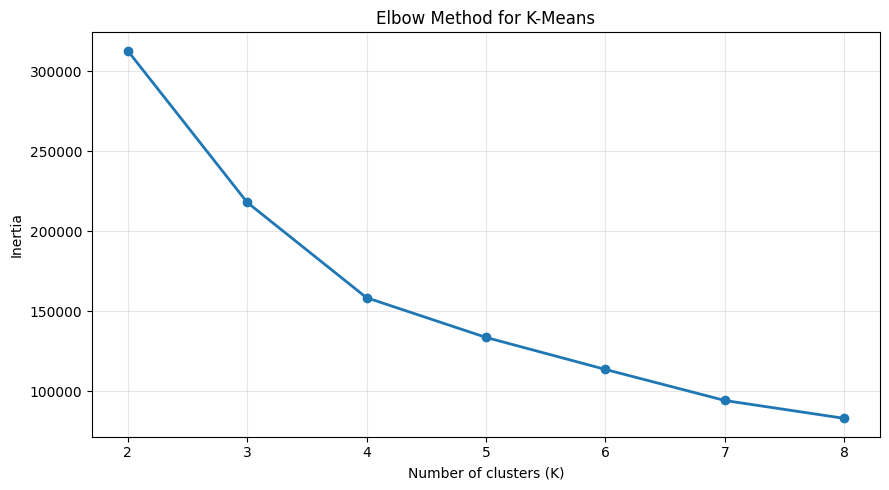

In [16]:

# H1.5.1 — VẼ BIỂU ĐỒ ELBOW

import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = "/content/ml1_kmeans_k_selection.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {file_path}"
    )

k_results = pd.read_csv(file_path)

print("Các cột dữ liệu:", k_results.columns.tolist())
print(k_results)

# Tự tìm cột K và Inertia
k_col = next(
    (c for c in k_results.columns
     if c.lower() in ["k", "n_clusters", "clusters"]),
    None
)
inertia_col = next(
    (c for c in k_results.columns
     if "inertia" in c.lower()),
    None
)

if k_col is None or inertia_col is None:
    raise ValueError(
        "Không xác định được cột K hoặc Inertia. "
        "Kiểm tra tên cột ở phần kết quả in ra."
    )

plt.figure(figsize=(9, 5))
plt.plot(
    k_results[k_col],
    k_results[inertia_col],
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_results[k_col])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# H1.5.2 — VẼ BIỂU ĐỒ SILHOUETTE

import pandas as pd
import matplotlib.pyplot as plt

file_path = "/content/ml1_kmeans_k_selection.csv"
k_results = pd.read_csv(file_path)

plt.figure(figsize=(9, 5))

plt.plot(
    k_results["K"],
    k_results["Silhouette"],
    marker="o",
    linewidth=2
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(k_results["K"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/ml1_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu biểu đồ tại:")
print("/content/ml1_silhouette_comparison.png")


In [17]:

# H1.6.1 — CHUẨN BỊ DỮ LIỆU SO SÁNH K=4 VÀ K=8

import os
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Đọc dữ liệu đặc trưng đã chuẩn hóa
file_path = "/content/ml1_customer_features_scaled.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {file_path}"
    )

ml1_data = pd.read_csv(file_path)

# 2. Tách mã khách hàng và 15 đặc trưng
if "visitorid" not in ml1_data.columns:
    raise ValueError("Dữ liệu không có cột visitorid.")

feature_cols = [
    col for col in ml1_data.columns
    if col != "visitorid"
]

X_all = ml1_data[feature_cols]

# 3. Kiểm tra chất lượng dữ liệu
print("===== H1.6.1 — DATA CHECK =====")
print("Số khách hàng:", len(ml1_data))
print("Số đặc trưng:", len(feature_cols))
print("Số visitorid trùng:", ml1_data["visitorid"].duplicated().sum())
print("Giá trị thiếu:", int(X_all.isna().sum().sum()))
print("Tất cả giá trị hữu hạn:", np.isfinite(X_all.to_numpy()).all())

# 4. Lấy cùng một mẫu 30.000 khách hàng
sample_size = min(30000, len(ml1_data))

sample_indices = ml1_data.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_all.loc[sample_indices].to_numpy()

print("\n===== SAMPLE CHECK =====")
print("Số khách hàng trong mẫu:", len(X_sample))
print("Số đặc trưng trong mẫu:", X_sample.shape[1])
print("K được so sánh:", [4, 8])


===== H1.6.1 — DATA CHECK =====
Số khách hàng: 1407579
Số đặc trưng: 15
Số visitorid trùng: 0
Giá trị thiếu: 0
Tất cả giá trị hữu hạn: True

===== SAMPLE CHECK =====
Số khách hàng trong mẫu: 30000
Số đặc trưng trong mẫu: 15
K được so sánh: [4, 8]


In [18]:

# H1.6.2 — SO SÁNH K-MEANS K=4 VÀ K=8 TRÊN CÙNG MẪU

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

comparison_models = {}
comparison_rows = []
cluster_size_rows = []

for k in [4, 8]:
    print(f"Đang huấn luyện K-Means với K={k}...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=300
    )

    labels = model.fit_predict(X_sample)

    # Tính Silhouette trên cùng mẫu
    sil_score = silhouette_score(
        X_sample,
        labels,
        sample_size=min(5000, len(X_sample)),
        random_state=42
    )

    comparison_models[k] = model

    comparison_rows.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": sil_score,
        "So_cum": len(np.unique(labels))
    })

    # Thống kê kích thước từng cụm
    counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in counts.items():
        cluster_size_rows.append({
            "K": k,
            "Cluster": int(cluster_id),
            "Customers": int(count),
            "Percentage": round(count / len(labels) * 100, 2)
        })

# Tạo bảng kết quả
comparison_df = pd.DataFrame(comparison_rows)
cluster_sizes_df = pd.DataFrame(cluster_size_rows)

print("\n===== MODEL COMPARISON =====")
print(comparison_df.round(4).to_string(index=False))

print("\n===== CLUSTER SIZES =====")
print(cluster_sizes_df.to_string(index=False))

# Lưu kết quả
comparison_df.to_csv(
    "/content/ml1_kmeans_k4_k8_comparison.csv",
    index=False
)

cluster_sizes_df.to_csv(
    "/content/ml1_kmeans_k4_k8_cluster_sizes.csv",
    index=False
)

print("\nĐã lưu kết quả so sánh K=4 và K=8.")


Đang huấn luyện K-Means với K=4...
Đang huấn luyện K-Means với K=8...

===== MODEL COMPARISON =====
 K     Inertia  Silhouette  So_cum
 4 158590.8879      0.7727       4
 8  83179.4236      0.7886       8

===== CLUSTER SIZES =====
 K  Cluster  Customers  Percentage
 4        0      25763       85.88
 4        1       3485       11.62
 4        2        222        0.74
 4        3        530        1.77
 8        0      22779       75.93
 8        1       2251        7.50
 8        2        218        0.73
 8        3        216        0.72
 8        4       3669       12.23
 8        5        520        1.73
 8        6          3        0.01
 8        7        344        1.15

Đã lưu kết quả so sánh K=4 và K=8.


In [19]:

# H1.6.3 — SO SÁNH ĐẶC TRƯNG HÀNH VI CỦA K=4 VÀ K=8

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# 1. Kiểm tra đặc trưng hành vi gốc
if "customer_features" not in globals():
    raise NameError(
        "Không tìm thấy customer_features trong bộ nhớ. "
        "Hãy báo mình để khôi phục đặc trưng hành vi gốc."
    )

# 2. Tạo bảng khách hàng thuộc mẫu so sánh
sample_ids = ml1_data.loc[sample_indices, "visitorid"].to_numpy()

behavior_cols = [
    "total_events",
    "total_sessions",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

missing_cols = [
    c for c in behavior_cols
    if c not in customer_features.columns
]

if missing_cols:
    raise ValueError(f"Thiếu cột hành vi: {missing_cols}")

behavior_sample = (
    customer_features
    .set_index("visitorid")
    .loc[sample_ids, behavior_cols]
    .reset_index()
)

# 3. Huấn luyện lại để lấy nhãn cụm tương ứng với đúng thứ tự mẫu
labels_by_k = {}

for k in [4, 8]:
    model = comparison_models[k]
    labels_by_k[k] = model.labels_

# 4. Tổng hợp trung bình và trung vị của từng cụm
profile_tables = []

for k in [4, 8]:
    temp = behavior_sample.copy()
    temp["cluster"] = labels_by_k[k]

    summary = temp.groupby("cluster").agg(
        customers=("visitorid", "count"),
        mean_events=("total_events", "mean"),
        median_events=("total_events", "median"),
        mean_views=("total_views", "mean"),
        mean_addtocart=("total_addtocart", "mean"),
        mean_transaction_events=(
            "total_transaction_events", "mean"
        ),
        mean_unique_items=("unique_items", "mean"),
        pct_customers_with_cart=(
            "total_addtocart",
            lambda s: (s > 0).mean() * 100
        ),
        pct_customers_with_transaction=(
            "total_transaction_events",
            lambda s: (s > 0).mean() * 100
        )
    ).reset_index()

    summary.insert(0, "K", k)
    profile_tables.append(summary)

profiles_df = pd.concat(profile_tables, ignore_index=True)

print("===== BEHAVIOR PROFILES: K=4 VS K=8 =====")
print(profiles_df.round(3).to_string(index=False))

profiles_df.to_csv(
    "/content/ml1_kmeans_k4_k8_behavior_profiles.csv",
    index=False
)

print("\nĐã lưu bảng hồ sơ hành vi.")


===== BEHAVIOR PROFILES: K=4 VS K=8 =====
 K  cluster  customers  mean_events  median_events  mean_views  mean_addtocart  mean_transaction_events  mean_unique_items  pct_customers_with_cart  pct_customers_with_transaction
 4        0      25763        1.230            1.0       1.230           0.000                    0.000              1.114                    0.000                           0.000
 4        1       3485        5.645            4.0       5.629           0.016                    0.000              3.829                    1.492                           0.000
 4        2        222       29.586            7.0      24.734           2.604                    2.248             16.081                   89.640                         100.000
 4        3        530        5.443            3.0       3.989           1.455                    0.000              2.732                  100.000                           0.000
 8        0      22779        1.076            1.0       1

In [20]:
# H1.6.4 — KIỂM TRA CỤM CỰC TRỊ CỦA K=8

import pandas as pd
import numpy as np

# 1. Kiểm tra các biến cần thiết
required_vars = [
    "customer_features",
    "ml1_data",
    "sample_indices",
    "comparison_models"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise NameError(
        f"Thiếu biến trong bộ nhớ Colab: {missing_vars}"
    )

# 2. Lấy nhãn cụm K=8
labels_k8 = comparison_models[8].labels_

if len(labels_k8) != len(sample_indices):
    raise ValueError(
        "Số nhãn cụm không khớp với số phần tử mẫu."
    )

sample_ids = (
    ml1_data.loc[sample_indices, "visitorid"]
    .to_numpy()
)

# 3. Ghép nhãn cụm với đặc trưng hành vi gốc
behavior_cols = [
    "total_events",
    "total_sessions",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

missing_cols = [
    c for c in behavior_cols
    if c not in customer_features.columns
]

if missing_cols:
    raise ValueError(
        f"Thiếu cột hành vi: {missing_cols}"
    )

behavior_sample = (
    customer_features
    .set_index("visitorid")
    .loc[sample_ids, behavior_cols]
    .reset_index()
)

behavior_sample["cluster_k8"] = labels_k8

# 4. Xem các cụm có ít khách hàng nhất
cluster_sizes = (
    behavior_sample["cluster_k8"]
    .value_counts()
    .sort_values()
)

print("===== QUY MÔ CÁC CỤM K=8 =====")
print(cluster_sizes.to_string())

# 5. Xem chi tiết khách hàng thuộc cụm 3 người
smallest_cluster = cluster_sizes.index[0]

small_cluster_df = behavior_sample[
    behavior_sample["cluster_k8"] == smallest_cluster
].copy()

print(
    f"\n===== CHI TIẾT CỤM {smallest_cluster} ====="
)
print(
    small_cluster_df.to_string(index=False)
)

# 6. Thống kê phân vị để đánh giá mức độ cực trị
print("\n===== PHÂN VỊ CỦA ĐẶC TRƯNG HÀNH VI =====")

print(
    behavior_sample[behavior_cols]
    .quantile([0.50, 0.90, 0.95, 0.99, 1.00])
    .round(3)
    .to_string()
)

===== QUY MÔ CÁC CỤM K=8 =====
cluster_k8
6        3
3      216
2      218
7      344
5      520
1     2251
4     3669
0    22779

===== CHI TIẾT CỤM 6 =====
 visitorid  total_events  total_sessions  total_views  total_addtocart  total_transaction_events  unique_items  unique_transactions  cluster_k8
    895999          2474             414         2368               56                        50          1641                   44           6
    198270           956              42          741              111                       104           537                   88           6
   1293358           772              17          622               88                        62           455                   56           6

===== PHÂN VỊ CỦA ĐẶC TRƯNG HÀNH VI =====
      total_events  total_sessions  total_views  total_addtocart  total_transaction_events  unique_items  unique_transactions
0.50           1.0             1.0          1.0              0.0                       0.0       

In [21]:
# H1.7.1 — KIỂM TRA DỮ LIỆU PCA

print("===== KIỂM TRA BIẾN =====")

for var in [
    "X_sample",
    "X_scaled",
    "X_scaled_sample",
    "X",
    "ml1_data",
    "sample_indices",
    "comparison_models"
]:
    if var in globals():
        obj = globals()[var]

        print(
            f"{var}: "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )
    else:
        print(f"{var}: chưa tồn tại")

print("\n===== KIỂM TRA MÔ HÌNH K=4 =====")

if "comparison_models" in globals():
    model_k4 = comparison_models[4]

    print("Số cụm:", model_k4.n_clusters)
    print("Số nhãn:", len(model_k4.labels_))
    print("Số đặc trưng mô hình:", model_k4.n_features_in_)

===== KIỂM TRA BIẾN =====
X_sample: shape=(30000, 15)
X_scaled: shape=(1407579, 15)
X_scaled_sample: chưa tồn tại
X: shape=(1407579, 15)
ml1_data: shape=(1407579, 16)
sample_indices: shape=(30000,)
comparison_models: shape=N/A

===== KIỂM TRA MÔ HÌNH K=4 =====
Số cụm: 4
Số nhãn: 30000
Số đặc trưng mô hình: 15


===== KẾT QUẢ PCA =====
Shape dữ liệu PCA: (30000, 2)
PC1 giải thích: 44.18% phương sai
PC2 giải thích: 26.24% phương sai
Tổng phương sai giải thích: 70.42%

===== SỐ KHÁCH HÀNG MỖI CỤM =====
cluster
0    25763
1     3485
2      222
3      530


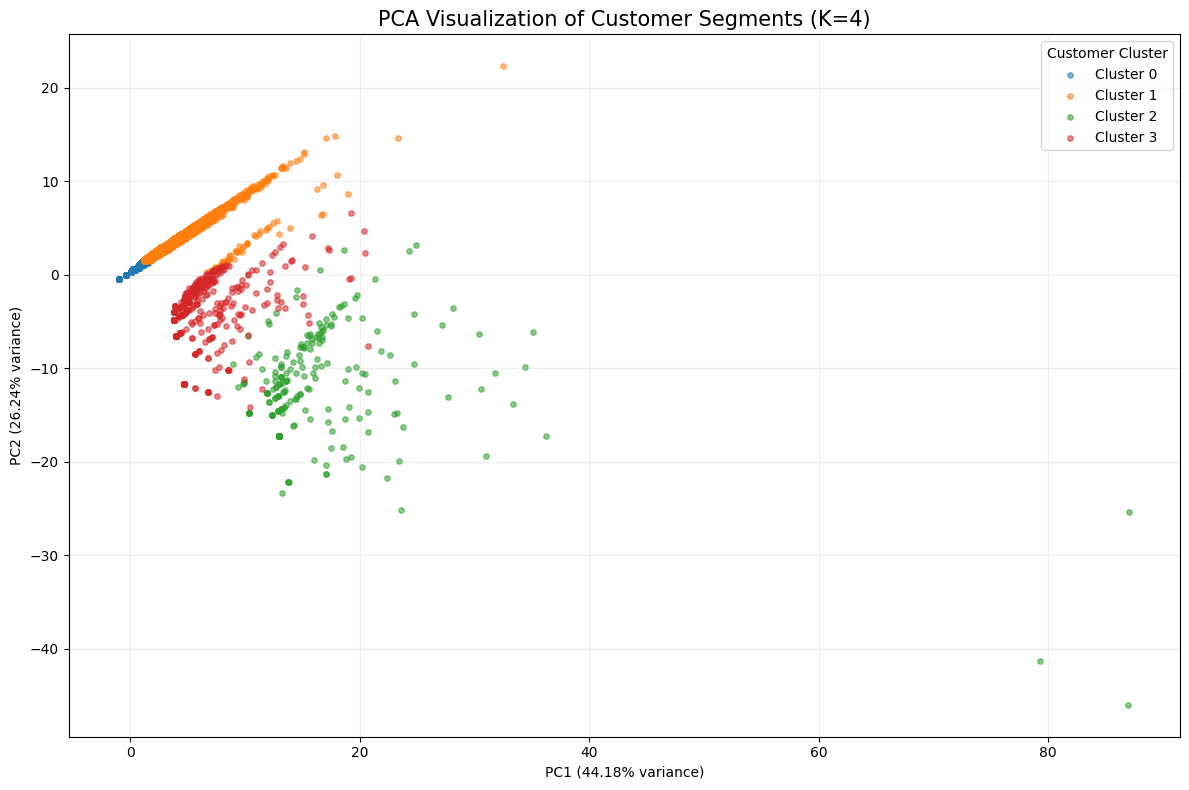


Đã lưu biểu đồ PCA và bảng tọa độ.


In [22]:

# H1.7.2 — TRỰC QUAN HÓA PCA CHO K=4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

# 1. Kiểm tra dữ liệu
if X_sample.shape[0] != len(comparison_models[4].labels_):
    raise ValueError(
        "Số dòng X_sample không khớp số nhãn cụm K=4."
    )

if X_sample.shape[1] != 15:
    raise ValueError(
        f"Đang có {X_sample.shape[1]} đặc trưng, "
        "không phải 15 đặc trưng như dự kiến."
    )

# 2. Lấy nhãn cụm K=4
labels_k4 = comparison_models[4].labels_

# 3. PCA hai thành phần
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_sample)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": labels_k4
})

# 4. Tính tỷ lệ phương sai giải thích
explained_variance = pca.explained_variance_ratio_
total_variance = explained_variance.sum()

print("===== KẾT QUẢ PCA =====")
print(f"Shape dữ liệu PCA: {X_pca.shape}")
print(
    f"PC1 giải thích: "
    f"{explained_variance[0] * 100:.2f}% phương sai"
)
print(
    f"PC2 giải thích: "
    f"{explained_variance[1] * 100:.2f}% phương sai"
)
print(
    f"Tổng phương sai giải thích: "
    f"{total_variance * 100:.2f}%"
)

print("\n===== SỐ KHÁCH HÀNG MỖI CỤM =====")
print(
    pca_df["cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

# 5. Vẽ biểu đồ PCA
plt.figure(figsize=(12, 8))

for cluster_id in sorted(pca_df["cluster"].unique()):
    subset = pca_df[pca_df["cluster"] == cluster_id]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Cluster {cluster_id}",
        alpha=0.55,
        s=15
    )

plt.title(
    "PCA Visualization of Customer Segments (K=4)",
    fontsize=15
)
plt.xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f}% variance)"
)
plt.legend(title="Customer Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()

# 6. Lưu biểu đồ và tọa độ PCA
plt.savefig(
    "/content/ml1_h1_7_pca_k4.png",
    dpi=300,
    bbox_inches="tight"
)

pca_df.to_csv(
    "/content/ml1_h1_7_pca_k4_coordinates.csv",
    index=False
)

plt.show()

print("\nĐã lưu biểu đồ PCA và bảng tọa độ.")


In [23]:

# H1.8.1 — CHUẨN BỊ DỮ LIỆU HEATMAP K=4

import os
import numpy as np
import pandas as pd

# 1. Kiểm tra dữ liệu đặc trưng gốc
if "customer_features" not in globals():
    raise NameError(
        "Không tìm thấy customer_features trong bộ nhớ Colab. "
        "Báo mình để khôi phục dữ liệu trước khi tiếp tục."
    )

# 2. Các đặc trưng hành vi cần phân tích
heatmap_features = [
    "total_views",
    "total_sessions",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

missing_cols = [
    col for col in heatmap_features
    if col not in customer_features.columns
]

if missing_cols:
    raise ValueError(
        f"Thiếu các cột đặc trưng: {missing_cols}"
    )

# 3. Kiểm tra nhãn K=4 từ mẫu 30.000 khách hàng
if "comparison_models" not in globals():
    raise NameError("Không tìm thấy comparison_models.")

if "sample_indices" not in globals():
    raise NameError("Không tìm thấy sample_indices.")

# Tái tạo đúng thứ tự khách hàng trong mẫu
sample_ids = ml1_data.loc[
    sample_indices, "visitorid"
].to_numpy()

labels_k4 = comparison_models[4].labels_

if len(sample_ids) != len(labels_k4):
    raise ValueError(
        "Số khách hàng và số nhãn cụm không khớp."
    )

# 4. Ghép nhãn cụm với đặc trưng hành vi gốc
behavior_indexed = customer_features.set_index("visitorid")

heatmap_data = behavior_indexed.loc[
    sample_ids, heatmap_features
].copy()

heatmap_data["cluster"] = labels_k4

# 5. Tính trung bình hành vi của từng cụm
cluster_means = heatmap_data.groupby("cluster")[
    heatmap_features
].mean()

print("===== H1.8.1 — HEATMAP DATA CHECK =====")
print("Số khách hàng:", len(heatmap_data))
print("Số cụm:", heatmap_data["cluster"].nunique())
print("Số đặc trưng:", len(heatmap_features))
print("\nGiá trị trung bình theo cụm:")
print(cluster_means.round(3))

print("\nGiá trị thiếu:", int(heatmap_data.isna().sum().sum()))
print("Tất cả giá trị hữu hạn:",
      np.isfinite(heatmap_data[heatmap_features].to_numpy()).all())


===== H1.8.1 — HEATMAP DATA CHECK =====
Số khách hàng: 30000
Số cụm: 4
Số đặc trưng: 6

Giá trị trung bình theo cụm:
         total_views  total_sessions  total_addtocart  \
cluster                                                 
0              1.230           1.033            0.000   
1              5.629           2.601            0.016   
2             24.734           5.018            2.604   
3              3.989           1.538            1.455   

         total_transaction_events  unique_items  unique_transactions  
cluster                                                               
0                           0.000         1.114                 0.00  
1                           0.000         3.829                 0.00  
2                           2.248        16.081                 1.95  
3                           0.000         2.732                 0.00  

Giá trị thiếu: 0
Tất cả giá trị hữu hạn: True


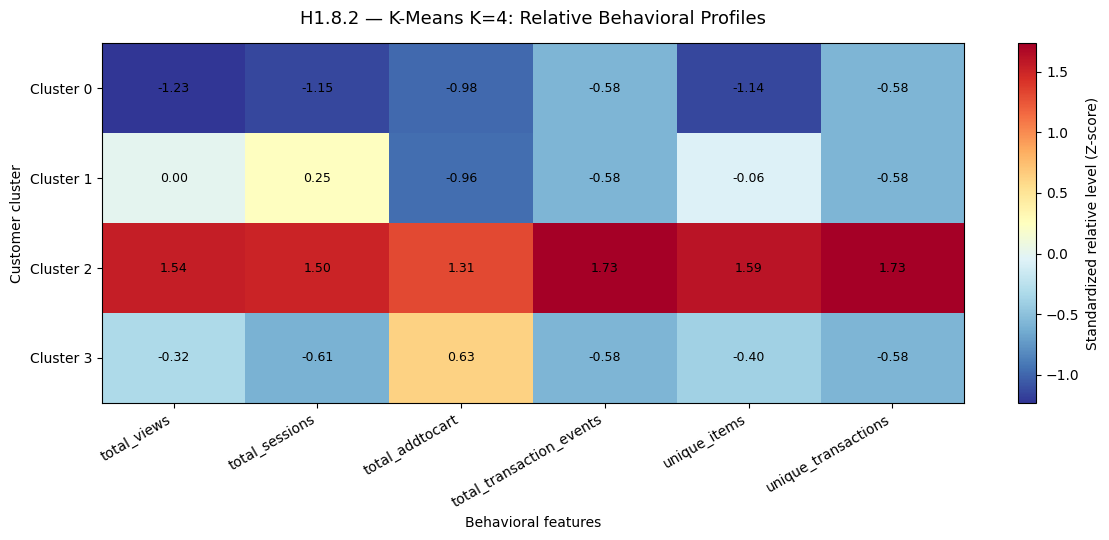

Đã lưu heatmap tại: /content/ml1_kmeans_k4_behavior_heatmap.png

Bảng dữ liệu dùng để vẽ heatmap:
         total_views  total_sessions  total_addtocart  \
cluster                                                 
0             -1.231          -1.147           -0.984   
1              0.005           0.249           -0.955   
2              1.544           1.502            1.314   
3             -0.318          -0.605            0.626   

         total_transaction_events  unique_items  unique_transactions  
cluster                                                               
0                          -0.577        -1.139               -0.577  
1                          -0.577        -0.059               -0.577  
2                           1.732         1.594                1.732  
3                          -0.577        -0.396               -0.577  


In [24]:

# H1.8.2 — VẼ HEATMAP ĐẶC TRƯNG HÀNH VI K=4

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Tính log1p cho các giá trị đếm
# Giảm ảnh hưởng của những giá trị cực lớn
count_features = [
    "total_views",
    "total_sessions",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

cluster_means_log = (
    heatmap_data.groupby("cluster")[count_features]
    .mean()
    .apply(np.log1p)
)

# 2. Chuẩn hóa theo từng đặc trưng giữa các cụm
# Mỗi cột thể hiện cụm nào cao/thấp hơn mức trung bình
col_mean = cluster_means_log.mean(axis=0)
col_std = cluster_means_log.std(axis=0, ddof=0)

heatmap_z = (
    cluster_means_log - col_mean
) / col_std.replace(0, 1)

# 3. Vẽ heatmap bằng Matplotlib
fig, ax = plt.subplots(figsize=(12, 5.5))

im = ax.imshow(
    heatmap_z.to_numpy(),
    aspect="auto",
    cmap="RdYlBu_r"
)

ax.set_xticks(range(len(count_features)))
ax.set_xticklabels(
    count_features,
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(cluster_means_log.index)))
ax.set_yticklabels([
    f"Cluster {c}" for c in cluster_means_log.index
])

ax.set_title(
    "H1.8.2 — K-Means K=4: Relative Behavioral Profiles",
    fontsize=13,
    pad=14
)
ax.set_xlabel("Behavioral features")
ax.set_ylabel("Customer cluster")

# Hiển thị giá trị chuẩn hóa trong từng ô
for i in range(heatmap_z.shape[0]):
    for j in range(heatmap_z.shape[1]):
        value = heatmap_z.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Standardized relative level (Z-score)")

plt.tight_layout()

# 4. Lưu biểu đồ
output_path = "/content/ml1_kmeans_k4_behavior_heatmap.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Đã lưu heatmap tại:", output_path)
print("\nBảng dữ liệu dùng để vẽ heatmap:")
print(heatmap_z.round(3))


In [25]:

# H1.8.3 — LƯU BẢNG HỒ SƠ HÀNH VI VÀ Z-SCORE K=4

import os
import pandas as pd

# 1. Hồ sơ hành vi trung bình theo cụm (thang đo log1p)
profile_log = cluster_means_log.copy()
profile_log.index.name = "cluster"

# 2. Bảng Z-score dùng trong heatmap
profile_zscore = heatmap_z.copy()
profile_zscore.index.name = "cluster"

# 3. Lưu kết quả
profile_log_path = "/content/ml1_kmeans_k4_behavior_profile_log.csv"
profile_zscore_path = "/content/ml1_kmeans_k4_behavior_profile_zscore.csv"

profile_log.to_csv(profile_log_path, encoding="utf-8-sig")
profile_zscore.to_csv(profile_zscore_path, encoding="utf-8-sig")

print("===== H1.8.3 — SAVED RESULTS =====")

print("\n1. Hồ sơ hành vi sau biến đổi log1p:")
print(profile_log.round(3))
print("\nĐường dẫn:", profile_log_path)

print("\n2. Hồ sơ hành vi chuẩn hóa Z-score:")
print(profile_zscore.round(3))
print("\nĐường dẫn:", profile_zscore_path)

print("\nKiểm tra:")
print("Số cụm:", len(profile_log))
print("Số đặc trưng:", profile_log.shape[1])
print("Z-score có giá trị thiếu:", profile_zscore.isna().sum().sum())


===== H1.8.3 — SAVED RESULTS =====

1. Hồ sơ hành vi sau biến đổi log1p:
         total_views  total_sessions  total_addtocart  \
cluster                                                 
0              0.802           0.709            0.000   
1              1.891           1.281            0.016   
2              3.248           1.795            1.282   
3              1.607           0.931            0.898   

         total_transaction_events  unique_items  unique_transactions  
cluster                                                               
0                           0.000         0.749                0.000  
1                           0.000         1.575                0.000  
2                           1.178         2.838                1.082  
3                           0.000         1.317                0.000  

Đường dẫn: /content/ml1_kmeans_k4_behavior_profile_log.csv

2. Hồ sơ hành vi chuẩn hóa Z-score:
         total_views  total_sessions  total_addtocart  \
clus

In [26]:

# H1.8.4 — KIỂM TRA QUY MÔ CỤM K=4 TRÊN TOÀN BỘ DỮ LIỆU
# Phiên bản sửa lỗi nhận diện cột kmeans_cluster

import os
import pandas as pd

labels_path = "/content/ml1_kmeans_cluster_labels.csv"

if not os.path.exists(labels_path):
    raise FileNotFoundError(f"Không tìm thấy file: {labels_path}")

labels_full = pd.read_csv(labels_path)

# Xác định đúng tên cột
if "visitorid" not in labels_full.columns:
    raise ValueError("Không tìm thấy cột visitorid.")

if "kmeans_cluster" in labels_full.columns:
    cluster_col = "kmeans_cluster"
elif "cluster" in labels_full.columns:
    cluster_col = "cluster"
else:
    raise ValueError(
        f"Không tìm thấy cột nhãn cụm. Các cột hiện có: "
        f"{labels_full.columns.tolist()}"
    )

# Kiểm tra dữ liệu
print("===== KIỂM TRA DỮ LIỆU =====")
print("Shape:", labels_full.shape)
print("Số mã khách hàng trùng:",
      labels_full["visitorid"].duplicated().sum())
print("Số nhãn cụm:", labels_full[cluster_col].nunique())
print("Giá trị thiếu:")
print(labels_full[["visitorid", cluster_col]].isna().sum())

# Tính quy mô từng cụm
cluster_sizes_full = (
    labels_full[cluster_col]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

cluster_sizes_full["percentage"] = (
    cluster_sizes_full["customer_count"]
    / len(labels_full) * 100
)

cluster_sizes_full.index.name = "cluster"

print("\n===== H1.8.4 — K=4 FULL-DATA CLUSTER SIZES =====")
print(cluster_sizes_full.round(3))

print("\nTổng số khách hàng:", len(labels_full))
print("Tổng tỷ lệ (%):",
      round(cluster_sizes_full["percentage"].sum(), 3))

output_path = "/content/ml1_kmeans_k4_full_cluster_sizes.csv"
cluster_sizes_full.to_csv(output_path, encoding="utf-8-sig")

print("\nĐã lưu bảng tại:", output_path)


===== KIỂM TRA DỮ LIỆU =====
Shape: (1407579, 2)
Số mã khách hàng trùng: 0
Số nhãn cụm: 4
Giá trị thiếu:
visitorid         0
kmeans_cluster    0
dtype: int64

===== H1.8.4 — K=4 FULL-DATA CLUSTER SIZES =====
         customer_count  percentage
cluster                            
0                240270      17.070
1                998984      70.972
2                135234       9.608
3                 33091       2.351

Tổng số khách hàng: 1407579
Tổng tỷ lệ (%): 100.0

Đã lưu bảng tại: /content/ml1_kmeans_k4_full_cluster_sizes.csv


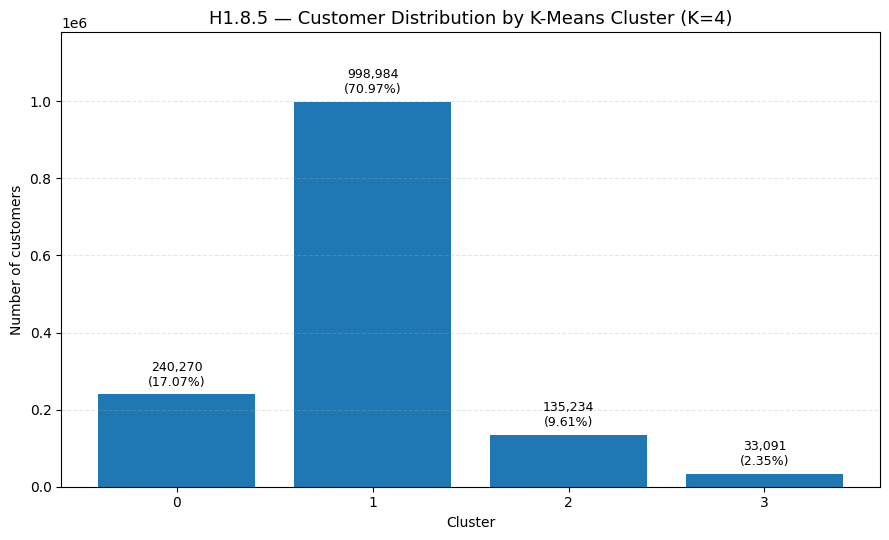

Đã lưu biểu đồ tại: /content/ml1_kmeans_k4_full_cluster_distribution.png


In [27]:

# H1.8.5 — BIỂU ĐỒ QUY MÔ CỤM K=4 TRÊN TOÀN BỘ DỮ LIỆU

import matplotlib.pyplot as plt
import pandas as pd

# Đọc bảng kết quả đã lưu
sizes_path = "/content/ml1_kmeans_k4_full_cluster_sizes.csv"
sizes = pd.read_csv(sizes_path, index_col="cluster")

# Vẽ biểu đồ cột
fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    sizes.index.astype(str),
    sizes["customer_count"]
)

ax.set_title(
    "H1.8.5 — Customer Distribution by K-Means Cluster (K=4)",
    fontsize=13
)
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of customers")
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Gắn nhãn số lượng và tỷ lệ lên từng cột
for bar, (_, row) in zip(bars, sizes.iterrows()):
    height = bar.get_height()
    ax.annotate(
        f'{int(row["customer_count"]):,}\n({row["percentage"]:.2f}%)',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(0, sizes["customer_count"].max() * 1.18)
plt.tight_layout()

output_path = "/content/ml1_kmeans_k4_full_cluster_distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Đã lưu biểu đồ tại:", output_path)


In [28]:
# H1.8.6 — FULL-DATA K=4 BEHAVIOR PROFILE


import os
import pandas as pd

print("===== H1.8.6 — FULL-DATA BEHAVIOR PROFILE =====")

# 1. Đọc nhãn phân cụm trên toàn bộ khách hàng
labels_full = pd.read_csv(
    "/content/ml1_kmeans_cluster_labels.csv"
)

assert {"visitorid", "kmeans_cluster"}.issubset(
    labels_full.columns
), "File nhãn thiếu cột cần thiết."

# 2. Lấy đặc trưng hành vi gốc (chưa chuẩn hóa)
required_cols = [
    "visitorid",
    "total_events",
    "total_sessions",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

if (
    "customer_features" in globals()
    and isinstance(customer_features, pd.DataFrame)
    and set(required_cols).issubset(customer_features.columns)
):
    behavior = customer_features[required_cols].copy()
    print("Nguồn đặc trưng: customer_features trong RAM")

else:
    print("Không có customer_features trong RAM.")
    print("Đang khôi phục đặc trưng từ clean_events_final.csv ...")

    events_path = "/content/clean_events_final.csv"

    if not os.path.exists(events_path):
        raise FileNotFoundError(
            f"Không tìm thấy {events_path}"
        )

    events_tmp = pd.read_csv(
        events_path,
        usecols=[
            "visitorid",
            "session_id",
            "event",
            "itemid",
            "transactionid"
        ]
    )

    events_tmp["is_view"] = (
        events_tmp["event"] == "view"
    ).astype("int8")

    events_tmp["is_cart"] = (
        events_tmp["event"] == "addtocart"
    ).astype("int8")

    events_tmp["is_transaction"] = (
        events_tmp["event"] == "transaction"
    ).astype("int8")

    behavior = (
        events_tmp
        .groupby("visitorid", sort=False)
        .agg(
            total_events=("event", "size"),
            total_sessions=("session_id", "nunique"),
            total_views=("is_view", "sum"),
            total_addtocart=("is_cart", "sum"),
            total_transaction_events=("is_transaction", "sum"),
            unique_items=("itemid", "nunique"),
            unique_transactions=("transactionid", "nunique")
        )
        .reset_index()
    )

    del events_tmp
    print("Đã khôi phục đặc trưng thành công.")

# 3. Ghép đặc trưng với nhãn phân cụm
ml1_full_behavior = labels_full.merge(
    behavior,
    on="visitorid",
    how="left",
    validate="one_to_one"
)

print("\n===== KIỂM TRA DỮ LIỆU SAU GHÉP =====")
print("Shape:", ml1_full_behavior.shape)
print(
    "Số khách hàng thiếu đặc trưng:",
    ml1_full_behavior["total_events"].isna().sum()
)

assert len(ml1_full_behavior) == len(labels_full)
assert not ml1_full_behavior[required_cols].isna().any().any()

# 4. Tạo hồ sơ hành vi cho 4 cụm
profile_full = (
    ml1_full_behavior
    .groupby("kmeans_cluster")
    .agg(
        customer_count=("visitorid", "size"),
        mean_events=("total_events", "mean"),
        median_events=("total_events", "median"),
        mean_sessions=("total_sessions", "mean"),
        mean_views=("total_views", "mean"),
        mean_cart=("total_addtocart", "mean"),
        mean_transaction_events=(
            "total_transaction_events", "mean"
        ),
        mean_unique_items=("unique_items", "mean"),
        mean_unique_transactions=(
            "unique_transactions", "mean"
        ),
        pct_customers_with_cart=(
            "total_addtocart",
            lambda x: (x > 0).mean() * 100
        ),
        pct_customers_with_transaction=(
            "total_transaction_events",
            lambda x: (x > 0).mean() * 100
        )
    )
)

profile_full.index.name = "cluster"

print("\n===== HỒ SƠ HÀNH VI TỪNG CỤM =====")
print(profile_full.round(3).to_string())

# 5. Lưu kết quả
output_path = (
    "/content/ml1_kmeans_k4_full_behavior_profile.csv"
)

profile_full.to_csv(output_path)

print("\nĐã lưu tại:", output_path)


===== H1.8.6 — FULL-DATA BEHAVIOR PROFILE =====
Nguồn đặc trưng: customer_features trong RAM

===== KIỂM TRA DỮ LIỆU SAU GHÉP =====
Shape: (1407579, 9)
Số khách hàng thiếu đặc trưng: 0

===== HỒ SƠ HÀNH VI TỪNG CỤM =====
         customer_count  mean_events  median_events  mean_sessions  mean_views  mean_cart  mean_transaction_events  mean_unique_items  mean_unique_transactions  pct_customers_with_cart  pct_customers_with_transaction
cluster                                                                                                                                                                                                                 
0                240270        2.496            2.0          1.213       2.494      0.002                    0.000              1.783                     0.000                    0.162                           0.000
1                998984        1.000            1.0          1.000       1.000      0.000                    0.000              

In [29]:
# H1.8.7 — PURCHASE DISTRIBUTION BY K=4 CLUSTERS


import pandas as pd
import numpy as np
import os

print("===== H1.8.7 — PURCHASE DISTRIBUTION =====")

# 1. Kiểm tra dữ liệu từ H1.8.6
if "ml1_full_behavior" not in globals():
    raise NameError(
        "Chưa có ml1_full_behavior. "
        "Vui lòng chạy lại H1.8.6."
    )

required_cols = [
    "visitorid",
    "kmeans_cluster",
    "total_addtocart",
    "total_transaction_events"
]

assert set(required_cols).issubset(
    ml1_full_behavior.columns
), "Thiếu cột cần thiết."

df = ml1_full_behavior[required_cols].copy()

# 2. Xác định khách hàng từng thêm giỏ và từng mua
df["has_cart"] = (
    df["total_addtocart"] > 0
).astype(int)

df["has_purchase"] = (
    df["total_transaction_events"] > 0
).astype(int)

# 3. Tổng hợp theo cụm
purchase_summary = (
    df.groupby("kmeans_cluster")
    .agg(
        customer_count=("visitorid", "size"),
        cart_customers=("has_cart", "sum"),
        purchasing_customers=("has_purchase", "sum"),
        total_cart_events=("total_addtocart", "sum"),
        total_transaction_events=(
            "total_transaction_events", "sum"
        )
    )
)

purchase_summary.index.name = "cluster"

# 4. Tính các tỷ lệ
total_buyers = purchase_summary[
    "purchasing_customers"
].sum()

total_cart_users = purchase_summary[
    "cart_customers"
].sum()

purchase_summary["cluster_share_pct"] = (
    purchase_summary["customer_count"]
    / purchase_summary["customer_count"].sum() * 100
)

purchase_summary["buyer_rate_within_cluster_pct"] = (
    purchase_summary["purchasing_customers"]
    / purchase_summary["customer_count"] * 100
)

purchase_summary["share_of_all_buyers_pct"] = (
    purchase_summary["purchasing_customers"]
    / total_buyers * 100
    if total_buyers > 0 else 0
)

purchase_summary["share_of_all_cart_users_pct"] = (
    purchase_summary["cart_customers"]
    / total_cart_users * 100
    if total_cart_users > 0 else 0
)

# 5. Hiển thị kết quả
print("\n===== PHÂN BỐ KHÁCH HÀNG MUA HÀNG =====")
print(purchase_summary.round(3).to_string())

print("\n===== KIỂM TRA TỔNG =====")
print("Tổng khách hàng:", len(df))
print("Khách hàng từng thêm giỏ:", total_cart_users)
print("Khách hàng từng mua:", total_buyers)
print(
    "Tổng tỷ lệ phân bố người mua:",
    round(
        purchase_summary[
            "share_of_all_buyers_pct"
        ].sum(), 3
    ), "%"
)

# 6. Lưu kết quả
output_path = (
    "/content/ml1_kmeans_k4_purchase_distribution.csv"
)

purchase_summary.to_csv(output_path)

print("\nĐã lưu tại:", output_path)


===== H1.8.7 — PURCHASE DISTRIBUTION =====

===== PHÂN BỐ KHÁCH HÀNG MUA HÀNG =====
         customer_count  cart_customers  purchasing_customers  total_cart_events  total_transaction_events  cluster_share_pct  buyer_rate_within_cluster_pct  share_of_all_buyers_pct  share_of_all_cart_users_pct
cluster                                                                                                                                                                                                           
0                240270             389                     0                389                         0             17.070                          0.000                    0.000                        1.031
1                998984               0                     0                  0                         0             70.972                          0.000                    0.000                        0.000
2                135234            5280                   130           

===== H1.8.8 — CUSTOMER VS BUYER DISTRIBUTION =====


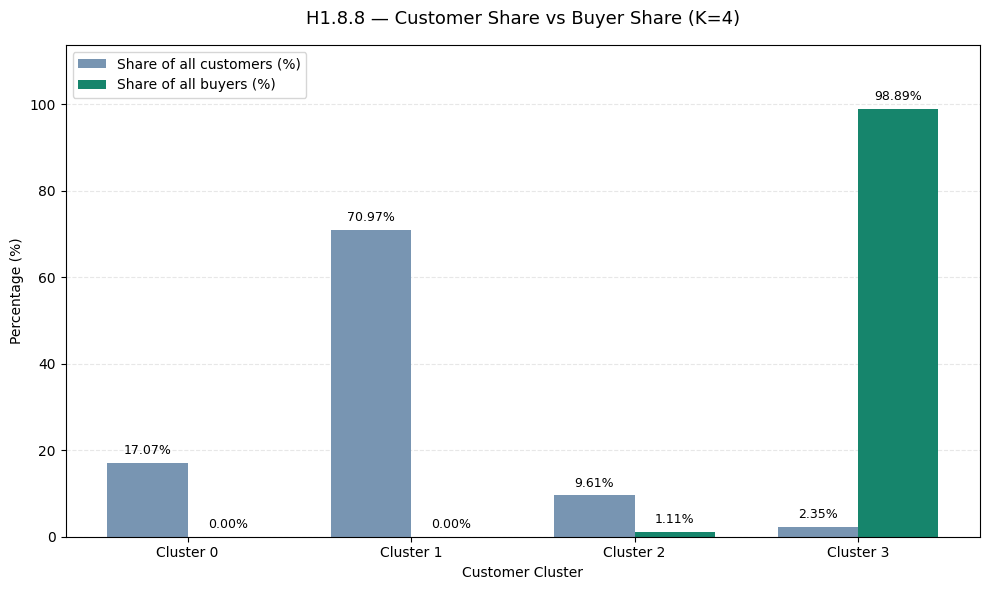


===== KIỂM TRA =====
Tổng tỷ lệ khách hàng: 100.0
Tổng tỷ lệ người mua: 100.0
Tổng khách hàng: 1407579
Tổng khách hàng từng mua: 11718

Đã lưu biểu đồ tại: /content/ml1_kmeans_k4_customer_vs_buyer_share.png


In [30]:

# H1.8.8 — CUSTOMER SHARE VS BUYER SHARE (K=4)


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("===== H1.8.8 — CUSTOMER VS BUYER DISTRIBUTION =====")

# 1. Đọc kết quả H1.8.7
file_path = "/content/ml1_kmeans_k4_purchase_distribution.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Không tìm thấy file H1.8.7. Hãy chạy lại bước trước."
    )

df = pd.read_csv(file_path)

required = [
    "cluster",
    "customer_count",
    "purchasing_customers",
    "cluster_share_pct",
    "share_of_all_buyers_pct"
]

missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"Thiếu cột: {missing}")

df = df.sort_values("cluster").reset_index(drop=True)

# 2. Chuẩn bị dữ liệu
x = np.arange(len(df))
width = 0.36

customer_share = df["cluster_share_pct"].to_numpy()
buyer_share = df["share_of_all_buyers_pct"].to_numpy()

# 3. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    customer_share,
    width,
    label="Share of all customers (%)",
    color="#7895B2"
)

bars2 = ax.bar(
    x + width / 2,
    buyer_share,
    width,
    label="Share of all buyers (%)",
    color="#16856C"
)

# 4. Hiển thị tỷ lệ
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            f"{value:.2f}%",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

# 5. Định dạng
ax.set_title(
    "H1.8.8 — Customer Share vs Buyer Share (K=4)",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Customer Cluster")
ax.set_ylabel("Percentage (%)")

ax.set_xticks(x)
ax.set_xticklabels([
    f"Cluster {c}" for c in df["cluster"]
])

ax.set_ylim(
    0,
    max(customer_share.max(), buyer_share.max()) * 1.15
)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# 6. Lưu biểu đồ
output_path = (
    "/content/ml1_kmeans_k4_customer_vs_buyer_share.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n===== KIỂM TRA =====")
print("Tổng tỷ lệ khách hàng:", round(customer_share.sum(), 3))
print("Tổng tỷ lệ người mua:", round(buyer_share.sum(), 3))
print("Tổng khách hàng:", int(df["customer_count"].sum()))
print(
    "Tổng khách hàng từng mua:",
    int(df["purchasing_customers"].sum())
)

print("\nĐã lưu biểu đồ tại:", output_path)


In [31]:

# H1.9.1 — KIỂM TRA KẾT QUẢ SO SÁNH K=4 VÀ K=8


import os
import pandas as pd

print("===== H1.9.1 — K-MEANS MODEL COMPARISON =====")

files = {
    "Model comparison": (
        "/content/ml1_kmeans_k4_k8_comparison.csv"
    ),
    "Cluster sizes": (
        "/content/ml1_kmeans_k4_k8_cluster_sizes.csv"
    ),
    "Behavior profiles": (
        "/content/ml1_kmeans_k4_k8_behavior_profiles.csv"
    )
}

comparison_results = {}

for name, path in files.items():

    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    if not os.path.exists(path):
        print("KHÔNG TÌM THẤY FILE:", path)
        continue

    df = pd.read_csv(path)
    comparison_results[name] = df

    print("Đường dẫn:", path)
    print("Shape:", df.shape)
    print("Các cột:", df.columns.tolist())

    print("\nDữ liệu:")
    print(df.to_string(index=False))

    print("\nSố giá trị thiếu:")
    print(df.isna().sum().to_string())

print("\n===== KIỂM TRA HOÀN TẤT =====")
print("Số bảng đọc thành công:", len(comparison_results))
print("Tổng số bảng cần đọc:", len(files))


===== H1.9.1 — K-MEANS MODEL COMPARISON =====

MODEL COMPARISON
Đường dẫn: /content/ml1_kmeans_k4_k8_comparison.csv
Shape: (2, 4)
Các cột: ['K', 'Inertia', 'Silhouette', 'So_cum']

Dữ liệu:
 K       Inertia  Silhouette  So_cum
 4 158590.887908    0.772685       4
 8  83179.423606    0.788629       8

Số giá trị thiếu:
K             0
Inertia       0
Silhouette    0
So_cum        0

CLUSTER SIZES
Đường dẫn: /content/ml1_kmeans_k4_k8_cluster_sizes.csv
Shape: (12, 4)
Các cột: ['K', 'Cluster', 'Customers', 'Percentage']

Dữ liệu:
 K  Cluster  Customers  Percentage
 4        0      25763       85.88
 4        1       3485       11.62
 4        2        222        0.74
 4        3        530        1.77
 8        0      22779       75.93
 8        1       2251        7.50
 8        2        218        0.73
 8        3        216        0.72
 8        4       3669       12.23
 8        5        520        1.73
 8        6          3        0.01
 8        7        344        1.15

Số giá trị t

In [32]:

# H1.9.2 — TỔNG HỢP ĐÁNH GIÁ K=4 VÀ K=8

import os
import pandas as pd
import numpy as np

print("===== H1.9.2 — K-MEANS EVALUATION SUMMARY =====")

# 1. Đọc kết quả đánh giá
model_path = "/content/ml1_kmeans_k4_k8_comparison.csv"
size_path = "/content/ml1_kmeans_k4_k8_cluster_sizes.csv"

for path in [model_path, size_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không tìm thấy: {path}")

models = pd.read_csv(model_path)
sizes = pd.read_csv(size_path)

# 2. Kiểm tra dữ liệu
assert set(["K", "Inertia", "Silhouette"]).issubset(
    models.columns
)

assert set(["K", "Cluster", "Customers", "Percentage"]).issubset(
    sizes.columns
)

assert not models.isna().any().any()
assert not sizes.isna().any().any()

# 3. Tổng hợp quy mô cụm
size_summary = (
    sizes.groupby("K")
    .agg(
        total_customers=("Customers", "sum"),
        number_of_clusters=("Cluster", "nunique"),
        min_cluster_size=("Customers", "min"),
        max_cluster_size=("Customers", "max"),
        min_cluster_pct=("Percentage", "min"),
        max_cluster_pct=("Percentage", "max"),
        clusters_below_1pct=(
            "Percentage",
            lambda x: int((x < 1).sum())
        )
    )
    .reset_index()
)

# 4. Ghép chỉ số chất lượng và quy mô
evaluation = models.merge(
    size_summary,
    on="K",
    how="inner",
    validate="one_to_one"
)

evaluation = evaluation.sort_values("K")

# 5. Tính chênh lệch Silhouette
score_k4 = evaluation.loc[
    evaluation["K"] == 4, "Silhouette"
].iloc[0]

score_k8 = evaluation.loc[
    evaluation["K"] == 8, "Silhouette"
].iloc[0]

silhouette_difference = score_k8 - score_k4

# 6. Hiển thị đánh giá
display_cols = [
    "K",
    "Silhouette",
    "Inertia",
    "total_customers",
    "number_of_clusters",
    "min_cluster_size",
    "max_cluster_size",
    "min_cluster_pct",
    "max_cluster_pct",
    "clusters_below_1pct"
]

print("\n===== BẢNG ĐÁNH GIÁ TỔNG HỢP =====")
print(
    evaluation[display_cols]
    .round(4)
    .to_string(index=False)
)

print("\n===== SO SÁNH SILHOUETTE =====")
print(f"K=4: {score_k4:.6f}")
print(f"K=8: {score_k8:.6f}")
print(
    "Chênh lệch K8 - K4:",
    f"{silhouette_difference:.6f}"
)

print("\n===== KIỂM TRA QUY MÔ MẪU =====")
for _, row in evaluation.iterrows():
    print(
        f"K={int(row['K'])}: "
        f"{int(row['total_customers']):,} khách hàng, "
        f"{int(row['number_of_clusters'])} cụm"
    )

# 7. Lưu bảng đánh giá
output_path = "/content/ml1_kmeans_k4_k8_final_evaluation.csv"

evaluation.to_csv(output_path, index=False)

print("\nĐã lưu bảng tại:", output_path)


===== H1.9.2 — K-MEANS EVALUATION SUMMARY =====

===== BẢNG ĐÁNH GIÁ TỔNG HỢP =====
 K  Silhouette     Inertia  total_customers  number_of_clusters  min_cluster_size  max_cluster_size  min_cluster_pct  max_cluster_pct  clusters_below_1pct
 4      0.7727 158590.8879            30000                   4               222             25763             0.74            85.88                    1
 8      0.7886  83179.4236            30000                   8                 3             22779             0.01            75.93                    3

===== SO SÁNH SILHOUETTE =====
K=4: 0.772685
K=8: 0.788629
Chênh lệch K8 - K4: 0.015943

===== KIỂM TRA QUY MÔ MẪU =====
K=4: 30,000 khách hàng, 4 cụm
K=8: 30,000 khách hàng, 8 cụm

Đã lưu bảng tại: /content/ml1_kmeans_k4_k8_final_evaluation.csv


In [33]:

# H2.1.1A — KHÔI PHỤC MẪU K-MEANS 30.000 KHÁCH HÀNG


import numpy as np
import os

print("===== KIỂM TRA BIẾN HIỆN TẠI =====")

for name in [
    "X_sample",
    "X_scaled",
    "sample_indices",
    "comparison_models"
]:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name}:",
            getattr(obj, "shape", "Đã tồn tại")
        )
    else:
        print(f"{name}: CHƯA TỒN TẠI")

# 1. Kiểm tra dữ liệu gốc và chỉ số mẫu
if "X_scaled" not in globals():
    raise NameError(
        "Không tìm thấy X_scaled. "
        "Cần khôi phục dữ liệu chuẩn hóa trước."
    )

if "sample_indices" not in globals():
    raise NameError(
        "Không tìm thấy sample_indices. "
        "Chưa thể khôi phục chính xác mẫu K-Means."
    )

indices = np.asarray(sample_indices)

print("\n===== KIỂM TRA SAMPLE INDICES =====")
print("Số chỉ số:", len(indices))
print("Số chỉ số khác nhau:", len(np.unique(indices)))

assert len(indices) == 30000, (
    "sample_indices không chứa đúng 30.000 phần tử."
)

assert len(np.unique(indices)) == 30000, (
    "sample_indices có chỉ số trùng."
)

assert np.issubdtype(indices.dtype, np.integer), (
    "sample_indices phải là chỉ số nguyên."
)

assert indices.min() >= 0
assert indices.max() < len(X_scaled)

# 2. Khôi phục mẫu theo thứ tự chỉ số cũ
if hasattr(X_scaled, "iloc"):
    hdbscan_X = X_scaled.iloc[indices].to_numpy()
else:
    hdbscan_X = np.asarray(X_scaled)[indices]

hdbscan_X = np.asarray(
    hdbscan_X,
    dtype=np.float64
)

# 3. Kiểm tra kết quả
print("\n===== MẪU HDBSCAN SAU KHÔI PHỤC =====")
print("Shape:", hdbscan_X.shape)
print("Tất cả hữu hạn:", np.isfinite(hdbscan_X).all())

assert hdbscan_X.shape == (30000, 15)
assert np.isfinite(hdbscan_X).all()

# 4. Đối chiếu quy mô với K-Means đã chạy
if (
    "comparison_models" in globals()
    and isinstance(comparison_models, dict)
    and 4 in comparison_models
):
    print(
        "Số nhãn K-Means K=4:",
        len(comparison_models[4].labels_)
    )
    assert len(comparison_models[4].labels_) == len(hdbscan_X)

# 5. Kiểm tra vector trùng nhau
unique_rows, counts = np.unique(
    hdbscan_X,
    axis=0,
    return_counts=True
)

duplicate_count = len(hdbscan_X) - len(unique_rows)

print("\n===== KIỂM TRA VECTOR TRÙNG LẶP =====")
print("Tổng khách hàng:", len(hdbscan_X))
print("Số vector khác nhau:", len(unique_rows))
print("Số vector trùng lặp:", duplicate_count)
print(
    "Tỷ lệ vector trùng lặp:",
    round(duplicate_count / len(hdbscan_X) * 100, 2),
    "%"
)
print(
    "Tần suất vector phổ biến nhất:",
    int(counts.max())
)

# 6. Lưu dữ liệu và chỉ số mẫu
np.save(
    "/content/ml1_hdbscan_sample_30000.npy",
    hdbscan_X
)

np.save(
    "/content/ml1_sample_indices_30000.npy",
    indices
)

print("\n===== HOÀN THÀNH H2.1.1A =====")
print("Đã khôi phục mẫu 30.000 khách hàng.")
print(
    "Đã lưu: /content/ml1_hdbscan_sample_30000.npy"
)
print(
    "Đã lưu: /content/ml1_sample_indices_30000.npy"
)


===== KIỂM TRA BIẾN HIỆN TẠI =====
X_sample: (30000, 15)
X_scaled: (1407579, 15)
sample_indices: (30000,)
comparison_models: Đã tồn tại

===== KIỂM TRA SAMPLE INDICES =====
Số chỉ số: 30000
Số chỉ số khác nhau: 30000

===== MẪU HDBSCAN SAU KHÔI PHỤC =====
Shape: (30000, 15)
Tất cả hữu hạn: True
Số nhãn K-Means K=4: 30000

===== KIỂM TRA VECTOR TRÙNG LẶP =====
Tổng khách hàng: 30000
Số vector khác nhau: 8738
Số vector trùng lặp: 21262
Tỷ lệ vector trùng lặp: 70.87 %
Tần suất vector phổ biến nhất: 21204

===== HOÀN THÀNH H2.1.1A =====
Đã khôi phục mẫu 30.000 khách hàng.
Đã lưu: /content/ml1_hdbscan_sample_30000.npy
Đã lưu: /content/ml1_sample_indices_30000.npy


In [34]:

# H2.1.2 — VERIFY HDBSCAN SAMPLE ALIGNMENT


import numpy as np
import pandas as pd
import os

print("===== H2.1.2 — SAMPLE ALIGNMENT CHECK =====")

# 1. Đọc mẫu HDBSCAN đã khôi phục
sample_path = "/content/ml1_hdbscan_sample_30000.npy"

if not os.path.exists(sample_path):
    raise FileNotFoundError(
        "Không tìm thấy mẫu HDBSCAN 30.000 khách hàng."
    )

hdbscan_X = np.load(sample_path)

print("\n===== KIỂM TRA DỮ LIỆU =====")
print("Shape:", hdbscan_X.shape)
print("Tất cả hữu hạn:", np.isfinite(hdbscan_X).all())

assert hdbscan_X.shape == (30000, 15)
assert np.isfinite(hdbscan_X).all()

# 2. Kiểm tra mô hình K-Means đã lưu trong RAM
if "comparison_models" not in globals():
    raise NameError(
        "Không tìm thấy comparison_models trong RAM."
    )

print("\n===== KIỂM TRA TÍNH NHẤT QUÁN NHÃN =====")

alignment_results = []

for k in [4, 8]:

    if k not in comparison_models:
        raise KeyError(f"Không tìm thấy mô hình K={k}")

    model = comparison_models[k]

    # Nhãn được lưu khi huấn luyện K-Means
    original_labels = np.asarray(model.labels_)

    # Dự đoán nhãn từ mẫu HDBSCAN đã khôi phục
    predicted_labels = model.predict(hdbscan_X)

    if len(original_labels) != len(predicted_labels):
        raise ValueError(
            f"K={k}: Số nhãn không khớp."
        )

    agreement = np.mean(
        original_labels == predicted_labels
    ) * 100

    alignment_results.append({
        "K": k,
        "sample_size": len(predicted_labels),
        "label_agreement_pct": agreement,
        "different_labels": int(
            np.sum(original_labels != predicted_labels)
        )
    })

    print(f"\nK={k}")
    print("Số khách hàng:", len(predicted_labels))
    print("Tỷ lệ nhãn khớp:", round(agreement, 4), "%")
    print(
        "Số nhãn khác nhau:",
        int(np.sum(original_labels != predicted_labels))
    )

# 3. Tổng hợp
alignment_df = pd.DataFrame(alignment_results)

print("\n===== BẢNG KIỂM TRA TỔNG HỢP =====")
print(alignment_df.to_string(index=False))

# 4. Kiểm tra ngưỡng nhất quán
if (alignment_df["label_agreement_pct"] < 99.9).any():
    print(
        "\nCẢNH BÁO: Mẫu hiện tại có thể không khớp "
        "với mẫu K-Means ban đầu."
    )
    raise ValueError(
        "Cần kiểm tra lại nguồn dữ liệu và thứ tự lấy mẫu."
    )

print(
    "\nĐẠT: Nhãn dự đoán nhất quán với nhãn "
    "K-Means đã lưu."
)
print(
    "Lưu ý: Nhãn khớp là kiểm tra hỗ trợ, "
    "không phải bằng chứng tuyệt đối rằng "
    "mọi giá trị đặc trưng đều giống hệt."
)

# 5. Lưu kết quả
output_path = (
    "/content/ml1_hdbscan_sample_alignment_check.csv"
)

alignment_df.to_csv(output_path, index=False)

print("\nĐã lưu tại:", output_path)


===== H2.1.2 — SAMPLE ALIGNMENT CHECK =====

===== KIỂM TRA DỮ LIỆU =====
Shape: (30000, 15)
Tất cả hữu hạn: True

===== KIỂM TRA TÍNH NHẤT QUÁN NHÃN =====

K=4
Số khách hàng: 30000
Tỷ lệ nhãn khớp: 100.0 %
Số nhãn khác nhau: 0

K=8
Số khách hàng: 30000
Tỷ lệ nhãn khớp: 100.0 %
Số nhãn khác nhau: 0

===== BẢNG KIỂM TRA TỔNG HỢP =====
 K  sample_size  label_agreement_pct  different_labels
 4        30000                100.0                 0
 8        30000                100.0                 0

ĐẠT: Nhãn dự đoán nhất quán với nhãn K-Means đã lưu.
Lưu ý: Nhãn khớp là kiểm tra hỗ trợ, không phải bằng chứng tuyệt đối rằng mọi giá trị đặc trưng đều giống hệt.

Đã lưu tại: /content/ml1_hdbscan_sample_alignment_check.csv


In [35]:


# H2.2.1 — HUẤN LUYỆN HDBSCAN LẦN ĐẦU

import os
import time
import numpy as np
import pandas as pd
import hdbscan

print("===== H2.2.1 — HDBSCAN INITIAL TRAINING =====")

# 1. Đọc dữ liệu đã xác nhận tại H2.1.2

data_path = "/content/ml1_hdbscan_sample_30000.npy"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        "Không tìm thấy dữ liệu HDBSCAN. "
        "Hãy kiểm tra lại H2.1.1A."
    )

X_hdbscan = np.load(data_path)

X_hdbscan = np.asarray(
    X_hdbscan,
    dtype=np.float64
)

print("\n===== KIỂM TRA ĐẦU VÀO =====")
print("Shape:", X_hdbscan.shape)
print("Dtype:", X_hdbscan.dtype)
print("Tất cả hữu hạn:", np.isfinite(X_hdbscan).all())

assert X_hdbscan.shape == (30000, 15)
assert np.isfinite(X_hdbscan).all()

# 2. Cấu hình mô hình HDBSCAN

min_cluster_size = 100
min_samples = 15

hdbscan_model = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size,
    min_samples=min_samples,
    metric="euclidean",
    cluster_selection_method="eom",
    algorithm="best",
    approx_min_span_tree=True,
    core_dist_n_jobs=2,
    prediction_data=False
)

print("\n===== CẤU HÌNH MÔ HÌNH =====")
print("min_cluster_size:", min_cluster_size)
print("min_samples:", min_samples)
print("metric: euclidean")
print("cluster_selection_method: eom")

# 3. Huấn luyện HDBSCAN


print("\nĐang huấn luyện HDBSCAN...")

start_time = time.perf_counter()

hdbscan_labels = hdbscan_model.fit_predict(
    X_hdbscan
)

training_time = time.perf_counter() - start_time

print("Huấn luyện hoàn tất!")
print(
    "Thời gian huấn luyện:",
    round(training_time, 2),
    "giây"
)

# 4. Kiểm tra số cụm và điểm nhiễu


unique_labels = np.unique(hdbscan_labels)

n_clusters = int(
    np.sum(unique_labels != -1)
)

n_noise = int(
    np.sum(hdbscan_labels == -1)
)

noise_pct = (
    n_noise / len(hdbscan_labels) * 100
)

print("\n===== KẾT QUẢ PHÂN CỤM =====")
print("Tổng khách hàng:", len(hdbscan_labels))
print("Số cụm tìm được:", n_clusters)
print("Số khách hàng nhiễu:", n_noise)
print("Tỷ lệ nhiễu:", round(noise_pct, 3), "%")

print("\n===== QUY MÔ TỪNG CỤM =====")

cluster_sizes = (
    pd.Series(hdbscan_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

cluster_sizes["percentage"] = (
    cluster_sizes["customer_count"]
    / len(hdbscan_labels) * 100
)

cluster_sizes.index.name = "cluster"

print(cluster_sizes.round(3).to_string())

# 5. Thống kê mức độ tin cậy phân cụm


probabilities = hdbscan_model.probabilities_

print("\n===== MEMBERSHIP PROBABILITY =====")

valid_probabilities = probabilities[
    hdbscan_labels != -1
]

if len(valid_probabilities) > 0:

    print(
        "Probability trung bình (không tính nhiễu):",
        round(valid_probabilities.mean(), 4)
    )

    print(
        "Probability trung vị (không tính nhiễu):",
        round(np.median(valid_probabilities), 4)
    )

else:
    print(
        "Không có điểm thuộc cụm để tính probability."
    )

# 6. Lưu kết quả

labels_df = pd.DataFrame({
    "sample_position": np.arange(len(hdbscan_labels)),
    "hdbscan_cluster": hdbscan_labels,
    "membership_probability": probabilities
})

labels_path = "/content/ml1_hdbscan_initial_labels.csv"
sizes_path = "/content/ml1_hdbscan_initial_cluster_sizes.csv"

labels_df.to_csv(labels_path, index=False)
cluster_sizes.to_csv(sizes_path)

print("\n===== KIỂM TRA CUỐI =====")
print("Số nhãn:", len(hdbscan_labels))
print("Số nhãn thiếu:", labels_df.isna().sum().sum())
print(
    "Tổng số khách hàng trong bảng cụm:",
    int(cluster_sizes["customer_count"].sum())
)

print("\n===== FILE ĐÃ LƯU =====")
print(labels_path)
print(sizes_path)

print("\n===== HOÀN THÀNH H2.2.1 =====")


===== H2.2.1 — HDBSCAN INITIAL TRAINING =====

===== KIỂM TRA ĐẦU VÀO =====
Shape: (30000, 15)
Dtype: float64
Tất cả hữu hạn: True

===== CẤU HÌNH MÔ HÌNH =====
min_cluster_size: 100
min_samples: 15
metric: euclidean
cluster_selection_method: eom

Đang huấn luyện HDBSCAN...
Huấn luyện hoàn tất!
Thời gian huấn luyện: 18.72 giây

===== KẾT QUẢ PHÂN CỤM =====
Tổng khách hàng: 30000
Số cụm tìm được: 20
Số khách hàng nhiễu: 846
Tỷ lệ nhiễu: 2.82 %

===== QUY MÔ TỪNG CỤM =====
         customer_count  percentage
cluster                            
-1                  846       2.820
 0                  211       0.703
 1                  128       0.427
 2                  238       0.793
 3                  340       1.133
 4                21204      70.680
 5                 1128       3.760
 6                  193       0.643
 7                  452       1.507
 8                 1628       5.427
 9                  315       1.050
 10                 225       0.750
 11                 

===== H2.2.1A — HDBSCAN CLUSTER DISTRIBUTION =====
Các cột: ['cluster', 'customer_count', 'percentage']


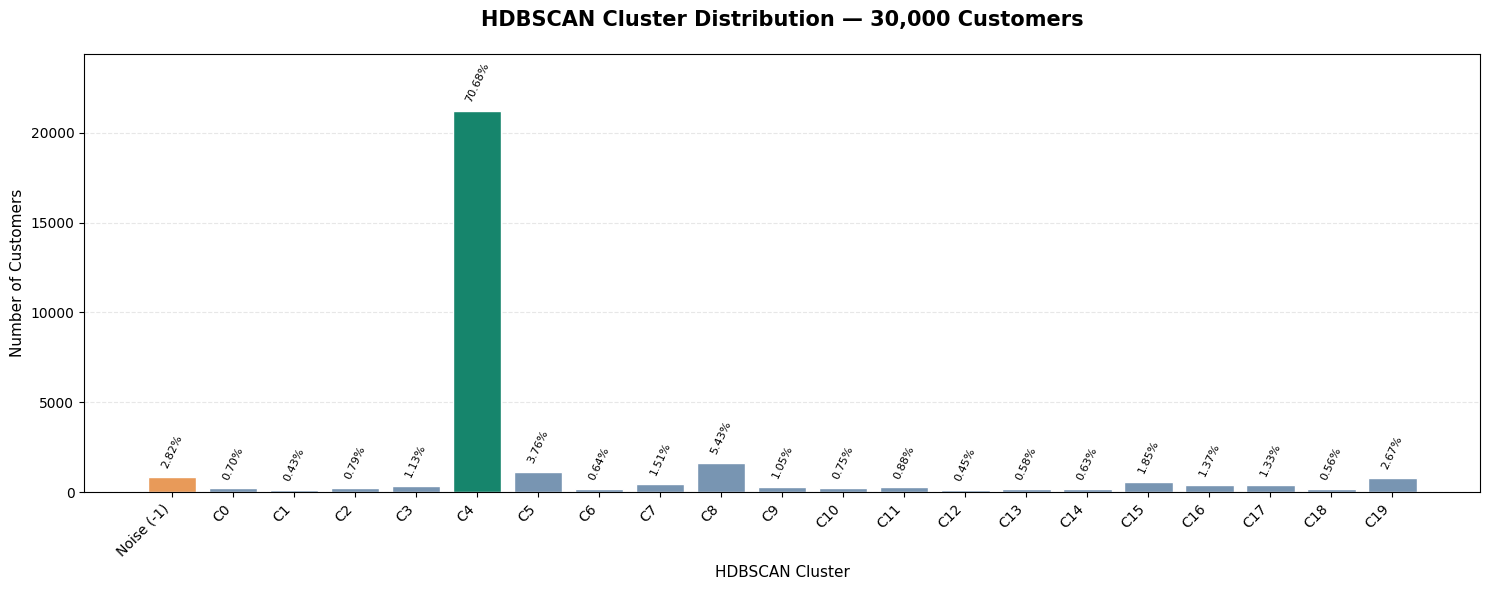


===== KIỂM TRA =====
Tổng khách hàng: 30000
Tổng tỷ lệ: 100.0 %
Số cụm: 20
Khách hàng nhiễu: 846

Đã lưu biểu đồ tại: /content/ml1_hdbscan_initial_cluster_distribution.png


In [36]:

# H2.2.1A — HDBSCAN CLUSTER DISTRIBUTION CHART

import os
import pandas as pd
import matplotlib.pyplot as plt

print("===== H2.2.1A — HDBSCAN CLUSTER DISTRIBUTION =====")

# 1. Đọc kết quả HDBSCAN đã lưu
file_path = "/content/ml1_hdbscan_initial_cluster_sizes.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Không tìm thấy kết quả HDBSCAN tại: " + file_path
    )

df = pd.read_csv(file_path)

print("Các cột:", df.columns.tolist())

# 2. Chuẩn hóa tên cột
if "cluster" not in df.columns:
    df = df.rename(columns={df.columns[0]: "cluster"})

df = df.sort_values("cluster").reset_index(drop=True)

assert {"cluster", "customer_count", "percentage"}.issubset(df.columns)

# 3. Tạo nhãn hiển thị
df["cluster_label"] = df["cluster"].apply(
    lambda x: "Noise (-1)" if x == -1 else f"C{x}"
)

# 4. Tô màu nổi bật cụm lớn nhất và nhóm nhiễu
colors = []

for cluster in df["cluster"]:
    if cluster == -1:
        colors.append("#E89A59")
    elif cluster == 4:
        colors.append("#16856C")
    else:
        colors.append("#7895B2")

# 5. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(15, 6))

bars = ax.bar(
    df["cluster_label"],
    df["customer_count"],
    color=colors,
    edgecolor="white"
)

# 6. Thêm nhãn phần trăm phía trên cột
for bar, pct in zip(bars, df["percentage"]):
    height = bar.get_height()

    ax.annotate(
        f"{pct:.2f}%",
        xy=(bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=65
    )

# 7. Định dạng
ax.set_title(
    "HDBSCAN Cluster Distribution — 30,000 Customers",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("HDBSCAN Cluster", fontsize=11)
ax.set_ylabel("Number of Customers", fontsize=11)

ax.set_ylim(0, df["customer_count"].max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# 8. Lưu biểu đồ
output_path = "/content/ml1_hdbscan_initial_cluster_distribution.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Kiểm tra
print("\n===== KIỂM TRA =====")
print("Tổng khách hàng:", int(df["customer_count"].sum()))
print("Tổng tỷ lệ:", round(df["percentage"].sum(), 3), "%")
print("Số cụm:", int((df["cluster"] != -1).sum()))
print("Khách hàng nhiễu:", int(
    df.loc[df["cluster"] == -1, "customer_count"].sum()
))

print("\nĐã lưu biểu đồ tại:", output_path)


In [37]:

# H2.2.2 — HDBSCAN CLUSTER VECTOR DIVERSITY

import os
import numpy as np
import pandas as pd

print("===== H2.2.2 — VECTOR DIVERSITY =====")

# 1. Đọc dữ liệu
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

labels_df = pd.read_csv(
    "/content/ml1_hdbscan_initial_labels.csv"
)

labels_df = labels_df.sort_values(
    "sample_position"
).reset_index(drop=True)

assert X.shape == (30000, 15)
assert len(labels_df) == len(X)
assert np.array_equal(
    labels_df["sample_position"].to_numpy(),
    np.arange(len(X))
)

labels = labels_df["hdbscan_cluster"].to_numpy()

# 2. Xác định vector phổ biến nhất
unique_X, inverse, counts = np.unique(
    X,
    axis=0,
    return_inverse=True,
    return_counts=True
)

most_common_id = np.argmax(counts)
common_mask = inverse == most_common_id
cluster4_mask = labels == 4

print("\n===== KIỂM TRA CLUSTER 4 =====")
print(
    "Số khách hàng Cluster 4:",
    int(cluster4_mask.sum())
)
print(
    "Số khách hàng có vector phổ biến nhất:",
    int(common_mask.sum())
)
print(
    "Số khách hàng thuộc cả hai nhóm:",
    int(np.sum(common_mask & cluster4_mask))
)
print(
    "Số vector khác nhau trong Cluster 4:",
    len(np.unique(X[cluster4_mask], axis=0))
)

# 3. Thống kê vector của từng cụm
results = []

for c in sorted(np.unique(labels)):
    mask = labels == c
    n = int(mask.sum())

    n_unique = len(
        np.unique(X[mask], axis=0)
    )

    results.append({
        "cluster": int(c),
        "customers": n,
        "unique_vectors": n_unique,
        "duplicate_vectors": n - n_unique,
        "unique_vector_pct": n_unique / n * 100
    })

diversity_df = pd.DataFrame(results)

print("\n===== VECTOR DIVERSITY BY CLUSTER =====")
print(
    diversity_df.round(3).to_string(index=False)
)

# 4. Kiểm tra tổng
print("\n===== KIỂM TRA =====")
print(
    "Tổng khách hàng:",
    int(diversity_df["customers"].sum())
)
print(
    "Số cụm không tính nhiễu:",
    int((diversity_df["cluster"] != -1).sum())
)

print(
    "Số cụm chỉ chứa 1 vector khác biệt:",
    int((
        (diversity_df["unique_vectors"] == 1) &
        (diversity_df["cluster"] != -1)
    ).sum())
)

# 5. Lưu kết quả
output_path = (
    "/content/ml1_hdbscan_cluster_vector_diversity.csv"
)

diversity_df.to_csv(output_path, index=False)

print("\nĐã lưu tại:", output_path)
print("===== HOÀN THÀNH H2.2.2 =====")


===== H2.2.2 — VECTOR DIVERSITY =====

===== KIỂM TRA CLUSTER 4 =====
Số khách hàng Cluster 4: 21204
Số khách hàng có vector phổ biến nhất: 21204
Số khách hàng thuộc cả hai nhóm: 21204
Số vector khác nhau trong Cluster 4: 1

===== VECTOR DIVERSITY BY CLUSTER =====
 cluster  customers  unique_vectors  duplicate_vectors  unique_vector_pct
      -1        846             802                 44             94.799
       0        211             211                  0            100.000
       1        128             128                  0            100.000
       2        238             238                  0            100.000
       3        340             340                  0            100.000
       4      21204               1              21203              0.005
       5       1128            1120                  8             99.291
       6        193             193                  0            100.000
       7        452             452                  0            100

In [38]:

# H2.2.3 — HDBSCAN RAW BEHAVIOR PROFILE

import os
import numpy as np
import pandas as pd

print("===== H2.2.3 — HDBSCAN BEHAVIOR PROFILE =====")

# 1. Đọc dữ liệu HDBSCAN và chỉ số mẫu
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

indices = np.load(
    "/content/ml1_sample_indices_30000.npy"
)

labels_df = pd.read_csv(
    "/content/ml1_hdbscan_initial_labels.csv"
).sort_values("sample_position").reset_index(drop=True)

assert X.shape == (30000, 15)
assert len(indices) == 30000
assert len(labels_df) == 30000
assert np.array_equal(
    labels_df["sample_position"].to_numpy(),
    np.arange(30000)
)

# 2. Kiểm tra các biến từ những bước trước
if "ml1_data" not in globals():
    raise NameError(
        "Không tìm thấy ml1_data trong RAM."
    )

if "customer_features" not in globals():
    raise NameError(
        "Không tìm thấy customer_features trong RAM."
    )

# 3. Kiểm tra đúng thứ tự vector và khách hàng
scaled_cols = [
    c for c in ml1_data.columns
    if c != "visitorid"
]

sample_scaled = (
    ml1_data.iloc[indices][scaled_cols]
    .to_numpy(dtype=np.float64)
)

if not np.allclose(
    sample_scaled, X,
    rtol=1e-5,
    atol=1e-7
):
    raise ValueError(
        "Thứ tự đặc trưng hoặc khách hàng không khớp. "
        "Dừng để kiểm tra, tránh gán sai nhãn."
    )

sample_ids = (
    ml1_data.iloc[indices]["visitorid"].to_numpy()
)

assert len(np.unique(sample_ids)) == 30000

print("\n===== KIỂM TRA GHÉP DỮ LIỆU =====")
print("Vector chuẩn hóa khớp:", True)
print("Số khách hàng mẫu:", len(sample_ids))

# 4. Lấy đặc trưng hành vi chưa chuẩn hóa
behavior_cols = [
    "total_events",
    "total_sessions",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

raw_features = customer_features.set_index(
    "visitorid"
)

sample_raw = (
    raw_features
    .loc[sample_ids, behavior_cols]
    .copy()
    .reset_index()
)

assert np.array_equal(
    sample_raw["visitorid"].to_numpy(),
    sample_ids
)

# 5. Gắn nhãn HDBSCAN
sample_raw["hdbscan_cluster"] = (
    labels_df["hdbscan_cluster"].to_numpy()
)

sample_raw["has_cart"] = (
    sample_raw["total_addtocart"] > 0
).astype(int)

sample_raw["has_purchase"] = (
    sample_raw["total_transaction_events"] > 0
).astype(int)

# 6. Tổng hợp hồ sơ hành vi theo cụm
profile = (
    sample_raw
    .groupby("hdbscan_cluster")
    .agg(
        customers=("visitorid", "size"),
        mean_events=("total_events", "mean"),
        median_events=("total_events", "median"),
        mean_sessions=("total_sessions", "mean"),
        mean_views=("total_views", "mean"),
        mean_cart=("total_addtocart", "mean"),
        mean_transactions=(
            "total_transaction_events", "mean"
        ),
        mean_unique_items=("unique_items", "mean"),
        pct_with_cart=("has_cart", "mean"),
        pct_with_purchase=("has_purchase", "mean")
    )
)

profile["pct_with_cart"] *= 100
profile["pct_with_purchase"] *= 100

profile.index.name = "cluster"

print("\n===== HỒ SƠ HÀNH VI 20 CỤM VÀ NHIỄU =====")
print(profile.round(3).to_string())

# 7. Kiểm tra riêng Cluster 4
cluster4 = sample_raw[
    sample_raw["hdbscan_cluster"] == 4
]

print("\n===== CLUSTER 4 — HÀNH VI ĐẠI DIỆN =====")
print("Số khách hàng:", len(cluster4))

for col in behavior_cols:
    print(
        f"{col}:",
        cluster4[col].iloc[0],
        "| Số giá trị khác nhau:",
        cluster4[col].nunique()
    )

# 8. Kiểm tra tổng
print("\n===== KIỂM TRA =====")
print("Tổng khách hàng:", len(sample_raw))
print("Số khách hàng thiếu dữ liệu:",
      sample_raw[behavior_cols].isna().any(axis=1).sum())

# 9. Lưu kết quả
profile_path = (
    "/content/ml1_hdbscan_initial_behavior_profile.csv"
)

sample_path = (
    "/content/ml1_hdbscan_initial_customer_behavior.csv"
)

profile.to_csv(profile_path)
sample_raw.to_csv(sample_path, index=False)

print("\n===== FILE ĐÃ LƯU =====")
print(profile_path)
print(sample_path)

print("\n===== HOÀN THÀNH H2.2.3 =====")


===== H2.2.3 — HDBSCAN BEHAVIOR PROFILE =====

===== KIỂM TRA GHÉP DỮ LIỆU =====
Vector chuẩn hóa khớp: True
Số khách hàng mẫu: 30000

===== HỒ SƠ HÀNH VI 20 CỤM VÀ NHIỄU =====
         customers  mean_events  median_events  mean_sessions  mean_views  mean_cart  mean_transactions  mean_unique_items  pct_with_cart  pct_with_purchase
cluster                                                                                                                                                     
-1             846       18.061            9.0          4.716      16.863      0.910              0.288             10.327         26.714                1.3
 0             211        9.493            7.0          2.720       7.019      1.265              1.209              3.782         89.573              100.0
 1             128        2.055            2.0          1.016       1.031      1.023              0.000              1.102        100.000                0.0
 2             238        5.227       

===== H2.2.3A — CART & PURCHASE BEHAVIOR =====


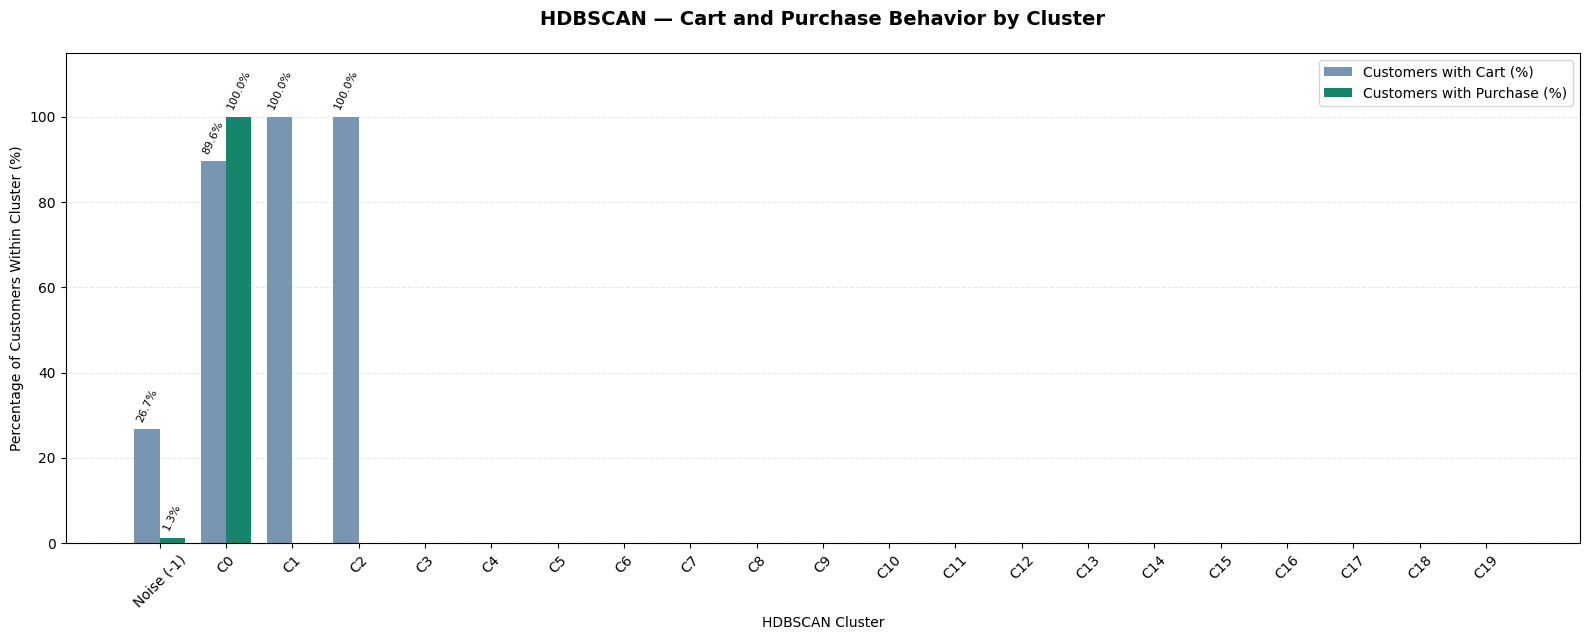


===== KIỂM TRA =====
Tổng khách hàng: 30000
Số cụm có khách hàng từng thêm giỏ: 3
Số cụm có khách hàng từng mua: 1

Đã lưu biểu đồ tại: /content/ml1_hdbscan_cart_purchase_by_cluster.png
===== HOÀN THÀNH H2.2.3A =====


In [39]:

# H2.2.3A — HDBSCAN CART & PURCHASE BEHAVIOR CHART

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("===== H2.2.3A — CART & PURCHASE BEHAVIOR =====")

# 1. Đọc hồ sơ hành vi HDBSCAN
file_path = "/content/ml1_hdbscan_initial_behavior_profile.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Không tìm thấy file hồ sơ hành vi HDBSCAN."
    )

df = pd.read_csv(file_path)

required = [
    "cluster",
    "customers",
    "pct_with_cart",
    "pct_with_purchase"
]

assert set(required).issubset(df.columns)

df = df.sort_values("cluster").reset_index(drop=True)

# 2. Tạo nhãn
df["cluster_label"] = df["cluster"].apply(
    lambda c: "Noise (-1)" if c == -1 else f"C{c}"
)

# 3. Chuẩn bị vị trí cột
x = np.arange(len(df))
width = 0.38

# 4. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(16, 6.5))

bars_cart = ax.bar(
    x - width / 2,
    df["pct_with_cart"],
    width,
    label="Customers with Cart (%)",
    color="#7895B2"
)

bars_purchase = ax.bar(
    x + width / 2,
    df["pct_with_purchase"],
    width,
    label="Customers with Purchase (%)",
    color="#16856C"
)

# 5. Thêm nhãn cho các giá trị khác 0
for bars in [bars_cart, bars_purchase]:
    for bar in bars:
        height = bar.get_height()

        if height > 0:
            ax.annotate(
                f"{height:.1f}%",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=65
            )

# 6. Định dạng
ax.set_title(
    "HDBSCAN — Cart and Purchase Behavior by Cluster",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("HDBSCAN Cluster")
ax.set_ylabel("Percentage of Customers Within Cluster (%)")

ax.set_xticks(x)
ax.set_xticklabels(df["cluster_label"], rotation=45)

ax.set_ylim(0, 115)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()

# 7. Lưu biểu đồ
output_path = (
    "/content/ml1_hdbscan_cart_purchase_by_cluster.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Kiểm tra
print("\n===== KIỂM TRA =====")
print("Tổng khách hàng:", int(df["customers"].sum()))

print(
    "Số cụm có khách hàng từng thêm giỏ:",
    int(((df["pct_with_cart"] > 0) &
         (df["cluster"] != -1)).sum())
)

print(
    "Số cụm có khách hàng từng mua:",
    int(((df["pct_with_purchase"] > 0) &
         (df["cluster"] != -1)).sum())
)

print("\nĐã lưu biểu đồ tại:", output_path)
print("===== HOÀN THÀNH H2.2.3A =====")


In [40]:

# H2.3.1 — HDBSCAN PARAMETER EXPERIMENT (MCS=200)

import os
import time
import numpy as np
import pandas as pd
import hdbscan

print("===== H2.3.1 — HDBSCAN PARAMETER EXPERIMENT =====")

# 1. Đọc đúng mẫu đã sử dụng trước đó
data_path = "/content/ml1_hdbscan_sample_30000.npy"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        "Không tìm thấy mẫu 30.000 khách hàng."
    )

X_hdbscan = np.load(data_path)

assert X_hdbscan.shape == (30000, 15)
assert np.isfinite(X_hdbscan).all()

# 2. Cấu hình thử nghiệm mới
min_cluster_size = 200
min_samples = 15

model_hdbscan_200 = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size,
    min_samples=min_samples,
    metric="euclidean",
    cluster_selection_method="eom",
    algorithm="best",
    approx_min_span_tree=True,
    core_dist_n_jobs=2,
    prediction_data=False
)

print("\n===== THAM SỐ =====")
print("min_cluster_size:", min_cluster_size)
print("min_samples:", min_samples)

# 3. Huấn luyện
print("\nĐang huấn luyện...")

start = time.perf_counter()

labels_200 = model_hdbscan_200.fit_predict(
    X_hdbscan
)

training_time = time.perf_counter() - start

# 4. Thống kê kết quả
n_clusters = len(set(labels_200) - {-1})
n_noise = int(np.sum(labels_200 == -1))
noise_pct = n_noise / len(labels_200) * 100

sizes = (
    pd.Series(labels_200, name="cluster")
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

sizes["percentage"] = (
    sizes["customer_count"]
    / len(labels_200) * 100
)

sizes.index.name = "cluster"

print("\n===== KẾT QUẢ HDBSCAN MCS=200 =====")
print("Thời gian:", round(training_time, 2), "giây")
print("Số cụm:", n_clusters)
print("Số khách hàng nhiễu:", n_noise)
print("Tỷ lệ nhiễu:", round(noise_pct, 3), "%")

print("\n===== QUY MÔ TỪNG CỤM =====")
print(sizes.round(3).to_string())

# 5. Đọc kết quả cấu hình ban đầu để so sánh
initial_path = (
    "/content/ml1_hdbscan_initial_cluster_sizes.csv"
)

if not os.path.exists(initial_path):
    raise FileNotFoundError(
        "Không tìm thấy bảng kết quả H2.2.1."
    )

initial_sizes = pd.read_csv(initial_path)

initial_clusters = int(
    (initial_sizes["cluster"] != -1).sum()
)

initial_noise = int(
    initial_sizes.loc[
        initial_sizes["cluster"] == -1,
        "customer_count"
    ].sum()
)

initial_largest = int(
    initial_sizes.loc[
        initial_sizes["cluster"] != -1,
        "customer_count"
    ].max()
)

new_largest = (
    int(sizes.loc[
        sizes.index != -1,
        "customer_count"
    ].max())
    if n_clusters > 0 else 0
)

comparison = pd.DataFrame([
    {
        "min_cluster_size": 100,
        "min_samples": 15,
        "n_clusters": initial_clusters,
        "noise_pct": initial_noise / 30000 * 100,
        "largest_cluster": initial_largest
    },
    {
        "min_cluster_size": 200,
        "min_samples": 15,
        "n_clusters": n_clusters,
        "noise_pct": noise_pct,
        "largest_cluster": new_largest
    }
])

print("\n===== SO SÁNH HAI CẤU HÌNH =====")
print(comparison.round(3).to_string(index=False))

# 6. Lưu nhãn và kết quả
labels_df = pd.DataFrame({
    "sample_position": np.arange(len(labels_200)),
    "hdbscan_cluster": labels_200,
    "membership_probability": model_hdbscan_200.probabilities_
})

labels_path = "/content/ml1_hdbscan_mcs200_labels.csv"
sizes_path = "/content/ml1_hdbscan_mcs200_cluster_sizes.csv"
compare_path = "/content/ml1_hdbscan_parameter_comparison.csv"

labels_df.to_csv(labels_path, index=False)
sizes.to_csv(sizes_path)
comparison.to_csv(compare_path, index=False)

print("\n===== KIỂM TRA =====")
print("Tổng khách hàng:", int(sizes["customer_count"].sum()))
print("Số nhãn thiếu:", int(labels_df.isna().sum().sum()))

print("\n===== ĐÃ LƯU =====")
print(labels_path)
print(sizes_path)
print(compare_path)

print("\n===== HOÀN THÀNH H2.3.1 =====")


===== H2.3.1 — HDBSCAN PARAMETER EXPERIMENT =====

===== THAM SỐ =====
min_cluster_size: 200
min_samples: 15

Đang huấn luyện...

===== KẾT QUẢ HDBSCAN MCS=200 =====
Thời gian: 19.39 giây
Số cụm: 15
Số khách hàng nhiễu: 540
Tỷ lệ nhiễu: 1.8 %

===== QUY MÔ TỪNG CỤM =====
         customer_count  percentage
cluster                            
-1                  540       1.800
 0                  211       0.703
 1                  554       1.847
 2                  340       1.133
 3                  439       1.463
 4                21204      70.680
 5                 1324       4.413
 6                  452       1.507
 7                 1628       5.427
 8                  378       1.260
 9                  315       1.050
 10                 225       0.750
 11                 555       1.850
 12                 410       1.367
 13                1027       3.423
 14                 398       1.327

===== SO SÁNH HAI CẤU HÌNH =====
 min_cluster_size  min_samples  n_clusters  no

In [41]:

# H2.3.2 — HDBSCAN PARAMETER EXPERIMENT (MCS=400)

import os
import time
import numpy as np
import pandas as pd
import hdbscan

print("===== H2.3.2 — HDBSCAN MCS=400 =====")

# 1. Đọc dữ liệu
data_path = "/content/ml1_hdbscan_sample_30000.npy"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        "Không tìm thấy mẫu HDBSCAN 30.000 khách hàng."
    )

X_hdbscan = np.load(data_path)

assert X_hdbscan.shape == (30000, 15)
assert np.isfinite(X_hdbscan).all()

# 2. Thiết lập tham số
min_cluster_size = 400
min_samples = 15

model_hdbscan_400 = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size,
    min_samples=min_samples,
    metric="euclidean",
    cluster_selection_method="eom",
    algorithm="best",
    approx_min_span_tree=True,
    core_dist_n_jobs=2,
    prediction_data=False
)

print("\n===== CẤU HÌNH =====")
print("min_cluster_size:", min_cluster_size)
print("min_samples:", min_samples)
print("metric: euclidean")

# 3. Huấn luyện
print("\nĐang huấn luyện HDBSCAN...")

start = time.perf_counter()

labels_400 = model_hdbscan_400.fit_predict(
    X_hdbscan
)

training_time = time.perf_counter() - start

print("Huấn luyện hoàn tất!")

# 4. Tổng hợp số cụm và nhiễu
n_clusters = len(set(labels_400) - {-1})
n_noise = int(np.sum(labels_400 == -1))
noise_pct = n_noise / len(labels_400) * 100

sizes_400 = (
    pd.Series(labels_400, name="cluster")
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

sizes_400["percentage"] = (
    sizes_400["customer_count"]
    / len(labels_400) * 100
)

sizes_400.index.name = "cluster"

print("\n===== KẾT QUẢ MCS=400 =====")
print("Thời gian:", round(training_time, 2), "giây")
print("Số cụm:", n_clusters)
print("Khách hàng nhiễu:", n_noise)
print("Tỷ lệ nhiễu:", round(noise_pct, 3), "%")

print("\n===== QUY MÔ CÁC CỤM =====")
print(sizes_400.round(3).to_string())

# 5. Đọc bảng so sánh trước đó
comparison_path = (
    "/content/ml1_hdbscan_parameter_comparison.csv"
)

if not os.path.exists(comparison_path):
    raise FileNotFoundError(
        "Không tìm thấy bảng so sánh H2.3.1."
    )

comparison = pd.read_csv(comparison_path)

# 6. Thêm kết quả MCS=400
largest_cluster = (
    int(
        sizes_400.loc[
            sizes_400.index != -1,
            "customer_count"
        ].max()
    )
    if n_clusters > 0 else 0
)

new_result = pd.DataFrame([{
    "min_cluster_size": 400,
    "min_samples": 15,
    "n_clusters": n_clusters,
    "noise_pct": noise_pct,
    "largest_cluster": largest_cluster
}])

comparison = pd.concat(
    [
        comparison[
            comparison["min_cluster_size"] != 400
        ],
        new_result
    ],
    ignore_index=True
)

comparison = comparison.sort_values(
    "min_cluster_size"
).reset_index(drop=True)

print("\n===== SO SÁNH BA CẤU HÌNH =====")
print(comparison.round(3).to_string(index=False))

# 7. Lưu nhãn và xác suất thuộc cụm
labels_df = pd.DataFrame({
    "sample_position": np.arange(len(labels_400)),
    "hdbscan_cluster": labels_400,
    "membership_probability": (
        model_hdbscan_400.probabilities_
    )
})

labels_path = "/content/ml1_hdbscan_mcs400_labels.csv"
sizes_path = "/content/ml1_hdbscan_mcs400_cluster_sizes.csv"

labels_df.to_csv(labels_path, index=False)
sizes_400.to_csv(sizes_path)
comparison.to_csv(comparison_path, index=False)

# 8. Kiểm tra cuối
print("\n===== KIỂM TRA =====")
print("Tổng khách hàng:", int(sizes_400["customer_count"].sum()))
print("Số nhãn thiếu:", int(labels_df.isna().sum().sum()))

print("\n===== ĐÃ LƯU =====")
print(labels_path)
print(sizes_path)
print(comparison_path)

print("\n===== HOÀN THÀNH H2.3.2 =====")


===== H2.3.2 — HDBSCAN MCS=400 =====

===== CẤU HÌNH =====
min_cluster_size: 400
min_samples: 15
metric: euclidean

Đang huấn luyện HDBSCAN...
Huấn luyện hoàn tất!

===== KẾT QUẢ MCS=400 =====
Thời gian: 15.22 giây
Số cụm: 10
Khách hàng nhiễu: 998
Tỷ lệ nhiễu: 3.327 %

===== QUY MÔ CÁC CỤM =====
         customer_count  percentage
cluster                            
-1                  998       3.327
 0                  554       1.847
 1                  439       1.463
 2                21204      70.680
 3                 1324       4.413
 4                  935       3.117
 5                  452       1.507
 6                 1628       5.427
 7                  555       1.850
 8                  410       1.367
 9                 1501       5.003

===== SO SÁNH BA CẤU HÌNH =====
 min_cluster_size  min_samples  n_clusters  noise_pct  largest_cluster
              100           15          20      2.820            21204
              200           15          15      1.800       

===== H2.3.3 — PARAMETER SENSITIVITY =====

===== DỮ LIỆU THỬ NGHIỆM =====
 min_cluster_size  min_samples  n_clusters  noise_pct  largest_cluster
              100           15          20   2.820000            21204
              200           15          15   1.800000            21204
              400           15          10   3.326667            21204


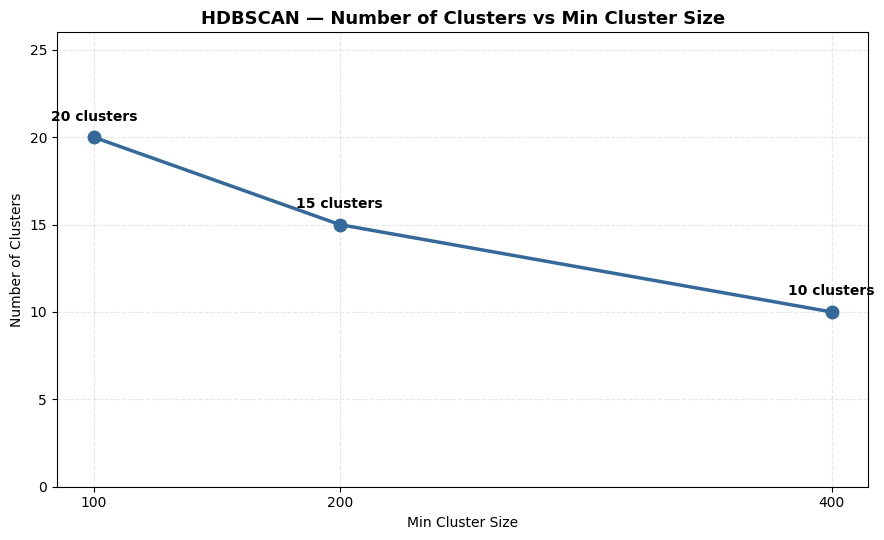

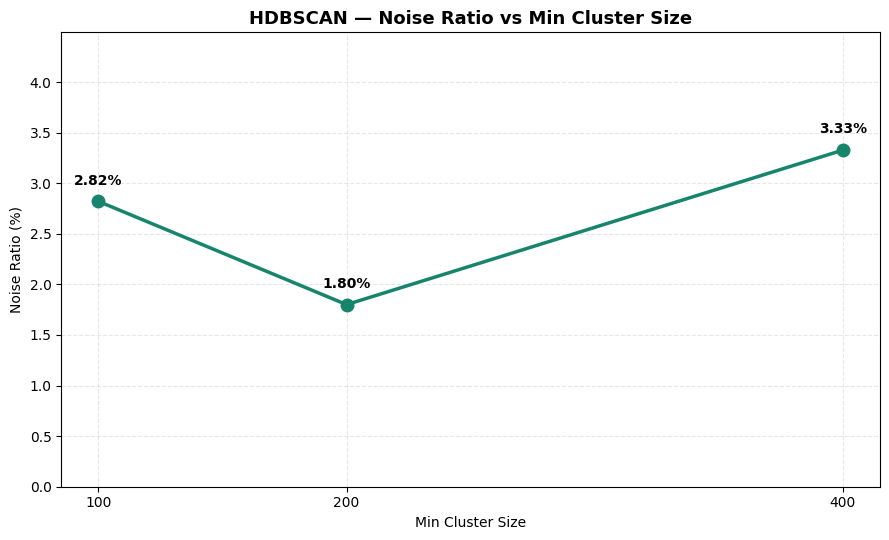


===== TỔNG KẾT =====
Cấu hình có tỷ lệ nhiễu thấp nhất: 200
Tỷ lệ nhiễu thấp nhất: 1.8 %
Cấu hình có ít cụm nhất: 400
Số cụm ít nhất: 10

===== FILE ĐÃ LƯU =====
/content/ml1_hdbscan_mcs_vs_clusters.png
/content/ml1_hdbscan_mcs_vs_noise.png

===== HOÀN THÀNH H2.3.3 =====


In [42]:

# H2.3.3 — HDBSCAN PARAMETER SENSITIVITY CHARTS


import os
import pandas as pd
import matplotlib.pyplot as plt

print("===== H2.3.3 — PARAMETER SENSITIVITY =====")

# 1. Đọc bảng kết quả
input_path = "/content/ml1_hdbscan_parameter_comparison.csv"

if not os.path.exists(input_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {input_path}"
    )

df = pd.read_csv(input_path)

required_cols = [
    "min_cluster_size",
    "min_samples",
    "n_clusters",
    "noise_pct",
    "largest_cluster"
]

assert set(required_cols).issubset(df.columns)
assert not df[required_cols].isna().any().any()

df = df.sort_values("min_cluster_size").reset_index(drop=True)

print("\n===== DỮ LIỆU THỬ NGHIỆM =====")
print(df.to_string(index=False))

# Kiểm tra 3 cấu hình cần vẽ
assert set(df["min_cluster_size"]) == {100, 200, 400}
assert (df["min_samples"] == 15).all()

x = df["min_cluster_size"].to_numpy()

# BIỂU ĐỒ 1 — SỐ CỤM

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    x,
    df["n_clusters"],
    marker="o",
    markersize=9,
    linewidth=2.5,
    color="#34699A"
)

for mcs, clusters in zip(x, df["n_clusters"]):
    ax.annotate(
        f"{int(clusters)} clusters",
        xy=(mcs, clusters),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "HDBSCAN — Number of Clusters vs Min Cluster Size",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Min Cluster Size")
ax.set_ylabel("Number of Clusters")
ax.set_xticks(x)
ax.set_ylim(0, max(df["n_clusters"]) * 1.3)
ax.grid(linestyle="--", alpha=0.3)

plt.tight_layout()

path1 = "/content/ml1_hdbscan_mcs_vs_clusters.png"

plt.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()

# BIỂU ĐỒ 2 — TỶ LỆ NHIỄU

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    x,
    df["noise_pct"],
    marker="o",
    markersize=9,
    linewidth=2.5,
    color="#16856C"
)

for mcs, noise in zip(x, df["noise_pct"]):
    ax.annotate(
        f"{noise:.2f}%",
        xy=(mcs, noise),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "HDBSCAN — Noise Ratio vs Min Cluster Size",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Min Cluster Size")
ax.set_ylabel("Noise Ratio (%)")
ax.set_xticks(x)
ax.set_ylim(0, max(df["noise_pct"]) * 1.35)
ax.grid(linestyle="--", alpha=0.3)

plt.tight_layout()

path2 = "/content/ml1_hdbscan_mcs_vs_noise.png"

plt.savefig(path2, dpi=300, bbox_inches="tight")
plt.show()


# KIỂM TRA

print("\n===== TỔNG KẾT =====")

best_noise = df.loc[df["noise_pct"].idxmin()]
fewest_clusters = df.loc[df["n_clusters"].idxmin()]

print(
    "Cấu hình có tỷ lệ nhiễu thấp nhất:",
    int(best_noise["min_cluster_size"])
)

print(
    "Tỷ lệ nhiễu thấp nhất:",
    round(best_noise["noise_pct"], 3), "%"
)

print(
    "Cấu hình có ít cụm nhất:",
    int(fewest_clusters["min_cluster_size"])
)

print(
    "Số cụm ít nhất:",
    int(fewest_clusters["n_clusters"])
)

print("\n===== FILE ĐÃ LƯU =====")
print(path1)
print(path2)

print("\n===== HOÀN THÀNH H2.3.3 =====")


In [43]:

# H2.4.1 — HDBSCAN SILHOUETTE EVALUATION


import os
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score

print("===== H2.4.1 — HDBSCAN SILHOUETTE EVALUATION =====")

# 1. Đọc mẫu dữ liệu đã xác nhận
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

assert X.shape == (30000, 15)
assert np.isfinite(X).all()

# 2. Đọc nhãn của ba cấu hình HDBSCAN
label_files = {
    100: "/content/ml1_hdbscan_initial_labels.csv",
    200: "/content/ml1_hdbscan_mcs200_labels.csv",
    400: "/content/ml1_hdbscan_mcs400_labels.csv"
}

labels_dict = {}

for mcs, path in label_files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(f"Không tìm thấy: {path}")

    df = pd.read_csv(path)

    df = df.sort_values(
        "sample_position"
    ).reset_index(drop=True)

    assert len(df) == len(X)

    assert np.array_equal(
        df["sample_position"].to_numpy(),
        np.arange(len(X))
    )

    labels_dict[mcs] = (
        df["hdbscan_cluster"].to_numpy()
    )

print("\nĐã đọc nhãn của 3 cấu hình HDBSCAN.")

# 3. Xác định các điểm không nhiễu
# ở CẢ BA cấu hình
common_assigned_mask = np.ones(
    len(X), dtype=bool
)

for labels in labels_dict.values():
    common_assigned_mask &= (labels != -1)

common_indices = np.flatnonzero(
    common_assigned_mask
)

print("\n===== COMMON NON-NOISE DATA =====")
print(
    "Số khách hàng không nhiễu ở cả 3 mô hình:",
    len(common_indices)
)

# 4. Xác định vector xuất hiện nhiều nhất
unique_X, inverse, counts = np.unique(
    X,
    axis=0,
    return_inverse=True,
    return_counts=True
)

dominant_vector_id = np.argmax(counts)

dominant_mask = (
    inverse == dominant_vector_id
)

print(
    "Số khách hàng có vector phổ biến nhất:",
    int(dominant_mask.sum())
)

# 5. Chuẩn bị hai tập đánh giá
# Sử dụng cùng chỉ số khách hàng cho 3 mô hình
rng = np.random.default_rng(42)

sample_n = 3000

all_eval_indices = rng.choice(
    common_indices,
    size=min(sample_n, len(common_indices)),
    replace=False
)

non_dominant_indices = common_indices[
    ~dominant_mask[common_indices]
]

other_eval_indices = rng.choice(
    non_dominant_indices,
    size=min(sample_n, len(non_dominant_indices)),
    replace=False
)

print("\n===== EVALUATION SAMPLE SIZES =====")
print(
    "Mẫu không nhiễu:",
    len(all_eval_indices)
)
print(
    "Mẫu không nhiễu, không gồm vector phổ biến nhất:",
    len(other_eval_indices)
)

# 6. Hàm tính Silhouette
def evaluate_silhouette(X_data, labels, indices):

    sample_X = X_data[indices]
    sample_labels = labels[indices]

    n_clusters = len(np.unique(sample_labels))

    if n_clusters < 2 or n_clusters >= len(indices):
        return np.nan, n_clusters

    score = silhouette_score(
        sample_X,
        sample_labels,
        metric="euclidean"
    )

    return score, n_clusters

# 7. Đánh giá từng cấu hình
results = []

for mcs in [100, 200, 400]:

    labels = labels_dict[mcs]

    score_all, k_all = evaluate_silhouette(
        X, labels, all_eval_indices
    )

    score_other, k_other = evaluate_silhouette(
        X, labels, other_eval_indices
    )

    noise_count = int(np.sum(labels == -1))

    results.append({
        "min_cluster_size": mcs,
        "min_samples": 15,
        "total_clusters": len(
            set(labels) - {-1}
        ),
        "noise_pct": noise_count / len(X) * 100,
        "silhouette_common_nonnoise": score_all,
        "clusters_in_common_sample": k_all,
        "silhouette_without_dominant": score_other,
        "clusters_without_dominant": k_other
    })

# 8. Tổng hợp kết quả
evaluation_df = pd.DataFrame(results)

print("\n===== HDBSCAN SILHOUETTE RESULTS =====")
print(
    evaluation_df
    .round(4)
    .to_string(index=False)
)

print("\n===== LƯU Ý =====")
print(
    "Các mô hình được đánh giá trên cùng "
    "tập điểm không nhiễu."
)
print(
    "Không loại bỏ khách hàng khỏi dữ liệu gốc."
)
print(
    "Silhouette sau khi bỏ vector phổ biến nhất "
    "là phép kiểm tra bổ sung."
)

# 9. Lưu kết quả
output_path = (
    "/content/ml1_hdbscan_silhouette_evaluation.csv"
)

evaluation_df.to_csv(
    output_path,
    index=False
)

print("\nĐã lưu tại:", output_path)
print("===== HOÀN THÀNH H2.4.1 =====")


===== H2.4.1 — HDBSCAN SILHOUETTE EVALUATION =====

Đã đọc nhãn của 3 cấu hình HDBSCAN.

===== COMMON NON-NOISE DATA =====
Số khách hàng không nhiễu ở cả 3 mô hình: 28603
Số khách hàng có vector phổ biến nhất: 21204

===== EVALUATION SAMPLE SIZES =====
Mẫu không nhiễu: 3000
Mẫu không nhiễu, không gồm vector phổ biến nhất: 3000

===== HDBSCAN SILHOUETTE RESULTS =====
 min_cluster_size  min_samples  total_clusters  noise_pct  silhouette_common_nonnoise  clusters_in_common_sample  silhouette_without_dominant  clusters_without_dominant
              100           15              20     2.8200                      0.9017                         18                       0.6212                         17
              200           15              15     1.8000                      0.8951                         13                       0.6087                         12
              400           15              10     3.3267                      0.8821                         10            

In [44]:

# H2.4.2 — FAIR SILHOUETTE COMPARISON K-MEANS VS HDBSCAN

import os
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score

print("===== H2.4.2 — K-MEANS VS HDBSCAN =====")

# 1. Đọc dữ liệu chung
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

assert X.shape == (30000, 15)
assert np.isfinite(X).all()

# 2. Lấy nhãn K-Means từ các mô hình cũ
if "comparison_models" not in globals():
    raise NameError(
        "Không tìm thấy comparison_models trong RAM."
    )

model_labels = {}

for k in [4, 8]:
    model = comparison_models[k]

    labels = model.predict(X)

    assert len(labels) == 30000

    model_labels[f"KMeans_K{k}"] = labels

# 3. Đọc nhãn HDBSCAN
hdbscan_files = {
    100: "/content/ml1_hdbscan_initial_labels.csv",
    200: "/content/ml1_hdbscan_mcs200_labels.csv",
    400: "/content/ml1_hdbscan_mcs400_labels.csv"
}

hdbscan_labels = {}

for mcs, path in hdbscan_files.items():

    df = pd.read_csv(path)

    df = df.sort_values(
        "sample_position"
    ).reset_index(drop=True)

    assert len(df) == 30000

    assert np.array_equal(
        df["sample_position"].to_numpy(),
        np.arange(30000)
    )

    labels = df["hdbscan_cluster"].to_numpy()

    hdbscan_labels[mcs] = labels
    model_labels[f"HDBSCAN_MCS{mcs}"] = labels

# 4. Tạo tập khách hàng không nhiễu chung
common_mask = np.ones(len(X), dtype=bool)

for labels in hdbscan_labels.values():
    common_mask &= (labels != -1)

common_indices = np.flatnonzero(common_mask)

# 5. Xác định vector phổ biến nhất
_, inverse, counts = np.unique(
    X,
    axis=0,
    return_inverse=True,
    return_counts=True
)

dominant_mask = inverse == np.argmax(counts)

non_dominant_indices = common_indices[
    ~dominant_mask[common_indices]
]

# 6. Tạo hai tập đánh giá cố định
rng = np.random.default_rng(42)
sample_size = 3000

eval_all = rng.choice(
    common_indices,
    size=min(sample_size, len(common_indices)),
    replace=False
)

eval_non_dominant = rng.choice(
    non_dominant_indices,
    size=min(sample_size, len(non_dominant_indices)),
    replace=False
)

print("\n===== EVALUATION DATA =====")
print("Tập chung không nhiễu:", len(common_indices))
print("Mẫu đánh giá chính:", len(eval_all))
print("Mẫu không có vector phổ biến:", len(eval_non_dominant))

print(
    "Tỷ lệ vector phổ biến trong mẫu chính:",
    round(dominant_mask[eval_all].mean() * 100, 2),
    "%"
)

# 7. Hàm tính Silhouette
def calculate_score(X_data, labels, indices):

    y = labels[indices]
    n_clusters = len(np.unique(y))

    if n_clusters < 2 or n_clusters >= len(indices):
        return np.nan, n_clusters

    score = silhouette_score(
        X_data[indices],
        y,
        metric="euclidean"
    )

    return score, n_clusters

# 8. Đánh giá năm mô hình
results = []

for model_name, labels in model_labels.items():

    score_all, n_all = calculate_score(
        X, labels, eval_all
    )

    score_non_dominant, n_non_dominant = calculate_score(
        X, labels, eval_non_dominant
    )

    results.append({
        "model": model_name,
        "silhouette_common_sample": score_all,
        "clusters_common_sample": n_all,
        "silhouette_without_dominant": score_non_dominant,
        "clusters_without_dominant": n_non_dominant
    })

comparison_df = pd.DataFrame(results)

print("\n===== MODEL COMPARISON =====")
print(
    comparison_df
    .round(4)
    .to_string(index=False)
)

# 9. Kiểm tra kết quả HDBSCAN với H2.4.1
old_path = (
    "/content/ml1_hdbscan_silhouette_evaluation.csv"
)

if os.path.exists(old_path):
    old = pd.read_csv(old_path)

    print("\n===== KIỂM TRA HDBSCAN VỚI H2.4.1 =====")

    for mcs in [100, 200, 400]:
        old_score = old.loc[
            old["min_cluster_size"] == mcs,
            "silhouette_common_nonnoise"
        ].iloc[0]

        new_score = comparison_df.loc[
            comparison_df["model"] == f"HDBSCAN_MCS{mcs}",
            "silhouette_common_sample"
        ].iloc[0]

        print(
            f"MCS={mcs}:",
            "Chênh lệch =",
            round(abs(old_score - new_score), 10)
        )

# 10. Lưu kết quả
output_path = (
    "/content/ml1_kmeans_vs_hdbscan_silhouette.csv"
)

comparison_df.to_csv(
    output_path,
    index=False
)

print("\n===== HOÀN THÀNH H2.4.2 =====")
print("Đã lưu tại:", output_path)


===== H2.4.2 — K-MEANS VS HDBSCAN =====

===== EVALUATION DATA =====
Tập chung không nhiễu: 28603
Mẫu đánh giá chính: 3000
Mẫu không có vector phổ biến: 3000
Tỷ lệ vector phổ biến trong mẫu chính: 74.27 %

===== MODEL COMPARISON =====
         model  silhouette_common_sample  clusters_common_sample  silhouette_without_dominant  clusters_without_dominant
     KMeans_K4                    0.7989                       3                       0.4352                          3
     KMeans_K8                    0.8240                       6                       0.4248                          6
HDBSCAN_MCS100                    0.9017                      18                       0.6212                         17
HDBSCAN_MCS200                    0.8951                      13                       0.6087                         12
HDBSCAN_MCS400                    0.8821                      10                       0.5665                          9

===== KIỂM TRA HDBSCAN VỚI H2.4.1 ====

===== H2.4.3 — MODEL COMPARISON CHART =====


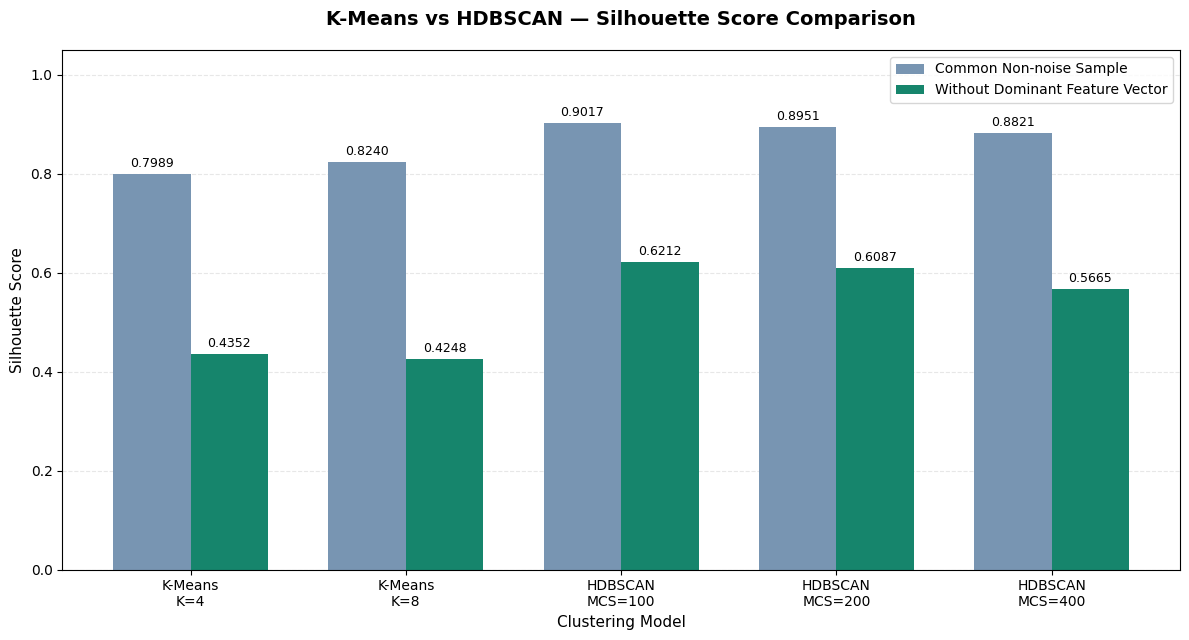


===== MODEL RANKING — COMMON SAMPLE =====
         model  silhouette_common_sample  silhouette_without_dominant
HDBSCAN_MCS100                    0.9017                       0.6212
HDBSCAN_MCS200                    0.8951                       0.6087
HDBSCAN_MCS400                    0.8821                       0.5665
     KMeans_K8                    0.8240                       0.4248
     KMeans_K4                    0.7989                       0.4352

===== KIỂM TRA =====
Số mô hình: 5
Mô hình Silhouette cao nhất: HDBSCAN_MCS100

Đã lưu biểu đồ tại: /content/ml1_kmeans_vs_hdbscan_silhouette_chart.png
===== HOÀN THÀNH H2.4.3 =====


In [45]:

# H2.4.3 — K-MEANS VS HDBSCAN SILHOUETTE CHART


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("===== H2.4.3 — MODEL COMPARISON CHART =====")

# 1. Đọc dữ liệu từ H2.4.2
input_path = (
    "/content/ml1_kmeans_vs_hdbscan_silhouette.csv"
)

if not os.path.exists(input_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {input_path}"
    )

df = pd.read_csv(input_path)

required_cols = [
    "model",
    "silhouette_common_sample",
    "silhouette_without_dominant"
]

assert set(required_cols).issubset(df.columns)
assert not df[required_cols].isna().any().any()

# 2. Thiết lập nhãn hiển thị
name_map = {
    "KMeans_K4": "K-Means\nK=4",
    "KMeans_K8": "K-Means\nK=8",
    "HDBSCAN_MCS100": "HDBSCAN\nMCS=100",
    "HDBSCAN_MCS200": "HDBSCAN\nMCS=200",
    "HDBSCAN_MCS400": "HDBSCAN\nMCS=400"
}

df["display_name"] = (
    df["model"].map(name_map).fillna(df["model"])
)

# 3. Chuẩn bị dữ liệu
x = np.arange(len(df))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 6.5))

bars1 = ax.bar(
    x - width / 2,
    df["silhouette_common_sample"],
    width,
    label="Common Non-noise Sample",
    color="#7895B2"
)

bars2 = ax.bar(
    x + width / 2,
    df["silhouette_without_dominant"],
    width,
    label="Without Dominant Feature Vector",
    color="#16856C"
)

# 4. Gắn nhãn giá trị lên từng cột
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            f"{value:.4f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="medium"
        )

# 5. Định dạng biểu đồ
ax.set_title(
    "K-Means vs HDBSCAN — Silhouette Score Comparison",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Clustering Model", fontsize=11)
ax.set_ylabel("Silhouette Score", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(df["display_name"])

ax.set_ylim(0, 1.05)
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)
ax.set_axisbelow(True)

ax.legend(loc="upper right")

plt.tight_layout()

# 6. Lưu biểu đồ
output_path = (
    "/content/ml1_kmeans_vs_hdbscan_silhouette_chart.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Kiểm tra và tổng kết
print("\n===== MODEL RANKING — COMMON SAMPLE =====")

ranking = df.sort_values(
    "silhouette_common_sample",
    ascending=False
)

print(
    ranking[
        [
            "model",
            "silhouette_common_sample",
            "silhouette_without_dominant"
        ]
    ].round(4).to_string(index=False)
)

print("\n===== KIỂM TRA =====")
print("Số mô hình:", len(df))
print(
    "Mô hình Silhouette cao nhất:",
    ranking.iloc[0]["model"]
)

print("\nĐã lưu biểu đồ tại:", output_path)
print("===== HOÀN THÀNH H2.4.3 =====")


In [46]:

# H2.4.4 — REPEATED SILHOUETTE STABILITY CHECK


import os
import time
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score

print("===== H2.4.4 — SILHOUETTE STABILITY CHECK =====")

# 1. Đọc dữ liệu
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

assert X.shape == (30000, 15)
assert np.isfinite(X).all()

# 2. Khôi phục nhãn K-Means
if "comparison_models" not in globals():
    raise NameError("Không tìm thấy comparison_models.")

model_labels = {}

for k in [4, 8]:
    model_labels[f"KMeans_K{k}"] = (
        comparison_models[k].predict(X)
    )

# 3. Đọc nhãn HDBSCAN
hdbscan_files = {
    100: "/content/ml1_hdbscan_initial_labels.csv",
    200: "/content/ml1_hdbscan_mcs200_labels.csv",
    400: "/content/ml1_hdbscan_mcs400_labels.csv"
}

hdbscan_labels = {}

for mcs, path in hdbscan_files.items():

    df = pd.read_csv(path)

    df = df.sort_values(
        "sample_position"
    ).reset_index(drop=True)

    assert len(df) == len(X)
    assert np.array_equal(
        df["sample_position"].to_numpy(),
        np.arange(len(X))
    )

    labels = df["hdbscan_cluster"].to_numpy()

    hdbscan_labels[mcs] = labels
    model_labels[f"HDBSCAN_MCS{mcs}"] = labels

# 4. Lấy tập không nhiễu chung
common_mask = np.ones(len(X), dtype=bool)

for labels in hdbscan_labels.values():
    common_mask &= (labels != -1)

common_indices = np.flatnonzero(common_mask)

# 5. Xác định vector phổ biến nhất
_, inverse, counts = np.unique(
    X,
    axis=0,
    return_inverse=True,
    return_counts=True
)

dominant_mask = (
    inverse == np.argmax(counts)
)

non_dominant_indices = common_indices[
    ~dominant_mask[common_indices]
]

print("\n===== QUY MÔ TẬP ĐÁNH GIÁ =====")
print("Tập không nhiễu chung:", len(common_indices))
print(
    "Không gồm vector phổ biến nhất:",
    len(non_dominant_indices)
)

# 6. Cấu hình đánh giá
random_seeds = [11, 22, 33, 44, 55]
sample_size = 1500

print("\n===== CẤU HÌNH =====")
print("Số lần lặp:", len(random_seeds))
print("Số khách hàng mỗi mẫu:", sample_size)
print("Số mô hình:", len(model_labels))

# 7. Tính Silhouette
results = []

start_time = time.perf_counter()

for seed in random_seeds:

    rng = np.random.default_rng(seed)

    # Mẫu chung có chứa vector phổ biến
    eval_common = rng.choice(
        common_indices,
        size=sample_size,
        replace=False
    )

    # Mẫu chung không chứa vector phổ biến
    eval_other = rng.choice(
        non_dominant_indices,
        size=sample_size,
        replace=False
    )

    for sample_type, indices in [
        ("common_nonnoise", eval_common),
        ("without_dominant", eval_other)
    ]:

        for model_name, labels in model_labels.items():

            y = labels[indices]
            n_clusters = len(np.unique(y))

            if 2 <= n_clusters < len(indices):

                score = silhouette_score(
                    X[indices],
                    y,
                    metric="euclidean"
                )

            else:
                score = np.nan

            results.append({
                "seed": seed,
                "sample_type": sample_type,
                "model": model_name,
                "sample_size": len(indices),
                "clusters_in_sample": n_clusters,
                "silhouette": score
            })

    print(f"Đã hoàn thành seed = {seed}")

elapsed = time.perf_counter() - start_time

# 8. Kết quả từng lần chạy
results_df = pd.DataFrame(results)

print("\n===== THỜI GIAN ĐÁNH GIÁ =====")
print(round(elapsed, 2), "giây")

print("\n===== KẾT QUẢ THEO TỪNG LẦN LẶP =====")
print(
    results_df
    .round(4)
    .to_string(index=False)
)

# 9. Tính trung bình và độ lệch chuẩn
summary = (
    results_df
    .groupby(["sample_type", "model"])
    .agg(
        runs=("silhouette", "count"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),
        silhouette_min=("silhouette", "min"),
        silhouette_max=("silhouette", "max")
    )
    .reset_index()
)

summary = summary.sort_values(
    ["sample_type", "silhouette_mean"],
    ascending=[True, False]
)

print("\n===== SILHOUETTE STABILITY SUMMARY =====")
print(
    summary
    .round(4)
    .to_string(index=False)
)

# 10. Kiểm tra số lần chạy hợp lệ
print("\n===== KIỂM TRA =====")

expected_runs = len(random_seeds)

invalid = summary[
    summary["runs"] != expected_runs
]

print("Số dòng kết quả:", len(results_df))
print("Số trường hợp thiếu lần đánh giá:", len(invalid))

if not invalid.empty:
    print("CẢNH BÁO: Có mô hình thiếu kết quả đánh giá.")
    print(invalid.to_string(index=False))

# 11. Lưu kết quả
detail_path = (
    "/content/ml1_clustering_silhouette_stability_detail.csv"
)

summary_path = (
    "/content/ml1_clustering_silhouette_stability_summary.csv"
)

results_df.to_csv(detail_path, index=False)
summary.to_csv(summary_path, index=False)

print("\n===== FILE ĐÃ LƯU =====")
print(detail_path)
print(summary_path)

print("\n===== HOÀN THÀNH H2.4.4 =====")


===== H2.4.4 — SILHOUETTE STABILITY CHECK =====

===== QUY MÔ TẬP ĐÁNH GIÁ =====
Tập không nhiễu chung: 28603
Không gồm vector phổ biến nhất: 7399

===== CẤU HÌNH =====
Số lần lặp: 5
Số khách hàng mỗi mẫu: 1500
Số mô hình: 5
Đã hoàn thành seed = 11
Đã hoàn thành seed = 22
Đã hoàn thành seed = 33
Đã hoàn thành seed = 44
Đã hoàn thành seed = 55

===== THỜI GIAN ĐÁNH GIÁ =====
2.05 giây

===== KẾT QUẢ THEO TỪNG LẦN LẶP =====
 seed      sample_type          model  sample_size  clusters_in_sample  silhouette
   11  common_nonnoise      KMeans_K4         1500                   3      0.8116
   11  common_nonnoise      KMeans_K8         1500                   6      0.8304
   11  common_nonnoise HDBSCAN_MCS100         1500                  18      0.9027
   11  common_nonnoise HDBSCAN_MCS200         1500                  13      0.8906
   11  common_nonnoise HDBSCAN_MCS400         1500                  10      0.8853
   11 without_dominant      KMeans_K4         1500                   3      

===== H2.4.5 — SILHOUETTE STABILITY CHARTS =====


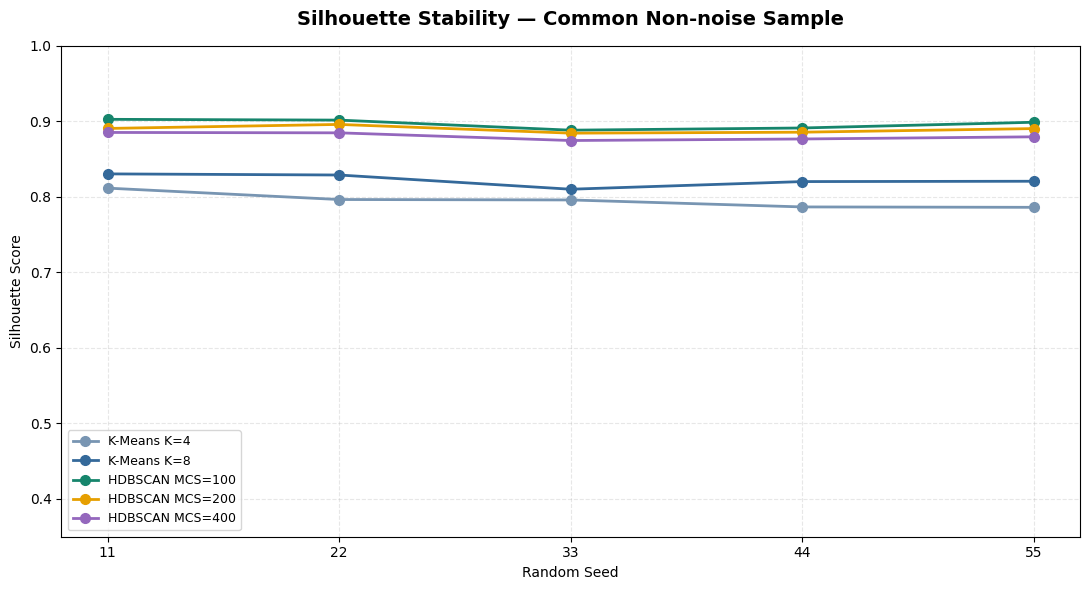

Đã lưu: /content/ml1_silhouette_stability_common.png


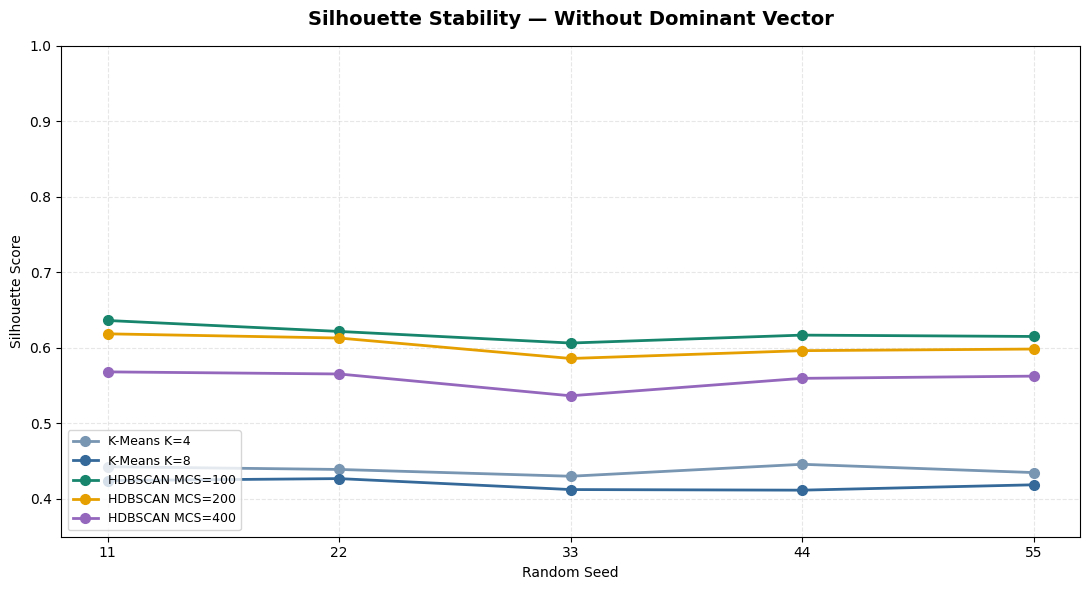

Đã lưu: /content/ml1_silhouette_stability_without_dominant.png

===== KIỂM TRA =====
Số lần lấy mẫu: 5
Số mô hình: 5
Số loại mẫu: 2
Tổng lượt đánh giá: 50

===== MÔ HÌNH DẪN ĐẦU TỪNG LẦN =====
     sample_type  seed          model  silhouette
 common_nonnoise    11 HDBSCAN_MCS100      0.9027
 common_nonnoise    22 HDBSCAN_MCS100      0.9017
 common_nonnoise    33 HDBSCAN_MCS100      0.8883
 common_nonnoise    44 HDBSCAN_MCS100      0.8912
 common_nonnoise    55 HDBSCAN_MCS100      0.8988
without_dominant    11 HDBSCAN_MCS100      0.6363
without_dominant    22 HDBSCAN_MCS100      0.6218
without_dominant    33 HDBSCAN_MCS100      0.6065
without_dominant    44 HDBSCAN_MCS100      0.6170
without_dominant    55 HDBSCAN_MCS100      0.6152

===== HOÀN THÀNH H2.4.5 =====


In [47]:

# H2.4.5 — SILHOUETTE STABILITY VISUALIZATION

import os
import pandas as pd
import matplotlib.pyplot as plt

print("===== H2.4.5 — SILHOUETTE STABILITY CHARTS =====")

# 1. Đọc kết quả H2.4.4
input_path = (
    "/content/ml1_clustering_silhouette_stability_detail.csv"
)

if not os.path.exists(input_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {input_path}"
    )

df = pd.read_csv(input_path)

required = [
    "seed", "sample_type", "model", "silhouette"
]

assert set(required).issubset(df.columns)
assert not df[required].isna().any().any()

# 2. Danh sách mô hình
models = [
    "KMeans_K4",
    "KMeans_K8",
    "HDBSCAN_MCS100",
    "HDBSCAN_MCS200",
    "HDBSCAN_MCS400"
]

display_names = {
    "KMeans_K4": "K-Means K=4",
    "KMeans_K8": "K-Means K=8",
    "HDBSCAN_MCS100": "HDBSCAN MCS=100",
    "HDBSCAN_MCS200": "HDBSCAN MCS=200",
    "HDBSCAN_MCS400": "HDBSCAN MCS=400"
}

colors = {
    "KMeans_K4": "#7895B2",
    "KMeans_K8": "#34699A",
    "HDBSCAN_MCS100": "#16856C",
    "HDBSCAN_MCS200": "#E69F00",
    "HDBSCAN_MCS400": "#9467BD"
}

# 3. Hàm vẽ một biểu đồ
def plot_silhouette_stability(
    data,
    sample_type,
    title,
    output_path
):
    subset = data[
        data["sample_type"] == sample_type
    ]

    fig, ax = plt.subplots(figsize=(11, 6))

    for model in models:
        model_data = (
            subset[subset["model"] == model]
            .sort_values("seed")
        )

        ax.plot(
            model_data["seed"],
            model_data["silhouette"],
            marker="o",
            markersize=7,
            linewidth=2,
            label=display_names[model],
            color=colors[model]
        )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Random Seed")
    ax.set_ylabel("Silhouette Score")
    ax.set_xticks(sorted(subset["seed"].unique()))
    ax.set_ylim(0.35, 1.0)

    ax.grid(
        linestyle="--",
        alpha=0.3
    )

    ax.legend(
        loc="lower left",
        fontsize=9
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Đã lưu:", output_path)

# BIỂU ĐỒ 1 — COMMON NON-NOISE SAMPLE


path1 = (
    "/content/ml1_silhouette_stability_common.png"
)

plot_silhouette_stability(
    df,
    "common_nonnoise",
    "Silhouette Stability — Common Non-noise Sample",
    path1
)

# BIỂU ĐỒ 2 — WITHOUT DOMINANT VECTOR


path2 = (
    "/content/ml1_silhouette_stability_without_dominant.png"
)

plot_silhouette_stability(
    df,
    "without_dominant",
    "Silhouette Stability — Without Dominant Vector",
    path2
)

# 4. Tổng hợp kiểm tra
print("\n===== KIỂM TRA =====")

print("Số lần lấy mẫu:", df["seed"].nunique())
print("Số mô hình:", df["model"].nunique())
print("Số loại mẫu:", df["sample_type"].nunique())
print("Tổng lượt đánh giá:", len(df))

# 5. Xác định mô hình đứng đầu theo từng lần lấy mẫu
winners = (
    df.loc[
        df.groupby(
            ["sample_type", "seed"]
        )["silhouette"].idxmax()
    ][
        ["sample_type", "seed", "model", "silhouette"]
    ]
    .sort_values(["sample_type", "seed"])
)

print("\n===== MÔ HÌNH DẪN ĐẦU TỪNG LẦN =====")
print(winners.round(4).to_string(index=False))

print("\n===== HOÀN THÀNH H2.4.5 =====")


In [48]:

# H2.5.1 — HDBSCAN MIN_SAMPLES SENSITIVITY
# MCS = 100, MIN_SAMPLES = 30

import os
import time
import numpy as np
import pandas as pd
import hdbscan

print("===== H2.5.1 — MIN_SAMPLES SENSITIVITY =====")

# 1. Đọc dữ liệu
data_path = "/content/ml1_hdbscan_sample_30000.npy"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Không tìm thấy: {data_path}"
    )

X = np.load(data_path)

assert X.shape == (30000, 15)
assert np.isfinite(X).all()

# 2. Cấu hình thử nghiệm
mcs = 100
min_samples = 30

model_hdbscan_ms30 = hdbscan.HDBSCAN(
    min_cluster_size=mcs,
    min_samples=min_samples,
    metric="euclidean",
    cluster_selection_method="eom",
    algorithm="best",
    approx_min_span_tree=True,
    core_dist_n_jobs=2,
    prediction_data=False
)

print("\n===== CẤU HÌNH =====")
print("min_cluster_size:", mcs)
print("min_samples:", min_samples)
print("metric: euclidean")

# 3. Huấn luyện
print("\nĐang huấn luyện HDBSCAN...")

start = time.perf_counter()

labels_ms30 = model_hdbscan_ms30.fit_predict(X)

elapsed = time.perf_counter() - start

# 4. Tính số cụm và nhiễu
n_clusters = len(set(labels_ms30) - {-1})
n_noise = int(np.sum(labels_ms30 == -1))
noise_pct = n_noise / len(X) * 100

# 5. Quy mô cụm
cluster_sizes = (
    pd.Series(labels_ms30, name="cluster")
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

cluster_sizes["percentage"] = (
    cluster_sizes["customer_count"]
    / len(X) * 100
)

cluster_sizes.index.name = "cluster"

print("\n===== KẾT QUẢ MIN_SAMPLES=30 =====")
print("Thời gian:", round(elapsed, 2), "giây")
print("Số cụm:", n_clusters)
print("Số khách hàng nhiễu:", n_noise)
print("Tỷ lệ nhiễu:", round(noise_pct, 3), "%")

print("\n===== QUY MÔ TỪNG CỤM =====")
print(cluster_sizes.round(3).to_string())

# 6. Đọc cấu hình ban đầu MS=15
initial_path = (
    "/content/ml1_hdbscan_initial_cluster_sizes.csv"
)

if not os.path.exists(initial_path):
    raise FileNotFoundError(
        "Không tìm thấy bảng HDBSCAN ban đầu."
    )

initial = pd.read_csv(initial_path)

initial_clusters = int(
    (initial["cluster"] != -1).sum()
)

initial_noise = int(
    initial.loc[
        initial["cluster"] == -1,
        "customer_count"
    ].sum()
)

# 7. So sánh hai cấu hình
comparison = pd.DataFrame([
    {
        "min_cluster_size": 100,
        "min_samples": 15,
        "n_clusters": initial_clusters,
        "noise_count": initial_noise,
        "noise_pct": initial_noise / len(X) * 100
    },
    {
        "min_cluster_size": 100,
        "min_samples": 30,
        "n_clusters": n_clusters,
        "noise_count": n_noise,
        "noise_pct": noise_pct
    }
])

print("\n===== SO SÁNH MIN_SAMPLES =====")
print(comparison.round(3).to_string(index=False))

# 8. Lưu nhãn
labels_df = pd.DataFrame({
    "sample_position": np.arange(len(X)),
    "hdbscan_cluster": labels_ms30,
    "membership_probability": (
        model_hdbscan_ms30.probabilities_
    )
})

labels_path = "/content/ml1_hdbscan_ms30_labels.csv"
sizes_path = "/content/ml1_hdbscan_ms30_cluster_sizes.csv"
compare_path = "/content/ml1_hdbscan_min_samples_comparison.csv"

labels_df.to_csv(labels_path, index=False)
cluster_sizes.to_csv(sizes_path)
comparison.to_csv(compare_path, index=False)

# 9. Kiểm tra
print("\n===== KIỂM TRA =====")
print(
    "Tổng khách hàng:",
    int(cluster_sizes["customer_count"].sum())
)
print(
    "Số nhãn thiếu:",
    int(labels_df.isna().sum().sum())
)

print("\n===== FILE ĐÃ LƯU =====")
print(labels_path)
print(sizes_path)
print(compare_path)

print("\n===== HOÀN THÀNH H2.5.1 =====")


===== H2.5.1 — MIN_SAMPLES SENSITIVITY =====

===== CẤU HÌNH =====
min_cluster_size: 100
min_samples: 30
metric: euclidean

Đang huấn luyện HDBSCAN...

===== KẾT QUẢ MIN_SAMPLES=30 =====
Thời gian: 13.2 giây
Số cụm: 20
Số khách hàng nhiễu: 1151
Tỷ lệ nhiễu: 3.837 %

===== QUY MÔ TỪNG CỤM =====
         customer_count  percentage
cluster                            
-1                 1151       3.837
 0                  209       0.697
 1                  129       0.430
 2                  208       0.693
 3                  338       1.127
 4                21204      70.680
 5                  191       0.637
 6                 1128       3.760
 7                  448       1.493
 8                 1628       5.427
 9                  248       0.827
 10                 121       0.403
 11                 315       1.050
 12                 217       0.723
 13                 185       0.617
 14                 158       0.527
 15                 522       1.740
 16                 3

In [49]:

# H2.5.2 — HDBSCAN MIN_SAMPLES CLUSTER STABILITY
# ARI: MIN_SAMPLES = 15 VS 30

import os
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

print("===== H2.5.2 — MIN_SAMPLES CLUSTER STABILITY =====")

# 1. Đọc dữ liệu và nhãn
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

files = {
    15: "/content/ml1_hdbscan_initial_labels.csv",
    30: "/content/ml1_hdbscan_ms30_labels.csv"
}

labels_dict = {}

for ms, path in files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy file: {path}"
        )

    df = pd.read_csv(path)

    df = df.sort_values(
        "sample_position"
    ).reset_index(drop=True)

    assert len(df) == len(X)

    assert np.array_equal(
        df["sample_position"].to_numpy(),
        np.arange(len(X))
    )

    labels_dict[ms] = (
        df["hdbscan_cluster"].to_numpy()
    )

assert X.shape == (30000, 15)

labels_15 = labels_dict[15]
labels_30 = labels_dict[30]

# 2. Xác định vector phổ biến nhất
_, inverse, counts = np.unique(
    X,
    axis=0,
    return_inverse=True,
    return_counts=True
)

dominant_mask = (
    inverse == np.argmax(counts)
)

non_dominant_mask = ~dominant_mask

print("\n===== THỐNG KÊ VECTOR =====")
print("Tổng khách hàng:", len(X))
print(
    "Vector phổ biến nhất:",
    int(dominant_mask.sum())
)
print(
    "Khách hàng còn lại:",
    int(non_dominant_mask.sum())
)

# 3. Tính ARI trên toàn bộ khách hàng
# Trong phép tính này, -1 được xem là một nhãn
ari_all = adjusted_rand_score(
    labels_15,
    labels_30
)

# 4. Tính ARI không gồm vector phổ biến nhất
ari_without_dominant = adjusted_rand_score(
    labels_15[non_dominant_mask],
    labels_30[non_dominant_mask]
)

# 5. Tính ARI chỉ trên các khách hàng
# không bị coi là nhiễu ở cả hai cấu hình
both_assigned = (
    (labels_15 != -1) &
    (labels_30 != -1)
)

ari_both_assigned = adjusted_rand_score(
    labels_15[both_assigned],
    labels_30[both_assigned]
)

# 6. Kết hợp: không nhiễu ở cả hai cấu hình
# và không gồm vector phổ biến nhất
both_assigned_other = (
    both_assigned & non_dominant_mask
)

ari_both_assigned_other = adjusted_rand_score(
    labels_15[both_assigned_other],
    labels_30[both_assigned_other]
)

print("\n===== ADJUSTED RAND INDEX =====")

print(
    "ARI toàn bộ dữ liệu:",
    round(ari_all, 6)
)

print(
    "ARI không gồm vector phổ biến nhất:",
    round(ari_without_dominant, 6)
)

print(
    "ARI trên các điểm không nhiễu chung:",
    round(ari_both_assigned, 6)
)

print(
    "ARI không nhiễu chung và bỏ vector phổ biến:",
    round(ari_both_assigned_other, 6)
)

# 7. Kiểm tra sự dịch chuyển của nhiễu
noise_15 = labels_15 == -1
noise_30 = labels_30 == -1

noise_transition = pd.DataFrame({
    "status": [
        "Noise in both models",
        "Noise only at MS=15",
        "Noise only at MS=30",
        "Assigned in both models"
    ],
    "customers": [
        int(np.sum(noise_15 & noise_30)),
        int(np.sum(noise_15 & ~noise_30)),
        int(np.sum(~noise_15 & noise_30)),
        int(np.sum(~noise_15 & ~noise_30))
    ]
})

print("\n===== NOISE TRANSITION =====")
print(noise_transition.to_string(index=False))

# 8. Tổng hợp đánh giá
ari_summary = pd.DataFrame([
    {
        "evaluation": "all_customers",
        "sample_size": len(X),
        "ARI": ari_all
    },
    {
        "evaluation": "without_dominant",
        "sample_size": int(non_dominant_mask.sum()),
        "ARI": ari_without_dominant
    },
    {
        "evaluation": "common_nonnoise",
        "sample_size": int(both_assigned.sum()),
        "ARI": ari_both_assigned
    },
    {
        "evaluation": "common_nonnoise_without_dominant",
        "sample_size": int(both_assigned_other.sum()),
        "ARI": ari_both_assigned_other
    }
])

print("\n===== ARI SUMMARY =====")
print(ari_summary.round(6).to_string(index=False))

# 9. Kiểm tra tổng
print("\n===== KIỂM TRA =====")
print(
    "Tổng khách hàng trong bảng chuyển đổi:",
    int(noise_transition["customers"].sum())
)

assert noise_transition["customers"].sum() == len(X)

# 10. Lưu kết quả
ari_path = "/content/ml1_hdbscan_ms15_ms30_ari.csv"
transition_path = (
    "/content/ml1_hdbscan_ms15_ms30_noise_transition.csv"
)

ari_summary.to_csv(ari_path, index=False)
noise_transition.to_csv(transition_path, index=False)

print("\n===== FILE ĐÃ LƯU =====")
print(ari_path)
print(transition_path)

print("\n===== HOÀN THÀNH H2.5.2 =====")


===== H2.5.2 — MIN_SAMPLES CLUSTER STABILITY =====

===== THỐNG KÊ VECTOR =====
Tổng khách hàng: 30000
Vector phổ biến nhất: 21204
Khách hàng còn lại: 8796

===== ADJUSTED RAND INDEX =====
ARI toàn bộ dữ liệu: 0.998256
ARI không gồm vector phổ biến nhất: 0.937708
ARI trên các điểm không nhiễu chung: 1.0
ARI không nhiễu chung và bỏ vector phổ biến: 1.0

===== NOISE TRANSITION =====
                 status  customers
   Noise in both models        844
    Noise only at MS=15          2
    Noise only at MS=30        307
Assigned in both models      28847

===== ARI SUMMARY =====
                      evaluation  sample_size      ARI
                   all_customers        30000 0.998256
                without_dominant         8796 0.937708
                 common_nonnoise        28847 1.000000
common_nonnoise_without_dominant         7643 1.000000

===== KIỂM TRA =====
Tổng khách hàng trong bảng chuyển đổi: 30000

===== FILE ĐÃ LƯU =====
/content/ml1_hdbscan_ms15_ms30_ari.csv
/content/m

In [50]:

# H2.5.3 — NOISE TRANSITION BEHAVIOR ANALYSIS

import os
import numpy as np
import pandas as pd

print("===== H2.5.3 — NOISE TRANSITION BEHAVIOR =====")

# 1. Đọc chỉ số mẫu và nhãn của hai cấu hình
indices_path = "/content/ml1_sample_indices_30000.npy"

if not os.path.exists(indices_path):
    raise FileNotFoundError("Không tìm thấy sample_indices.")

indices = np.load(indices_path)

def load_hdbscan_labels(path):
    df = pd.read_csv(path)
    df = df.sort_values(
        "sample_position"
    ).reset_index(drop=True)

    assert len(df) == 30000
    assert np.array_equal(
        df["sample_position"].to_numpy(),
        np.arange(30000)
    )

    return df["hdbscan_cluster"].to_numpy()

labels_15 = load_hdbscan_labels(
    "/content/ml1_hdbscan_initial_labels.csv"
)

labels_30 = load_hdbscan_labels(
    "/content/ml1_hdbscan_ms30_labels.csv"
)

assert len(indices) == 30000

# 2. Khôi phục mã khách hàng đúng thứ tự mẫu
if "ml1_data" not in globals():
    raise NameError(
        "Không tìm thấy ml1_data trong RAM."
    )

if "customer_features" not in globals():
    raise NameError(
        "Không tìm thấy customer_features trong RAM."
    )

sample_ids = (
    ml1_data.iloc[indices]["visitorid"].to_numpy()
)

assert len(np.unique(sample_ids)) == 30000

# 3. Đọc hành vi gốc
behavior_cols = [
    "total_events",
    "total_sessions",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items",
    "unique_transactions"
]

behavior = (
    customer_features
    .set_index("visitorid")
    .loc[sample_ids, behavior_cols]
    .copy()
    .reset_index()
)

assert np.array_equal(
    behavior["visitorid"].to_numpy(),
    sample_ids
)

# 4. Xác định trạng thái nhiễu
noise_15 = labels_15 == -1
noise_30 = labels_30 == -1

conditions = [
    noise_15 & noise_30,
    noise_15 & ~noise_30,
    ~noise_15 & noise_30,
    ~noise_15 & ~noise_30
]

choices = [
    "Noise in both",
    "Noise only MS15",
    "Noise only MS30",
    "Assigned in both"
]

behavior["noise_status"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

behavior["has_cart"] = (
    behavior["total_addtocart"] > 0
).astype(int)

behavior["has_purchase"] = (
    behavior["total_transaction_events"] > 0
).astype(int)

# 5. Tổng hợp hành vi theo trạng thái
summary = (
    behavior
    .groupby("noise_status")
    .agg(
        customers=("visitorid", "size"),
        mean_events=("total_events", "mean"),
        median_events=("total_events", "median"),
        mean_sessions=("total_sessions", "mean"),
        mean_views=("total_views", "mean"),
        mean_cart=("total_addtocart", "mean"),
        mean_transactions=(
            "total_transaction_events", "mean"
        ),
        mean_unique_items=("unique_items", "mean"),
        cart_customers=("has_cart", "sum"),
        purchasing_customers=("has_purchase", "sum"),
        pct_with_cart=("has_cart", "mean"),
        pct_with_purchase=("has_purchase", "mean")
    )
)

summary["pct_with_cart"] *= 100
summary["pct_with_purchase"] *= 100

# 6. Hiển thị kết quả
print("\n===== NOISE TRANSITION BEHAVIOR PROFILE =====")
print(summary.round(3).to_string())

print("\n===== KIỂM TRA =====")
print("Tổng khách hàng:", int(summary["customers"].sum()))
print(
    "Số khách hàng chỉ nhiễu ở MS=30:",
    int(summary.loc["Noise only MS30", "customers"])
)
print(
    "Số khách hàng chỉ nhiễu ở MS=15:",
    int(summary.loc["Noise only MS15", "customers"])
)

assert summary["customers"].sum() == 30000
assert summary.loc["Noise only MS30", "customers"] == 307
assert summary.loc["Noise only MS15", "customers"] == 2

# 7. Lưu kết quả
summary_path = (
    "/content/ml1_hdbscan_noise_transition_behavior_summary.csv"
)

detail_path = (
    "/content/ml1_hdbscan_noise_transition_behavior_detail.csv"
)

summary.to_csv(summary_path)
behavior.to_csv(detail_path, index=False)

print("\n===== FILE ĐÃ LƯU =====")
print(summary_path)
print(detail_path)

print("\n===== HOÀN THÀNH H2.5.3 =====")


===== H2.5.3 — NOISE TRANSITION BEHAVIOR =====

===== NOISE TRANSITION BEHAVIOR PROFILE =====
                  customers  mean_events  median_events  mean_sessions  mean_views  mean_cart  mean_transactions  mean_unique_items  cart_customers  purchasing_customers  pct_with_cart  pct_with_purchase
noise_status                                                                                                                                                                                               
Assigned in both      28847        1.513            1.0          1.133       1.484      0.021              0.009              1.288             522                   209          1.810              0.725
Noise in both           844       18.095            9.0          4.724      16.897      0.909              0.289             10.350             224                    11         26.540              1.303
Noise only MS15           2        4.000            4.0          1.500       2.500      1.

In [51]:

# H2.6.1 — BUSINESS-ORIENTED CLUSTERING EVALUATION
# K-MEANS K=4 VS HDBSCAN MCS=100, MS=15


import os
import numpy as np
import pandas as pd

print("===== H2.6.1 — CLUSTERING BUSINESS EVALUATION =====")

# 1. Kiểm tra dữ liệu và mô hình
required_files = [
    "/content/ml1_hdbscan_sample_30000.npy",
    "/content/ml1_sample_indices_30000.npy",
    "/content/ml1_hdbscan_initial_labels.csv"
]

for path in required_files:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không tìm thấy: {path}")

if "comparison_models" not in globals() or 4 not in comparison_models:
    raise NameError("Không tìm thấy mô hình K-Means K=4.")

if "ml1_data" not in globals():
    raise NameError("Không tìm thấy ml1_data.")

if "customer_features" not in globals():
    raise NameError("Không tìm thấy customer_features.")

# 2. Khôi phục mẫu
X = np.load(required_files[0])
indices = np.load(required_files[1])

assert X.shape == (30000, 15)
assert len(indices) == 30000

sample_ids = ml1_data.iloc[indices]["visitorid"].to_numpy()

assert len(np.unique(sample_ids)) == 30000

# Kiểm tra lại thứ tự đặc trưng
feature_cols = [
    c for c in ml1_data.columns if c != "visitorid"
]

assert np.allclose(
    ml1_data.iloc[indices][feature_cols].to_numpy(),
    X,
    rtol=1e-5,
    atol=1e-7
), "Đặc trưng chuẩn hóa không khớp mẫu."

# 3. Đọc nhãn K-Means và HDBSCAN
kmeans_labels = comparison_models[4].predict(X)

hdbscan_df = pd.read_csv(
    "/content/ml1_hdbscan_initial_labels.csv"
).sort_values("sample_position").reset_index(drop=True)

assert np.array_equal(
    hdbscan_df["sample_position"].to_numpy(),
    np.arange(30000)
)

hdbscan_labels = hdbscan_df["hdbscan_cluster"].to_numpy()

# 4. Ghép dữ liệu hành vi gốc
behavior_cols = [
    "total_events",
    "total_views",
    "total_addtocart",
    "total_transaction_events",
    "unique_items"
]

sample_behavior = (
    customer_features
    .set_index("visitorid")
    .loc[sample_ids, behavior_cols]
    .copy()
    .reset_index()
)

assert np.array_equal(
    sample_behavior["visitorid"].to_numpy(),
    sample_ids
)

sample_behavior["has_cart"] = (
    sample_behavior["total_addtocart"] > 0
).astype(int)

sample_behavior["has_purchase"] = (
    sample_behavior["total_transaction_events"] > 0
).astype(int)

print("\n===== KIỂM TRA MẪU =====")
print("Số khách hàng:", len(sample_behavior))
print("Khách hàng từng thêm giỏ:", sample_behavior["has_cart"].sum())
print("Khách hàng từng mua:", sample_behavior["has_purchase"].sum())

# 5. Hàm đánh giá mô hình
def evaluate_business_metrics(name, labels):

    data = sample_behavior.copy()
    data["cluster"] = labels

    assigned = data[data["cluster"] != -1]

    n_clusters = data.loc[
        data["cluster"] != -1, "cluster"
    ].nunique()

    cluster_sizes = (
        assigned.groupby("cluster").size()
    )

    buyers_by_cluster = (
        assigned.groupby("cluster")["has_purchase"].sum()
    )

    total_buyers = int(data["has_purchase"].sum())
    assigned_buyers = int(assigned["has_purchase"].sum())

    total_cart_users = int(data["has_cart"].sum())
    assigned_cart_users = int(assigned["has_cart"].sum())

    return {
        "model": name,
        "n_clusters": int(n_clusters),
        "assigned_customers": len(assigned),
        "coverage_pct": len(assigned) / len(data) * 100,
        "noise_pct": (len(data) - len(assigned)) / len(data) * 100,
        "largest_cluster_pct": (
            cluster_sizes.max() / len(data) * 100
        ),
        "clusters_below_1pct": int(
            (cluster_sizes / len(data) * 100 < 1).sum()
        ),
        "buyers_assigned": assigned_buyers,
        "buyer_coverage_pct": (
            assigned_buyers / total_buyers * 100
            if total_buyers else np.nan
        ),
        "cart_user_coverage_pct": (
            assigned_cart_users / total_cart_users * 100
            if total_cart_users else np.nan
        ),
        "buyers_in_top_buyer_cluster": int(
            buyers_by_cluster.max()
        ),
        "top_buyer_cluster_share_pct": (
            buyers_by_cluster.max() / total_buyers * 100
            if total_buyers else np.nan
        )
    }

# 6. Tạo bảng so sánh
results = [
    evaluate_business_metrics(
        "KMeans_K4",
        kmeans_labels
    ),
    evaluate_business_metrics(
        "HDBSCAN_MCS100_MS15",
        hdbscan_labels
    )
]

evaluation = pd.DataFrame(results)

print("\n===== BUSINESS EVALUATION COMPARISON =====")
print(evaluation.round(3).to_string(index=False))

# 7. Kiểm tra tổng
assert len(kmeans_labels) == 30000
assert len(hdbscan_labels) == 30000
assert evaluation["assigned_customers"].between(0, 30000).all()

# 8. Lưu bảng
output_path = (
    "/content/ml1_kmeans_vs_hdbscan_business_evaluation.csv"
)

evaluation.to_csv(output_path, index=False)

print("\nĐã lưu tại:", output_path)
print("===== HOÀN THÀNH H2.6.1 =====")


===== H2.6.1 — CLUSTERING BUSINESS EVALUATION =====

===== KIỂM TRA MẪU =====
Số khách hàng: 30000
Khách hàng từng thêm giỏ: 781
Khách hàng từng mua: 222

===== BUSINESS EVALUATION COMPARISON =====
              model  n_clusters  assigned_customers  coverage_pct  noise_pct  largest_cluster_pct  clusters_below_1pct  buyers_assigned  buyer_coverage_pct  cart_user_coverage_pct  buyers_in_top_buyer_cluster  top_buyer_cluster_share_pct
          KMeans_K4           4               30000        100.00       0.00               85.877                    1              222             100.000                 100.000                          222                      100.000
HDBSCAN_MCS100_MS15          20               29154         97.18       2.82               70.680                   10              211              95.045                  71.063                          211                       95.045

Đã lưu tại: /content/ml1_kmeans_vs_hdbscan_business_evaluation.csv
===== HOÀN THÀNH H2.

===== H2.6.2 — CLUSTER MAPPING =====

===== CLUSTER MAPPING — CUSTOMER COUNT =====
hdbscan_cluster  -1    0    1    2    3      4     5    6    7     8    9    10   11   12   13   14   15   16   17   18   19
kmeans_cluster                                                                                                              
0                 11    0    0    0  337  21204  1128  193  448  1628  315    0  232    0    0    0  267    0    0    0    0
1                646    0    0   14    3      0     0    0    4     0    0  225   32  135  173  190  288  410  398  167  800
2                 11  211    0    0    0      0     0    0    0     0    0    0    0    0    0    0    0    0    0    0    0
3                178    0  128  224    0      0     0    0    0     0    0    0    0    0    0    0    0    0    0    0    0

===== CLUSTER MAPPING — ROW PERCENTAGE =====
hdbscan_cluster    -1      0      1      2     3     4     5     6     7     8     9     10    11    12    13    14    15

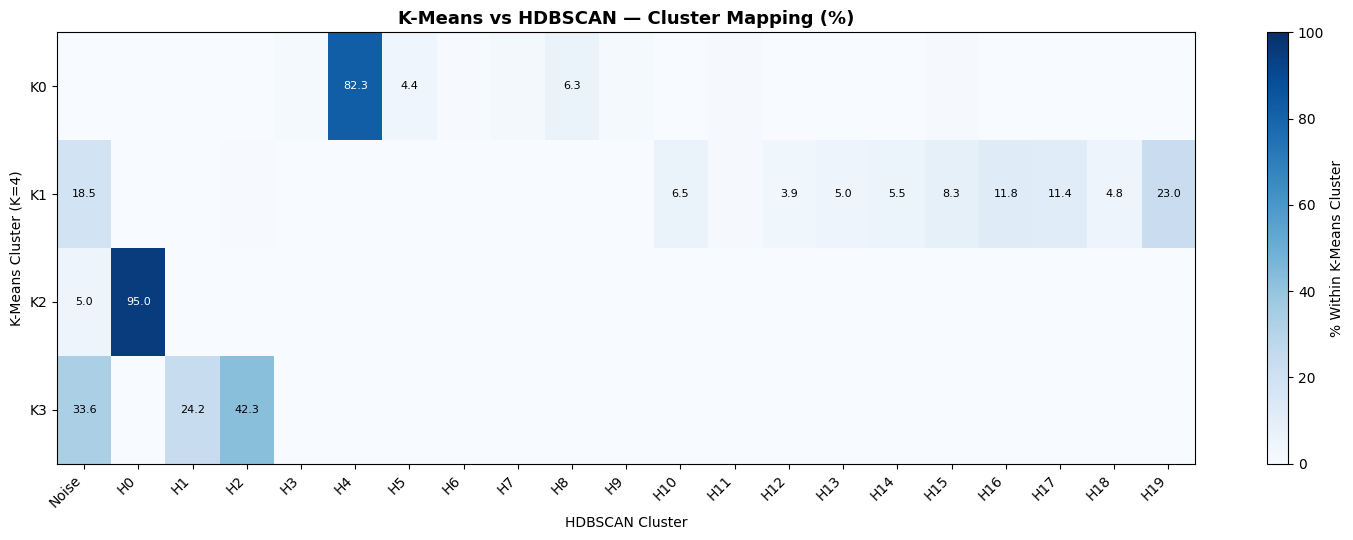


===== KIỂM TRA =====
Tổng khách hàng: 30000
Tổng từng dòng K-Means: {0: 25763, 1: 3485, 2: 222, 3: 530}
Tổng tỷ lệ từng dòng (%): {0: 100.0, 1: 100.0, 2: 100.0, 3: 100.0}

===== FILE ĐÃ LƯU =====
/content/ml1_kmeans_hdbscan_mapping_count.csv
/content/ml1_kmeans_hdbscan_mapping_pct.csv
/content/ml1_kmeans_hdbscan_top_mapping.csv
/content/ml1_kmeans_hdbscan_mapping_heatmap.png

===== HOÀN THÀNH H2.6.2 =====


In [52]:

# H2.6.2 — K-MEANS VS HDBSCAN CLUSTER MAPPING

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("===== H2.6.2 — CLUSTER MAPPING =====")

# 1. Đọc dữ liệu chung
X = np.load(
    "/content/ml1_hdbscan_sample_30000.npy"
)

assert X.shape == (30000, 15)
assert np.isfinite(X).all()

# 2. Lấy nhãn K-Means K=4
if "comparison_models" not in globals():
    raise NameError("Không tìm thấy comparison_models.")

if 4 not in comparison_models:
    raise KeyError("Không tìm thấy mô hình K=4.")

kmeans_labels = comparison_models[4].predict(X)

# 3. Đọc nhãn HDBSCAN
path = "/content/ml1_hdbscan_initial_labels.csv"

if not os.path.exists(path):
    raise FileNotFoundError(path)

hdbscan_df = pd.read_csv(path)

hdbscan_df = hdbscan_df.sort_values(
    "sample_position"
).reset_index(drop=True)

assert len(hdbscan_df) == len(X)

assert np.array_equal(
    hdbscan_df["sample_position"].to_numpy(),
    np.arange(len(X))
)

hdbscan_labels = (
    hdbscan_df["hdbscan_cluster"].to_numpy()
)

# 4. Tạo bảng đối chiếu
mapping_df = pd.DataFrame({
    "kmeans_cluster": kmeans_labels,
    "hdbscan_cluster": hdbscan_labels
})

# 5. Bảng số lượng khách hàng
mapping_count = pd.crosstab(
    mapping_df["kmeans_cluster"],
    mapping_df["hdbscan_cluster"]
)

# 6. Bảng tỷ lệ theo từng cụm K-Means
mapping_pct = (
    mapping_count
    .div(mapping_count.sum(axis=1), axis=0)
    * 100
)

print("\n===== CLUSTER MAPPING — CUSTOMER COUNT =====")
print(mapping_count.to_string())

print("\n===== CLUSTER MAPPING — ROW PERCENTAGE =====")
print(mapping_pct.round(2).to_string())

# 7. Tìm 3 cụm HDBSCAN chiếm tỷ trọng lớn nhất
# bên trong từng cụm K-Means
print("\n===== TOP HDBSCAN CLUSTERS PER K-MEANS CLUSTER =====")

top_results = []

for k_cluster in mapping_count.index:

    row = mapping_count.loc[k_cluster]

    top_clusters = row.sort_values(
        ascending=False
    ).head(3)

    for h_cluster, count in top_clusters.items():

        if count == 0:
            continue

        top_results.append({
            "kmeans_cluster": int(k_cluster),
            "hdbscan_cluster": int(h_cluster),
            "customers": int(count),
            "pct_within_kmeans": (
                count / row.sum() * 100
            )
        })

top_df = pd.DataFrame(top_results)

print(top_df.round(3).to_string(index=False))

# 8. Vẽ Heatmap
fig, ax = plt.subplots(figsize=(15, 5.5))

im = ax.imshow(
    mapping_pct.to_numpy(),
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(
    np.arange(len(mapping_pct.columns))
)

ax.set_xticklabels(
    [
        "Noise" if c == -1 else f"H{c}"
        for c in mapping_pct.columns
    ],
    rotation=45,
    ha="right"
)

ax.set_yticks(
    np.arange(len(mapping_pct.index))
)

ax.set_yticklabels(
    [f"K{c}" for c in mapping_pct.index]
)

ax.set_xlabel("HDBSCAN Cluster")
ax.set_ylabel("K-Means Cluster (K=4)")

ax.set_title(
    "K-Means vs HDBSCAN — Cluster Mapping (%)",
    fontsize=13,
    fontweight="bold"
)

# Hiển thị phần trăm ở những ô đủ lớn
for i in range(mapping_pct.shape[0]):
    for j in range(mapping_pct.shape[1]):

        value = mapping_pct.iloc[i, j]

        if value >= 2:
            ax.text(
                j,
                i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value >= 50 else "black"
            )

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("% Within K-Means Cluster")

plt.tight_layout()

# 9. Lưu kết quả
count_path = (
    "/content/ml1_kmeans_hdbscan_mapping_count.csv"
)

pct_path = (
    "/content/ml1_kmeans_hdbscan_mapping_pct.csv"
)

top_path = (
    "/content/ml1_kmeans_hdbscan_top_mapping.csv"
)

chart_path = (
    "/content/ml1_kmeans_hdbscan_mapping_heatmap.png"
)

mapping_count.to_csv(count_path)
mapping_pct.to_csv(pct_path)
top_df.to_csv(top_path, index=False)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Kiểm tra
print("\n===== KIỂM TRA =====")

print(
    "Tổng khách hàng:",
    int(mapping_count.to_numpy().sum())
)

print(
    "Tổng từng dòng K-Means:",
    mapping_count.sum(axis=1).to_dict()
)

print(
    "Tổng tỷ lệ từng dòng (%):",
    mapping_pct.sum(axis=1).round(3).to_dict()
)

print("\n===== FILE ĐÃ LƯU =====")
print(count_path)
print(pct_path)
print(top_path)
print(chart_path)

print("\n===== HOÀN THÀNH H2.6.2 =====")


In [53]:

# CP1.1 — CUSTOMER PERSONAS SUMMARY (FULL DATA)

import os
import numpy as np
import pandas as pd

print("===== CP1.1 — CUSTOMER PERSONAS =====")

# 1. Đọc kết quả MiniBatchKMeans trên toàn bộ dữ liệu
profile_path = (
    "/content/ml1_kmeans_k4_full_behavior_profile.csv"
)

purchase_path = (
    "/content/ml1_kmeans_k4_purchase_distribution.csv"
)

for path in [profile_path, purchase_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không tìm thấy: {path}")

profile = pd.read_csv(profile_path)
purchase = pd.read_csv(purchase_path)

# 2. Kiểm tra các cột
assert "cluster" in profile.columns
assert "cluster" in purchase.columns

assert profile["cluster"].is_unique
assert purchase["cluster"].is_unique

assert set(profile["cluster"]) == {0, 1, 2, 3}
assert set(purchase["cluster"]) == {0, 1, 2, 3}

# 3. Đặt tên phân khúc dựa trên hành vi đã phân tích
persona_names = {
    0: "Light Browsers",
    1: "One-time Viewers",
    2: "Active Browsers",
    3: "High-intent Shoppers"
}

persona_vn = {
    0: "Khách hàng xem ít",
    1: "Khách hàng xem một lần",
    2: "Khách hàng khám phá tích cực",
    3: "Khách hàng tương tác mua sắm cao"
}

# 4. Ghép hồ sơ hành vi và giao dịch
personas = profile.merge(
    purchase[
        [
            "cluster",
            "cluster_share_pct",
            "purchasing_customers",
            "cart_customers",
            "share_of_all_buyers_pct"
        ]
    ],
    on="cluster",
    how="inner",
    validate="one_to_one"
)

personas["persona_name"] = (
    personas["cluster"].map(persona_names)
)

personas["persona_vn"] = (
    personas["cluster"].map(persona_vn)
)

# 5. Tạo bảng tổng hợp
display_columns = [
    "cluster",
    "persona_name",
    "persona_vn",
    "customer_count",
    "cluster_share_pct",
    "mean_events",
    "mean_sessions",
    "mean_views",
    "mean_cart",
    "mean_unique_items",
    "pct_customers_with_cart",
    "pct_customers_with_transaction",
    "purchasing_customers",
    "share_of_all_buyers_pct"
]

personas = personas[display_columns]

personas = personas.sort_values(
    "cluster"
).reset_index(drop=True)

# 6. Hiển thị kết quả
print("\n===== CUSTOMER PERSONAS — FULL DATA =====")
print(personas.round(3).to_string(index=False))

# 7. Kiểm tra
print("\n===== KIỂM TRA =====")
print("Số phân khúc:", len(personas))

print(
    "Tổng khách hàng:",
    int(personas["customer_count"].sum())
)

print(
    "Tổng khách hàng từng mua:",
    int(personas["purchasing_customers"].sum())
)

print(
    "Tổng tỷ lệ khách hàng:",
    round(personas["cluster_share_pct"].sum(), 3),
    "%"
)

assert len(personas) == 4
assert personas["customer_count"].sum() == 1407579
assert personas["purchasing_customers"].sum() == 11718
assert np.isclose(personas["cluster_share_pct"].sum(), 100)

# 8. Lưu kết quả
output_path = (
    "/content/ml1_customer_personas_full_data.csv"
)

personas.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu tại:", output_path)
print("===== HOÀN THÀNH CP1.1 =====")


===== CP1.1 — CUSTOMER PERSONAS =====

===== CUSTOMER PERSONAS — FULL DATA =====
 cluster         persona_name                       persona_vn  customer_count  cluster_share_pct  mean_events  mean_sessions  mean_views  mean_cart  mean_unique_items  pct_customers_with_cart  pct_customers_with_transaction  purchasing_customers  share_of_all_buyers_pct
       0       Light Browsers                Khách hàng xem ít          240270             17.070        2.496          1.213       2.494      0.002              1.783                    0.162                           0.000                     0                    0.000
       1     One-time Viewers           Khách hàng xem một lần          998984             70.972        1.000          1.000       1.000      0.000              1.000                    0.000                           0.000                     0                    0.000
       2      Active Browsers     Khách hàng khám phá tích cực          135234              9.608      

===== CP1.2 — CUSTOMER PERSONAS HEATMAP =====


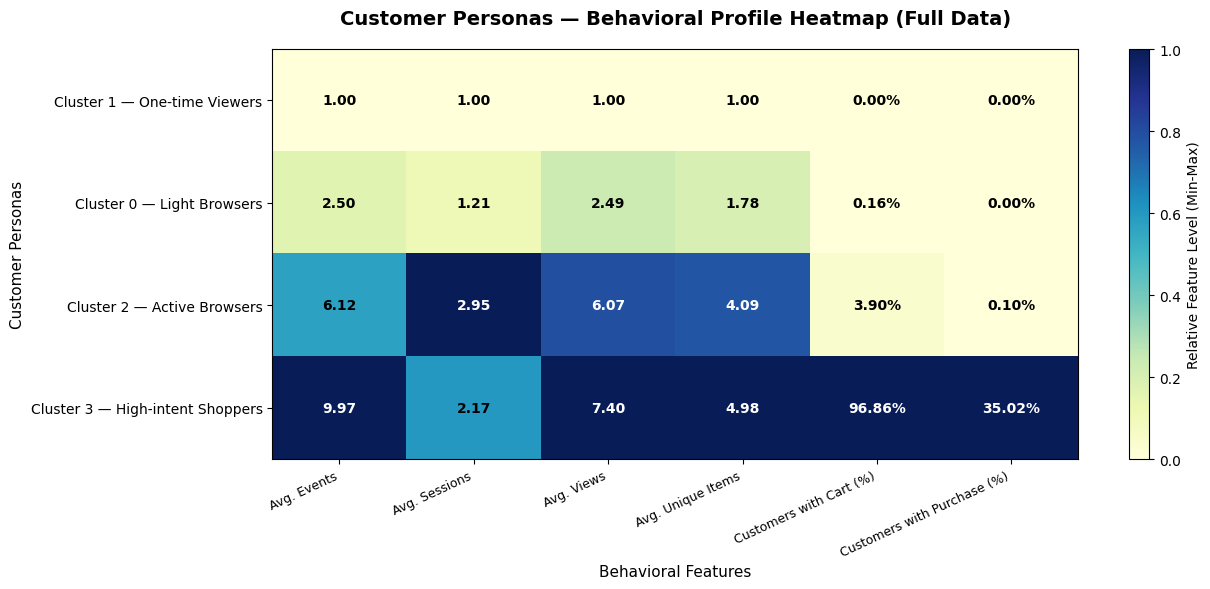


===== KIỂM TRA =====
Số phân khúc: 4
Số chỉ số hành vi: 6

===== BEHAVIORAL PROFILE =====
 cluster         persona_name  mean_events  mean_sessions  mean_views  mean_unique_items  pct_customers_with_cart  pct_customers_with_transaction
       1     One-time Viewers        1.000          1.000       1.000              1.000                    0.000                           0.000
       0       Light Browsers        2.496          1.213       2.494              1.783                    0.162                           0.000
       2      Active Browsers        6.115          2.954       6.071              4.090                    3.904                           0.096
       3 High-intent Shoppers        9.971          2.170       7.401              4.980                   96.863                          35.019

Đã lưu Heatmap tại: /content/ml1_customer_personas_behavior_heatmap.png
===== HOÀN THÀNH CP1.2 =====


In [54]:

# CP1.2 — CUSTOMER PERSONAS BEHAVIORAL HEATMAP
# FULL DATA — 1,407,579 CUSTOMERS

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("===== CP1.2 — CUSTOMER PERSONAS HEATMAP =====")

# 1. Đọc kết quả CP1.1
input_path = "/content/ml1_customer_personas_full_data.csv"

if not os.path.exists(input_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {input_path}"
    )

df = pd.read_csv(input_path)

# 2. Kiểm tra dữ liệu
features = {
    "mean_events": "Avg. Events",
    "mean_sessions": "Avg. Sessions",
    "mean_views": "Avg. Views",
    "mean_unique_items": "Avg. Unique Items",
    "pct_customers_with_cart": "Customers with Cart (%)",
    "pct_customers_with_transaction": "Customers with Purchase (%)"
}

required = ["cluster", "persona_name"] + list(features.keys())

assert set(required).issubset(df.columns)
assert len(df) == 4
assert not df[required].isna().any().any()

# 3. Sắp xếp theo mức độ hoạt động để dễ diễn giải
cluster_order = [1, 0, 2, 3]

df = (
    df.set_index("cluster")
    .loc[cluster_order]
    .reset_index()
)

# 4. Lấy giá trị thực tế
values = df[list(features.keys())].to_numpy(dtype=float)

# Chuẩn hóa Min-Max theo từng chỉ số
# Chỉ dùng để thể hiện màu sắc trên Heatmap
min_values = values.min(axis=0)
max_values = values.max(axis=0)

ranges = max_values - min_values

normalized = np.divide(
    values - min_values,
    ranges,
    out=np.zeros_like(values),
    where=ranges != 0
)

# 5. Vẽ Heatmap
fig, ax = plt.subplots(figsize=(13, 6))

im = ax.imshow(
    normalized,
    cmap="YlGnBu",
    aspect="auto",
    vmin=0,
    vmax=1
)

# 6. Đặt nhãn
row_labels = [
    f"Cluster {row.cluster} — {row.persona_name}"
    for row in df.itertuples()
]

ax.set_yticks(np.arange(len(df)))
ax.set_yticklabels(row_labels, fontsize=10)

ax.set_xticks(np.arange(len(features)))
ax.set_xticklabels(
    list(features.values()),
    rotation=25,
    ha="right",
    fontsize=9
)

# 7. Ghi giá trị gốc vào mỗi ô
for i in range(values.shape[0]):
    for j in range(values.shape[1]):

        value = values[i, j]

        label = (
            f"{value:.2f}%"
            if j >= 4
            else f"{value:.2f}"
        )

        ax.text(
            j, i,
            label,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color=(
                "white"
                if normalized[i, j] >= 0.65
                else "black"
            )
        )

# 8. Định dạng
ax.set_title(
    "Customer Personas — Behavioral Profile Heatmap (Full Data)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Behavioral Features", fontsize=11)
ax.set_ylabel("Customer Personas", fontsize=11)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Relative Feature Level (Min-Max)")

plt.tight_layout()

# 9. Lưu ảnh
output_path = (
    "/content/ml1_customer_personas_behavior_heatmap.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Kiểm tra và hiển thị bảng
print("\n===== KIỂM TRA =====")
print("Số phân khúc:", len(df))
print("Số chỉ số hành vi:", len(features))

print("\n===== BEHAVIORAL PROFILE =====")
print(
    df[["cluster", "persona_name"] + list(features.keys())]
    .round(3)
    .to_string(index=False)
)

print("\nĐã lưu Heatmap tại:", output_path)
print("===== HOÀN THÀNH CP1.2 =====")


In [55]:

# CP1.3 — CUSTOMER PERSONAS INTERPRETATION
# FULL DATA — 1,407,579 CUSTOMERS

import os
import numpy as np
import pandas as pd

print("===== CP1.3 — CUSTOMER PERSONAS INTERPRETATION =====")

# 1. Đọc kết quả CP1.1
input_path = "/content/ml1_customer_personas_full_data.csv"

if not os.path.exists(input_path):
    raise FileNotFoundError(
        f"Không tìm thấy: {input_path}"
    )

df = pd.read_csv(input_path)

assert set(df["cluster"]) == {0, 1, 2, 3}
assert df["cluster"].is_unique
assert df["customer_count"].sum() == 1407579
assert df["purchasing_customers"].sum() == 11718

# 2. Mô tả từng Customer Persona
# Các nhận định dựa trên kết quả phân cụm đã quan sát
persona_descriptions = {

    0: {
        "behavior_description":
            "Tương tác ở mức thấp, chủ yếu xem sản phẩm; "
            "rất ít thêm giỏ và chưa ghi nhận giao dịch.",

        "engagement_level":
            "Thấp",

        "recommendation_direction":
            "Thử nghiệm gợi ý sản phẩm tương tự "
            "hoặc sản phẩm liên quan đến lịch sử xem."
    },

    1: {
        "behavior_description":
            "Chỉ có một lượt xem sản phẩm trong một phiên; "
            "không ghi nhận thêm giỏ hoặc giao dịch.",

        "engagement_level":
            "Rất thấp",

        "recommendation_direction":
            "Thử nghiệm Popularity-based Recommendation "
            "hoặc phương pháp xử lý cold-start."
    },

    2: {
        "behavior_description":
            "Tương tác qua nhiều phiên, khám phá nhiều "
            "sản phẩm; hành vi thêm giỏ và mua còn ít.",

        "engagement_level":
            "Trung bình đến cao",

        "recommendation_direction":
            "Thử nghiệm gợi ý dựa trên lịch sử xem "
            "và chuỗi tương tác sản phẩm."
    },

    3: {
        "behavior_description":
            "Tương tác nhiều; phần lớn khách hàng từng "
            "thêm giỏ và một bộ phận đã phát sinh giao dịch.",

        "engagement_level":
            "Cao",

        "recommendation_direction":
            "Thử nghiệm gợi ý đa hành vi kết hợp "
            "view, addtocart và transaction."
    }
}

# 3. Tạo các cột diễn giải
df["behavior_description"] = df["cluster"].map(
    lambda c: persona_descriptions[c][
        "behavior_description"
    ]
)

df["engagement_level"] = df["cluster"].map(
    lambda c: persona_descriptions[c][
        "engagement_level"
    ]
)

df["recommendation_direction"] = df["cluster"].map(
    lambda c: persona_descriptions[c][
        "recommendation_direction"
    ]
)

# 4. Sắp xếp theo hành trình tương tác
cluster_order = [1, 0, 2, 3]

df = (
    df.set_index("cluster")
    .loc[cluster_order]
    .reset_index()
)

# 5. Chọn các cột của bảng Personas
columns = [
    "cluster",
    "persona_name",
    "persona_vn",
    "customer_count",
    "cluster_share_pct",
    "mean_events",
    "mean_sessions",
    "mean_views",
    "mean_unique_items",
    "pct_customers_with_cart",
    "pct_customers_with_transaction",
    "purchasing_customers",
    "engagement_level",
    "behavior_description",
    "recommendation_direction"
]

personas_final = df[columns].copy()

# 6. In hồ sơ từng phân khúc
print("\n===== FOUR CUSTOMER PERSONAS =====")

for _, row in personas_final.iterrows():

    print("\n" + "=" * 65)

    print(
        f"CLUSTER {int(row['cluster'])} — "
        f"{row['persona_name']}"
    )

    print("Tên tiếng Việt:", row["persona_vn"])

    print(
        "Số khách hàng:",
        f"{int(row['customer_count']):,}"
    )

    print(
        "Tỷ lệ:",
        f"{row['cluster_share_pct']:.2f}%"
    )

    print(
        "Lượt tương tác TB:",
        f"{row['mean_events']:.3f}"
    )

    print(
        "Phiên hoạt động TB:",
        f"{row['mean_sessions']:.3f}"
    )

    print(
        "Tỷ lệ từng thêm giỏ:",
        f"{row['pct_customers_with_cart']:.3f}%"
    )

    print(
        "Tỷ lệ từng mua:",
        f"{row['pct_customers_with_transaction']:.3f}%"
    )

    print(
        "Mức độ tương tác:",
        row["engagement_level"]
    )

    print(
        "Đặc điểm hành vi:",
        row["behavior_description"]
    )

    print(
        "Định hướng gợi ý:",
        row["recommendation_direction"]
    )

# 7. Kiểm tra
print("\n===== KIỂM TRA =====")
print("Số Personas:", len(personas_final))

print(
    "Tổng khách hàng:",
    int(personas_final["customer_count"].sum())
)

print(
    "Tổng khách hàng từng mua:",
    int(personas_final["purchasing_customers"].sum())
)

print(
    "Tổng tỷ lệ:",
    round(
        personas_final["cluster_share_pct"].sum(), 3
    ), "%"
)

assert len(personas_final) == 4
assert personas_final["customer_count"].sum() == 1407579
assert personas_final["purchasing_customers"].sum() == 11718

# 8. Lưu kết quả
output_path = (
    "/content/ml1_customer_personas_interpretation.csv"
)

personas_final.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n===== FILE ĐÃ LƯU =====")
print(output_path)

print("\n===== HOÀN THÀNH CP1.3 =====")


===== CP1.3 — CUSTOMER PERSONAS INTERPRETATION =====

===== FOUR CUSTOMER PERSONAS =====

CLUSTER 1 — One-time Viewers
Tên tiếng Việt: Khách hàng xem một lần
Số khách hàng: 998,984
Tỷ lệ: 70.97%
Lượt tương tác TB: 1.000
Phiên hoạt động TB: 1.000
Tỷ lệ từng thêm giỏ: 0.000%
Tỷ lệ từng mua: 0.000%
Mức độ tương tác: Rất thấp
Đặc điểm hành vi: Chỉ có một lượt xem sản phẩm trong một phiên; không ghi nhận thêm giỏ hoặc giao dịch.
Định hướng gợi ý: Thử nghiệm Popularity-based Recommendation hoặc phương pháp xử lý cold-start.

CLUSTER 0 — Light Browsers
Tên tiếng Việt: Khách hàng xem ít
Số khách hàng: 240,270
Tỷ lệ: 17.07%
Lượt tương tác TB: 2.496
Phiên hoạt động TB: 1.213
Tỷ lệ từng thêm giỏ: 0.162%
Tỷ lệ từng mua: 0.000%
Mức độ tương tác: Thấp
Đặc điểm hành vi: Tương tác ở mức thấp, chủ yếu xem sản phẩm; rất ít thêm giỏ và chưa ghi nhận giao dịch.
Định hướng gợi ý: Thử nghiệm gợi ý sản phẩm tương tự hoặc sản phẩm liên quan đến lịch sử xem.

CLUSTER 2 — Active Browsers
Tên tiếng Việt: Khách h

In [56]:

# ============================================================
# BƯỚC 1.1 — KIỂM TRA CẤU TRÚC FILE CUSTOMER PERSONAS
# DASHBOARD 4.4.2 — CUSTOMER SEGMENTATION (ML1)
# ============================================================

import pandas as pd
import os

# 1. Đường dẫn file trong Google Colab
file_path = "/content/ml1_customer_personas_full_data.csv"

# 2. Kiểm tra file có tồn tại hay không
print("===== 1. KIỂM TRA FILE =====")

if not os.path.isfile(file_path):
    raise FileNotFoundError(
        f"Không tìm thấy file: {file_path}"
    )

print("Đã tìm thấy file:", file_path)

# 3. Đọc file CSV
df_personas = pd.read_csv(file_path)

# 4. Kiểm tra kích thước
print("\n===== 2. QUY MÔ DỮ LIỆU =====")
print("Số dòng:", df_personas.shape[0])
print("Số cột:", df_personas.shape[1])

# 5. In tên các cột
print("\n===== 3. DANH SÁCH CỘT =====")
for i, col in enumerate(df_personas.columns, start=1):
    print(f"{i}. {col}")

# 6. Kiểm tra kiểu dữ liệu
print("\n===== 4. KIỂU DỮ LIỆU =====")
print(df_personas.dtypes.to_string())

# 7. Kiểm tra giá trị thiếu
print("\n===== 5. MISSING VALUES =====")
print(df_personas.isna().sum().to_string())

# 8. Hiển thị dữ liệu thực tế
print("\n===== 6. NỘI DUNG FILE =====")
display(df_personas.head(10))

# 9. Kiểm tra cột cụm (nếu tồn tại)
print("\n===== 7. KIỂM TRA NHÃN PHÂN CỤM =====")

cluster_cols = [
    col for col in df_personas.columns
    if "cluster" in col.lower()
]

if cluster_cols:
    for col in cluster_cols:
        print(f"\nCột: {col}")
        print("Số giá trị khác nhau:",
              df_personas[col].nunique(dropna=True))
        print("Các giá trị:",
              df_personas[col].dropna().unique())
else:
    print("Không tìm thấy cột có tên chứa 'cluster'.")

print("\n===== HOÀN THÀNH KIỂM TRA =====")


===== 1. KIỂM TRA FILE =====
Đã tìm thấy file: /content/ml1_customer_personas_full_data.csv

===== 2. QUY MÔ DỮ LIỆU =====
Số dòng: 4
Số cột: 14

===== 3. DANH SÁCH CỘT =====
1. cluster
2. persona_name
3. persona_vn
4. customer_count
5. cluster_share_pct
6. mean_events
7. mean_sessions
8. mean_views
9. mean_cart
10. mean_unique_items
11. pct_customers_with_cart
12. pct_customers_with_transaction
13. purchasing_customers
14. share_of_all_buyers_pct

===== 4. KIỂU DỮ LIỆU =====
cluster                             int64
persona_name                       object
persona_vn                         object
customer_count                      int64
cluster_share_pct                 float64
mean_events                       float64
mean_sessions                     float64
mean_views                        float64
mean_cart                         float64
mean_unique_items                 float64
pct_customers_with_cart           float64
pct_customers_with_transaction    float64
purchasing_cust

,cluster,persona_name,persona_vn,customer_count,cluster_share_pct,mean_events,mean_sessions,mean_views,mean_cart,mean_unique_items,pct_customers_with_cart,pct_customers_with_transaction,purchasing_customers,share_of_all_buyers_pct
0,0,Light Browsers,Khách hàng xem ít,240270,17.069735,2.495921,1.213010,2.494302,0.001619,1.782790,0.161901,0.000000,0,0.000000
1,1,One-time Viewers,Khách hàng xem một lần,998984,70.971789,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0,0.000000
2,2,Active Browsers,Khách hàng khám phá tích cực,135234,9.607560,6.115311,2.953762,6.071092,0.043251,4.089504,3.904344,0.096130,130,1.109404
3,3,High-intent Shoppers,Khách hàng tương tác mua sắm cao,33091,2.350916,9.971291,2.169502,7.401015,1.895621,4.980236,96.863195,35.018585,11588,98.890596



===== 7. KIỂM TRA NHÃN PHÂN CỤM =====

Cột: cluster
Số giá trị khác nhau: 4
Các giá trị: [0 1 2 3]

Cột: cluster_share_pct
Số giá trị khác nhau: 4
Các giá trị: [17.06973463 70.97178915  9.60756022  2.35091601]

===== HOÀN THÀNH KIỂM TRA =====


In [57]:
import pandas as pd
import os

file_path = "/content/ml1_h1_7_pca_k4_coordinates.csv"

print("===== 1. KIỂM TRA FILE PCA =====")

if not os.path.isfile(file_path):
    raise FileNotFoundError(f"Không tìm thấy: {file_path}")

df_pca = pd.read_csv(file_path)

print("\n===== 2. QUY MÔ DỮ LIỆU =====")
print("Số dòng:", df_pca.shape[0])
print("Số cột:", df_pca.shape[1])

print("\n===== 3. DANH SÁCH CỘT =====")
print(df_pca.columns.tolist())

print("\n===== 4. KIỂU DỮ LIỆU =====")
print(df_pca.dtypes.to_string())

print("\n===== 5. GIÁ TRỊ THIẾU =====")
print(df_pca.isna().sum().to_string())

print("\n===== 6. DỮ LIỆU MẪU =====")
display(df_pca.head(10))

===== 1. KIỂM TRA FILE PCA =====

===== 2. QUY MÔ DỮ LIỆU =====
Số dòng: 30000
Số cột: 3

===== 3. DANH SÁCH CỘT =====
['PC1', 'PC2', 'cluster']

===== 4. KIỂU DỮ LIỆU =====
PC1        float64
PC2        float64
cluster      int64

===== 5. GIÁ TRỊ THIẾU =====
PC1        0
PC2        0
cluster    0

===== 6. DỮ LIỆU MẪU =====


,PC1,PC2,cluster
0,1.294733,1.294041,0
1,-0.986055,-0.417539,0
2,-0.986055,-0.417539,0
3,-0.986055,-0.417539,0
4,-0.986055,-0.417539,0
5,-0.986055,-0.417539,0
6,-0.986055,-0.417539,0
7,0.857222,1.145584,0
8,-0.986055,-0.417539,0
9,2.301066,2.341164,1


In [58]:

import os
import pandas as pd

print("===== TÌM FILE KẾT QUẢ ĐÁNH GIÁ ML1 =====")

keywords = [
    "silhouette",
    "hdbscan",
    "comparison",
    "stability",
    "model_selection"
]

found_files = []

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if filename.lower().endswith(".csv"):
            if any(k in filename.lower() for k in keywords):
                found_files.append(
                    os.path.join(root, filename)
                )

found_files = sorted(found_files)

print(f"Tìm thấy {len(found_files)} file CSV liên quan.\n")

for i, path in enumerate(found_files, 1):
    print(f"{i}. {path}")

print("\n===== CẤU TRÚC VÀ DỮ LIỆU MẪU =====")

for path in found_files:
    print("\n" + "=" * 60)
    print("FILE:", os.path.basename(path))

    try:
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))

    except Exception as e:
        print("Lỗi đọc file:", str(e))


===== TÌM FILE KẾT QUẢ ĐÁNH GIÁ ML1 =====
Tìm thấy 27 file CSV liên quan.

1. /content/ml1_clustering_silhouette_stability_detail.csv
2. /content/ml1_clustering_silhouette_stability_summary.csv
3. /content/ml1_hdbscan_cluster_vector_diversity.csv
4. /content/ml1_hdbscan_initial_behavior_profile.csv
5. /content/ml1_hdbscan_initial_cluster_sizes.csv
6. /content/ml1_hdbscan_initial_customer_behavior.csv
7. /content/ml1_hdbscan_initial_labels.csv
8. /content/ml1_hdbscan_mcs200_cluster_sizes.csv
9. /content/ml1_hdbscan_mcs200_labels.csv
10. /content/ml1_hdbscan_mcs400_cluster_sizes.csv
11. /content/ml1_hdbscan_mcs400_labels.csv
12. /content/ml1_hdbscan_min_samples_comparison.csv
13. /content/ml1_hdbscan_ms15_ms30_ari.csv
14. /content/ml1_hdbscan_ms15_ms30_noise_transition.csv
15. /content/ml1_hdbscan_ms30_cluster_sizes.csv
16. /content/ml1_hdbscan_ms30_labels.csv
17. /content/ml1_hdbscan_noise_transition_behavior_detail.csv
18. /content/ml1_hdbscan_noise_transition_behavior_summary.csv
19. 

,seed,sample_type,model,sample_size,clusters_in_sample,silhouette
0,11,common_nonnoise,KMeans_K4,1500,3,0.811587
1,11,common_nonnoise,KMeans_K8,1500,6,0.830442
2,11,common_nonnoise,HDBSCAN_MCS100,1500,18,0.902691
3,11,common_nonnoise,HDBSCAN_MCS200,1500,13,0.890610
4,11,common_nonnoise,HDBSCAN_MCS400,1500,10,0.885320



FILE: ml1_clustering_silhouette_stability_summary.csv
Shape: (10, 7)
Columns: ['sample_type', 'model', 'runs', 'silhouette_mean', 'silhouette_std', 'silhouette_min', 'silhouette_max']


,sample_type,model,runs,silhouette_mean,silhouette_std,silhouette_min,silhouette_max
0,common_nonnoise,HDBSCAN_MCS100,5,0.896540,0.006424,0.888315,0.902691
1,common_nonnoise,HDBSCAN_MCS200,5,0.889398,0.004595,0.884379,0.895930
2,common_nonnoise,HDBSCAN_MCS400,5,0.880187,0.004779,0.874629,0.885320
3,common_nonnoise,KMeans_K8,5,0.822094,0.008143,0.810131,0.830442
4,common_nonnoise,KMeans_K4,5,0.795376,0.010304,0.786164,0.811587



FILE: ml1_hdbscan_cluster_vector_diversity.csv
Shape: (21, 5)
Columns: ['cluster', 'customers', 'unique_vectors', 'duplicate_vectors', 'unique_vector_pct']


...

,K,Inertia,Silhouette,So_cum
0,4,158590.887908,0.772685,4
1,8,83179.423606,0.788629,8



FILE: ml1_kmeans_vs_hdbscan_business_evaluation.csv
Shape: (2, 12)
Columns: ['model', 'n_clusters', 'assigned_customers', 'coverage_pct', 'noise_pct', 'largest_cluster_pct', 'clusters_below_1pct', 'buyers_assigned', 'buyer_coverage_pct', 'cart_user_coverage_pct', 'buyers_in_top_buyer_cluster', 'top_buyer_cluster_share_pct']


,model,n_clusters,assigned_customers,coverage_pct,noise_pct,largest_cluster_pct,clusters_below_1pct,buyers_assigned,buyer_coverage_pct,cart_user_coverage_pct,buyers_in_top_buyer_cluster,top_buyer_cluster_share_pct
0,KMeans_K4,4,30000,100.00,0.00,85.876667,1,222,100.000000,100.00000,222,100.000000
1,HDBSCAN_MCS100_MS15,20,29154,97.18,2.82,70.680000,10,211,95.045045,71.06274,211,95.045045



FILE: ml1_kmeans_vs_hdbscan_silhouette.csv
Shape: (5, 5)
Columns: ['model', 'silhouette_common_sample', 'clusters_common_sample', 'silhouette_without_dominant', 'clusters_without_dominant']


,model,silhouette_common_sample,clusters_common_sample,silhouette_without_dominant,clusters_without_dominant
0,KMeans_K4,0.798907,3,0.435180,3
1,KMeans_K8,0.824022,6,0.424773,6
2,HDBSCAN_MCS100,0.901693,18,0.621194,17
3,HDBSCAN_MCS200,0.895132,13,0.608713,12
4,HDBSCAN_MCS400,0.882075,10,0.566519,9


In [59]:

# ML1 — TẠO DỮ LIỆU CHO DASHBOARD V5 MODEL SELECTION TRADE-OFF

import pandas as pd
import os

base_path = "/content"

# 1. Đọc kết quả Silhouette
sil = pd.read_csv(
    os.path.join(
        base_path,
        "ml1_kmeans_vs_hdbscan_silhouette.csv"
    )
)

# 2. Đọc tham số và tỷ lệ noise HDBSCAN
params = pd.read_csv(
    os.path.join(
        base_path,
        "ml1_hdbscan_parameter_comparison.csv"
    )
)

# 3. Kiểm tra cấu trúc file
print("===== SILHOUETTE =====")
print(sil.columns.tolist())

print("\n===== HDBSCAN PARAMETERS =====")
print(params.columns.tolist())

# 4. Tạo bảng tổng hợp
records = []

for _, row in sil.iterrows():

    model = str(row["model"])
    silhouette = float(
        row["silhouette_common_sample"]
    )

    if model.startswith("KMeans_K"):

        k = int(model.split("KMeans_K")[1])

        records.append({
            "model": model,
            "model_family": "K-Means",
            "n_clusters": k,
            "coverage_pct": 100.0,
            "noise_pct": 0.0,
            "silhouette": silhouette
        })

    elif model.startswith("HDBSCAN_MCS"):

        mcs = int(
            model.split("HDBSCAN_MCS")[1]
        )

        match = params.loc[
            params["min_cluster_size"] == mcs
        ]

        if len(match) != 1:
            raise ValueError(
                f"Không xác định được MCS={mcs}"
            )

        p = match.iloc[0]

        noise_pct = float(p["noise_pct"])

        records.append({
            "model": model,
            "model_family": "HDBSCAN",
            "n_clusters": int(p["n_clusters"]),
            "coverage_pct": 100 - noise_pct,
            "noise_pct": noise_pct,
            "silhouette": silhouette
        })

# 5. Tạo DataFrame
df_v5 = pd.DataFrame(records)

# 6. Kiểm tra
assert len(df_v5) == 5, (
    "Cần đúng 5 cấu hình mô hình."
)

assert df_v5["model"].nunique() == 5

print("\n===== V5 MODEL COMPARISON =====")
display(df_v5)

# 7. Xuất CSV cho Power BI
output_path = (
    "/content/ml1_dashboard_v5_model_comparison.csv"
)

df_v5.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐÃ TẠO FILE:")
print(output_path)


===== SILHOUETTE =====
['model', 'silhouette_common_sample', 'clusters_common_sample', 'silhouette_without_dominant', 'clusters_without_dominant']

===== HDBSCAN PARAMETERS =====
['min_cluster_size', 'min_samples', 'n_clusters', 'noise_pct', 'largest_cluster']

===== V5 MODEL COMPARISON =====


,model,model_family,n_clusters,coverage_pct,noise_pct,silhouette
0,KMeans_K4,K-Means,4,100.000000,0.000000,0.798907
1,KMeans_K8,K-Means,8,100.000000,0.000000,0.824022
2,HDBSCAN_MCS100,HDBSCAN,20,97.180000,2.820000,0.901693
3,HDBSCAN_MCS200,HDBSCAN,15,98.200000,1.800000,0.895132
4,HDBSCAN_MCS400,HDBSCAN,10,96.673333,3.326667,0.882075



ĐÃ TẠO FILE:
/content/ml1_dashboard_v5_model_comparison.csv
